In [1]:
import astropy.table as at
import numpy as np

In [2]:
from astropy.table import Table

t = Table.read('astraAllStarASPCAP-0.8.fits.gz', format='fits', hdu=2)  
t.colnames

['sdss_id',
 'sdss4_apogee_id',
 'gaia_dr2_source_id',
 'gaia_dr3_source_id',
 'tic_v8_id',
 'healpix',
 'lead',
 'version_id',
 'catalogid',
 'catalogid21',
 'catalogid25',
 'catalogid31',
 'n_associated',
 'n_neighborhood',
 'sdss5_target_flags',
 'sdss4_apogee_target1_flags',
 'sdss4_apogee_target2_flags',
 'sdss4_apogee2_target1_flags',
 'sdss4_apogee2_target2_flags',
 'sdss4_apogee2_target3_flags',
 'sdss4_apogee_member_flags',
 'sdss4_apogee_extra_target_flags',
 'ra',
 'dec',
 'l',
 'b',
 'plx',
 'e_plx',
 'pmra',
 'e_pmra',
 'pmde',
 'e_pmde',
 'gaia_v_rad',
 'gaia_e_v_rad',
 'g_mag',
 'bp_mag',
 'rp_mag',
 'j_mag',
 'e_j_mag',
 'h_mag',
 'e_h_mag',
 'k_mag',
 'e_k_mag',
 'ph_qual',
 'bl_flg',
 'cc_flg',
 'w1_mag',
 'e_w1_mag',
 'w1_flux',
 'w1_dflux',
 'w1_frac',
 'w2_mag',
 'e_w2_mag',
 'w2_flux',
 'w2_dflux',
 'w2_frac',
 'w1uflags',
 'w2uflags',
 'w1aflags',
 'w2aflags',
 'mag4_5',
 'd4_5m',
 'rms_f4_5',
 'sqf_4_5',
 'mf4_5',
 'csf',
 'zgr_teff',
 'zgr_e_teff',
 'zgr_logg',

In [3]:
sdssv_work = t
emma_mask = (
    (sdssv_work["logg"] < 3.2)
    & (sdssv_work["logg"] > 0)
    & (sdssv_work["teff"] < 5500)
    & (sdssv_work["teff"] > 3000)
    & (~sdssv_work["flag_bad"])
    & (sdssv_work["fe_h"] > -3)
    & (sdssv_work["fe_h"] < 1.)
)
emma_mask.sum()

np.int64(1399178)

In [4]:
emma_mask = (
    (sdssv_work["logg"] < 3.2)
    & (sdssv_work["logg"] > 0)
    & (sdssv_work["teff"] < 5500)
    & (sdssv_work["teff"] > 3000)
    & (~sdssv_work["flag_bad"])
    & (sdssv_work["fe_h"] > -3)
    & (sdssv_work["fe_h"] < 1.)
    & np.isfinite(sdssv_work["v_rad"])
    & np.isfinite(sdssv_work["zgr_plx"])
)
emma_mask.sum()

np.int64(900360)

In [5]:
# Full end-to-end pipeline (UPDATED):
#   - MAIN GIANT BRANCH polygon cut in Teff–logg (Kiel)
#   - Quality cuts (SNR>20, STARFLAG==0, no clusters, finite 6D)
#   - Distance uses PARALLAX column zgr_plx
#       d(pc) = 1000 / plx(mas)
#   - Chemistry cut is APPLIED to the data:
#       keep only BELOW alpha dividing line AND [Fe/H] >= -1.2
#   - Make 3 plots:
#       1) XY colored by Z (final sample)
#       2) [Mg/Fe] vs [Fe/H] + alpha division + vertical -1.2 (final sample)
#       3) Kiel diagram (2D hist) + polygon outline
#   - Kiel plot: invert x and invert y
# ============================================================

from astropy.table import Table
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# -----------------------------
# 0) Load table
# -----------------------------
t = Table.read("astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits")
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)

In [6]:
t[:2]

sdss_id,sdss4_apogee_id,gaia_dr2_source_id,gaia_dr3_source_id,tic_v8_id,healpix,lead,version_id,catalogid,catalogid21,catalogid25,catalogid31,n_associated,n_neighborhood,sdss5_target_flags,sdss4_apogee_target1_flags,sdss4_apogee_target2_flags,sdss4_apogee2_target1_flags,sdss4_apogee2_target2_flags,sdss4_apogee2_target3_flags,sdss4_apogee_member_flags,sdss4_apogee_extra_target_flags,ra,dec,l,b,plx,e_plx,pmra,e_pmra,pmde,e_pmde,gaia_v_rad,gaia_e_v_rad,g_mag,bp_mag,rp_mag,j_mag,e_j_mag,h_mag,e_h_mag,k_mag,e_k_mag,ph_qual,bl_flg,cc_flg,w1_mag,e_w1_mag,w1_flux,w1_dflux,w1_frac,w2_mag,e_w2_mag,w2_flux,w2_dflux,w2_frac,w1uflags,w2uflags,w1aflags,w2aflags,mag4_5,d4_5m,rms_f4_5,sqf_4_5,mf4_5,csf,zgr_teff,zgr_e_teff,zgr_logg,zgr_e_logg,zgr_fe_h,zgr_e_fe_h,zgr_e,zgr_e_e,zgr_plx,zgr_e_plx,zgr_teff_confidence,zgr_logg_confidence,zgr_fe_h_confidence,zgr_ln_prior,zgr_chi2,zgr_quality_flags,r_med_geo,r_lo_geo,r_hi_geo,r_med_photogeo,r_lo_photogeo,r_hi_photogeo,bailer_jones_flags,ebv,e_ebv,ebv_flags,ebv_zhang_2023,e_ebv_zhang_2023,ebv_sfd,e_ebv_sfd,ebv_rjce_glimpse,e_ebv_rjce_glimpse,ebv_rjce_allwise,e_ebv_rjce_allwise,ebv_bayestar_2019,e_ebv_bayestar_2019,ebv_edenhofer_2023,e_ebv_edenhofer_2023,c_star,u_jkc_mag,u_jkc_mag_flag,b_jkc_mag,b_jkc_mag_flag,v_jkc_mag,v_jkc_mag_flag,r_jkc_mag,r_jkc_mag_flag,i_jkc_mag,i_jkc_mag_flag,u_sdss_mag,u_sdss_mag_flag,g_sdss_mag,g_sdss_mag_flag,r_sdss_mag,r_sdss_mag_flag,i_sdss_mag,i_sdss_mag_flag,z_sdss_mag,z_sdss_mag_flag,y_ps1_mag,y_ps1_mag_flag,n_boss_visits,boss_min_mjd,boss_max_mjd,n_apogee_visits,apogee_min_mjd,apogee_max_mjd,created,modified,source,star_pk,spectrum_pk,release,filetype,apred,apstar,obj,telescope,field,prefix,min_mjd,max_mjd,starver,n_entries,n_visits,n_good_visits,n_good_rvs,snr,mean_fiber,std_fiber,spectrum_flags,v_rad,e_v_rad,std_v_rad,median_e_v_rad,doppler_teff,doppler_e_teff,doppler_logg,doppler_e_logg,doppler_fe_h,doppler_e_fe_h,doppler_rchi2,doppler_flags,xcorr_v_rad,xcorr_v_rel,xcorr_e_v_rel,ccfwhm,autofwhm,n_components,task_pk,irfm_teff,irfm_teff_flags,teff,e_teff,logg,e_logg,v_micro,e_v_micro,v_sini,e_v_sini,m_h_atm,e_m_h_atm,alpha_m_atm,e_alpha_m_atm,c_m_atm,e_c_m_atm,n_m_atm,e_n_m_atm,al_h,e_al_h,al_h_flags,al_h_rchi2,c_12_13,e_c_12_13,c_12_13_flags,c_12_13_rchi2,ca_h,e_ca_h,ca_h_flags,ca_h_rchi2,ce_h,e_ce_h,ce_h_flags,ce_h_rchi2,c_h,e_c_h,c_h_flags,c_h_rchi2,co_h,e_co_h,co_h_flags,co_h_rchi2,cr_h,e_cr_h,cr_h_flags,cr_h_rchi2,cu_h,e_cu_h,cu_h_flags,cu_h_rchi2,fe_h,e_fe_h,fe_h_flags,fe_h_rchi2,k_h,e_k_h,k_h_flags,k_h_rchi2,mg_h,e_mg_h,mg_h_flags,mg_h_rchi2,mn_h,e_mn_h,mn_h_flags,mn_h_rchi2,na_h,e_na_h,na_h_flags,na_h_rchi2,nd_h,e_nd_h,nd_h_flags,nd_h_rchi2,ni_h,e_ni_h,ni_h_flags,ni_h_rchi2,n_h,e_n_h,n_h_flags,n_h_rchi2,o_h,e_o_h,o_h_flags,o_h_rchi2,p_h,e_p_h,p_h_flags,p_h_rchi2,si_h,e_si_h,si_h_flags,si_h_rchi2,s_h,e_s_h,s_h_flags,s_h_rchi2,ti_h,e_ti_h,ti_h_flags,ti_h_rchi2,v_h,e_v_h,v_h_flags,v_h_rchi2,short_grid_name,continuum_order,continuum_reject,interpolation_order,initial_flags,rchi2,ferre_log_snr_sq,ferre_time_coarse,ferre_time_params,ferre_time_abundances,result_flags,flag_warn,flag_bad,initial_teff,initial_logg,initial_v_micro,initial_v_sini,initial_m_h_atm,initial_alpha_m_atm,initial_c_m_atm,initial_n_m_atm,coarse_teff,coarse_logg,coarse_v_micro,coarse_v_sini,coarse_m_h_atm,coarse_alpha_m_atm,coarse_c_m_atm,coarse_n_m_atm,coarse_ferre_flags,coarse_rchi2,coarse_penalized_rchi2,pwd,ferre_index,calibrated_flags,mass,radius,raw_teff,raw_e_teff,raw_logg,raw_e_logg,raw_v_micro,raw_e_v_micro,raw_v_sini,raw_e_v_sini,raw_m_h_atm,raw_e_m_h_atm,raw_alpha_m_atm,raw_e_alpha_m_atm,raw_c_m_atm,raw_e_c_m_atm,raw_n_m_atm,raw_e_n_m_atm,raw_al_h,raw_e_al_h,raw_c_12_13,raw_e_c_12_13,raw_ca_h,raw_e_ca_h,raw_ce_h,raw_e_ce_h,raw_c_h,raw_e_c_h,raw_co_h,raw_e_co_h,raw_cr_h,raw_e_cr_h,raw_cu_h,raw_e_cu_h,raw_fe_h,raw_e_fe_h,raw_k_h,raw_e_k_h,raw_mg_h,raw_e_mg_h,raw_mn_h,raw_e_mn_h,raw_na_h,raw_e_na_h,raw_nd_h,raw_e_nd_h,raw_ni_h,raw_e_ni_h,raw_n_h,raw_e_n_h,raw_o_h,raw_e_o_h,raw_p_h,raw_e_p

In [7]:
import numpy as np

has_id   = np.array(t["APOGEE_ID"]) != ""
has_snr  = np.isfinite(t["SNR"])
has_vhel = np.isfinite(t["VHELIO_AVG"])

# rows where all three exist
all_three = has_id & has_snr & has_vhel

print("Total rows:", len(t))
print("Rows with all three values:", np.sum(all_three))
print("Rows missing at least one:", np.sum(~all_three))

Total rows: 2576187
Rows with all three values: 600077
Rows missing at least one: 0


In [8]:
# -----------------------------
# 1) Pull needed columns as arrays
# -----------------------------
teff = np.asarray(t["teff"], float)
logg = np.asarray(t["logg"], float)
feh  = np.asarray(t["fe_h"], float)
mgh  = np.asarray(t["mg_h"], float)
snr  = t["snr"].copy()
snr[snr.mask] = t["SNR"][snr.mask]
snr  = np.asarray(snr, float)

ra   = np.asarray(t["ra"], float)
dec  = np.asarray(t["dec"], float)
pmra = np.asarray(t["pmra"], float)
pmde = np.asarray(t["pmde"], float)
vrad = t["v_rad"].copy()
vrad[vrad.mask] = t["VHELIO_AVG"][vrad.mask]
vrad = np.asarray(vrad, float)

# -----------------------------
# Distance source: parallax zgr_plx
# -----------------------------
if "zgr_plx" not in t.colnames:
    raise KeyError("Column 'zgr_plx' not found. Check t.colnames for the correct parallax column name.")
plx = np.asarray(t["zgr_plx"], float)  # assumed mas

# -----------------------------
# 2) STARFLAG mask
# -----------------------------
possible_starflag_cols = ["flag_bad"]
starflag_col = next((c for c in possible_starflag_cols if c in t.colnames), None)
if starflag_col is None:
    raise KeyError("No STARFLAG column found. Expected something like 'flag_bad'. Check t.colnames.")

# starflag = np.asarray(t[starflag_col])
# starflag_mask = (starflag == 0)
starflag_mask = ~t[starflag_col]

print(f"Using STARFLAG column: {starflag_col}")
print(f"Stars passing STARFLAG==0: {int(np.sum(starflag_mask))}")

# -----------------------------
# 3) Finiteness masks
# -----------------------------
finite_basic = np.isfinite(teff) & np.isfinite(logg)
finite_chem  = finite_basic & np.isfinite(feh) & np.isfinite(mgh) & np.isfinite(snr)

# -----------------------------
# 4) Remove cluster members
# -----------------------------

member_flags = np.asarray(t["sdss4_apogee_member_flags"], dtype=np.int64)
no_cluster = (member_flags == 0)

# -----------------------------
# 5) MAIN GIANT BRANCH polygon cut (Teff, logg)
# -----------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path

gb_vertices = np.array([
    [5100, 2.20],
    [4700, 1.85],
    [4300, 1.25],
    [3900, 0.70],
    [3400, 0.20],
    [3050, -0.10],
    [3050, 0.80],
    [3500, 1.30],
    [4000, 2.00],
    [4400, 2.75],
    [4700, 3.45],
    [4850, 3.90],
    [5000, 4.00],
    [5100, 4.00],
], float)

def close_poly(v):
    v = np.asarray(v, float)
    if not np.allclose(v[0], v[-1]):
        v = np.vstack([v, v[0]])
    return v

def signed_area(v_closed):
    x = v_closed[:,0]; y = v_closed[:,1]
    return 0.5*np.sum(x[:-1]*y[1:] - x[1:]*y[:-1])

gb_closed = close_poly(gb_vertices)

# enforce a consistent orientation (optional but helps debugging)
# If you want counterclockwise, flip if area < 0
if signed_area(gb_closed) < 0:
    gb_closed = gb_closed[::-1]

print("Polygon signed area:", signed_area(gb_closed))

gb_vertices = np.array([
    [5100, 2.20],
    [4700, 1.85],
    [4300, 1.25],
    [3900, 0.70],
    [3400, 0.20],
    [3050, -0.10],
    [3050, 0.80],
    [3500, 1.30],
    [4000, 2.00],
    [4400, 2.75],
    [4700, 3.45],
    [4850, 3.90],
    [5000, 4.00],
    [5100, 4.00],
], float)

def close_poly(v):
    v = np.asarray(v, float)
    if not np.allclose(v[0], v[-1]):
        v = np.vstack([v, v[0]])
    return v

def signed_area(v_closed):
    x = v_closed[:,0]; y = v_closed[:,1]
    return 0.5*np.sum(x[:-1]*y[1:] - x[1:]*y[:-1])

gb_closed = close_poly(gb_vertices)

# enforce a consistent orientation (optional but helps debugging)
# If you want counterclockwise, flip if area < 0
if signed_area(gb_closed) < 0:
    gb_closed = gb_closed[::-1]

print("Polygon signed area:", signed_area(gb_closed))
# -----------------------------
# 6) QUALITY CUTS
# -----------------------------
snr_mask = (snr > 20)

# parallax must be finite and positive for 1/plx
plx_mask = np.isfinite(plx) & (plx > 0)

# OPTIONAL safety rail: clip tiny parallaxes that explode distance
# Comment out these 2 lines if you want literally any positive parallax.
#plx_min_mas = 0.02  # ~50 kpc
#plx_mask &= (plx >= plx_min_mas)

kin_mask = (
    np.isfinite(ra) & np.isfinite(dec) &
    np.isfinite(pmra) & np.isfinite(pmde) &
    np.isfinite(vrad)
)
# -----------------------------
# EXTRA QUALITY FLAGS (keep only == 0)
# -----------------------------
if "zgr_quality_flags" not in t.colnames:
    raise KeyError("Column 'zgr_quality_flags' not found. Check t.colnames.")
if "spectrum_flags" not in t.colnames:
    raise KeyError("Column 'spectrum_flags' not found. Check t.colnames.")

zgr_q = np.asarray(t["zgr_quality_flags"], dtype=np.int64)
spectrum_q = np.asarray(t["spectrum_flags"], dtype=np.int64)

zgr_q_mask = (zgr_q < 8)  # recommendation from ZGR readme
spectrum_q_mask = (spectrum_q == 0)

print("Passing zgr_quality_flags==0:", int(np.sum(zgr_q_mask)))
qual_mask = (
    ~t["flag_bad"]
    # & ~t["flag_warn"]
    & (t["fe_h_flags"] == 0)
    & (t["mg_h_flags"] == 0)
)
print("Passing qual_mask==0:", int(np.sum(qual_mask)))

good_stars = t[qual_mask]
from matplotlib.path import Path

# use the SAME polygon used in the plot
gb_path = Path(gb_closed)

giant_branch_mask = gb_path.contains_points(
    np.vstack([teff, logg]).T
)

# Optional guard rails
giant_branch_mask &= (
    (teff >= 3000) & (teff <= 7500) &
    (logg > -2) & (logg < 6.5)
)

print("Stars inside GB polygon:", np.sum(giant_branch_mask))

# -----------------------------
# 7) Master mask BEFORE chemistry cut
# -----------------------------
master_mask = (
    finite_chem &
    giant_branch_mask &
    snr_mask &
    starflag_mask &
    no_cluster &
    plx_mask &
    kin_mask &
    zgr_q_mask &                 # NEW
    qual_mask            # NEW
)


t_sel = t[master_mask]
print("Selected (pre-chem-cut) sample size:", len(t_sel))

Using STARFLAG column: flag_bad
Stars passing STARFLAG==0: 2008841
Polygon signed area: 2658.75
Polygon signed area: 2658.75
Passing zgr_quality_flags==0: 1566796
Passing qual_mask==0: 1997937
Stars inside GB polygon: 1548651
Selected (pre-chem-cut) sample size: 630079


After chemistry cut (below alpha & [Fe/H] >= -1.2): 467098


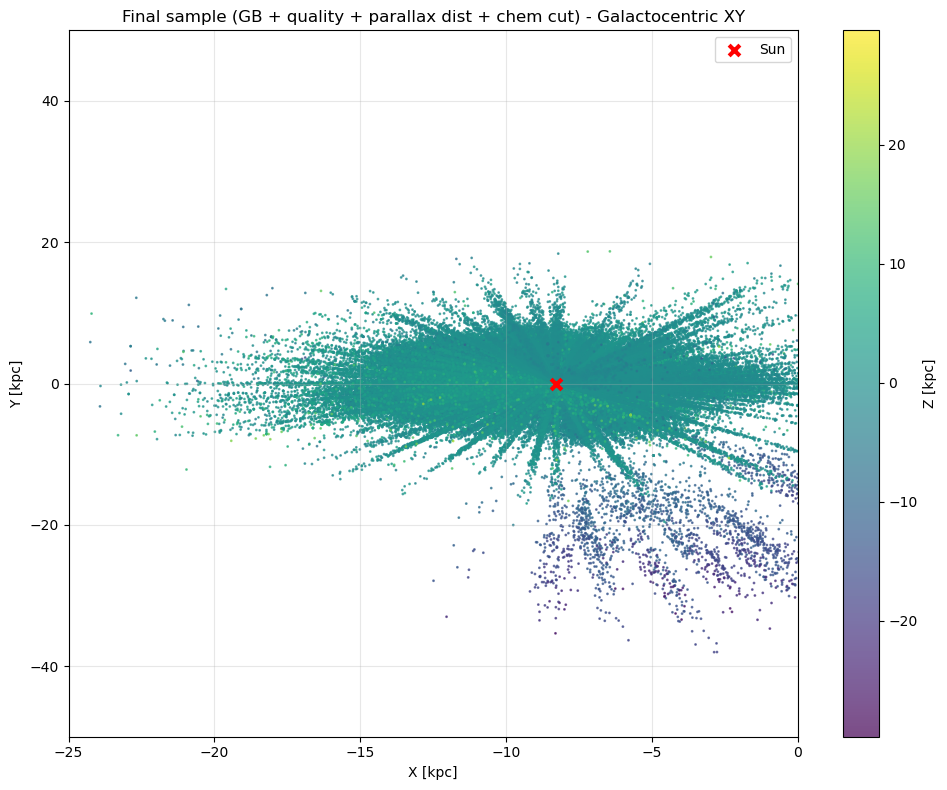

In [9]:
# -----------------------------
# 8) Build SkyCoord using distance from parallax
#    d(pc) = 1000 / plx(mas)
# -----------------------------
plx_sel = np.asarray(t_sel["zgr_plx"], float)  # mas
dist_pc = 1000.0 / plx_sel
dist = Distance(dist_pc * u.pc)

c = SkyCoord(
    ra=np.asarray(t_sel["ra"], float) * u.deg,
    dec=np.asarray(t_sel["dec"], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_sel["pmra"], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_sel["pmde"], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_sel["v_rad"], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)
galcen = c.transform_to(galcen_frame)

x = galcen.x.to_value(u.kpc)
y = galcen.y.to_value(u.kpc)
z = galcen.z.to_value(u.kpc)

# -----------------------------
# 9) Chemistry arrays + alpha dividing line
# -----------------------------
fe   = np.asarray(t_sel["fe_h"], float)
mgfe = np.asarray(t_sel["mg_h"], float) - fe

# Piecewise alpha division (same as your code)
fe_break = -0.1
m1, b1 = -0.05, 0.10
m2 = -0.20
b2 = (m1 * fe_break + b1) - m2 * fe_break  # continuity

def mgfe_dividing_line(feh_vals):
    feh_vals = np.asarray(feh_vals, float)
    return np.where(feh_vals >= fe_break, m1*feh_vals + b1, m2*feh_vals + b2)

# -----------------------------
# 10) APPLY THE CHEMISTRY CUT (THIS IS NEW)
#     Keep ONLY: below alpha line AND [Fe/H] >= -1.2
# -----------------------------
feh_cut = -1.2

finite_alpha = np.isfinite(fe) & np.isfinite(mgfe)
fe0, mgfe0 = fe[finite_alpha], mgfe[finite_alpha]
x0, y0, z0 = x[finite_alpha], y[finite_alpha], z[finite_alpha]

mgfe_div0 = mgfe_dividing_line(fe0)

low_alpha_mask = (mgfe0 < mgfe_div0)       # below the alpha line
metal_mask     = (fe0 >= feh_cut)          # right of vertical line
chem_cut_mask  = low_alpha_mask & metal_mask

# Apply to arrays
fe   = fe0[chem_cut_mask]
mgfe = mgfe0[chem_cut_mask]
x_a, y_a, z_a = x0[chem_cut_mask], y0[chem_cut_mask], z0[chem_cut_mask]

# Apply to the TABLE so everything stays aligned downstream
idx0 = np.where(finite_alpha)[0]
t_sel = t_sel[idx0[chem_cut_mask]]

print(f"After chemistry cut (below alpha & [Fe/H] >= {feh_cut}):", len(t_sel))

# -----------------------------
# 11) Plot 1: XY colored by Z (FINAL SAMPLE)
# -----------------------------
plt.figure(figsize=(10, 8))
plt.scatter(x_a, y_a, c=z_a, s=1, alpha=0.7, cmap="viridis")
plt.colorbar(label="Z [kpc]")
plt.scatter(-8.275, 0, marker="x", s=60, c="red", linewidths=3, label="Sun", zorder=5)

plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.title("Final sample (GB + quality + parallax dist + chem cut) - Galactocentric XY")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(-25, 0)
plt.ylim(-50, 50)
plt.tight_layout()
plt.show()

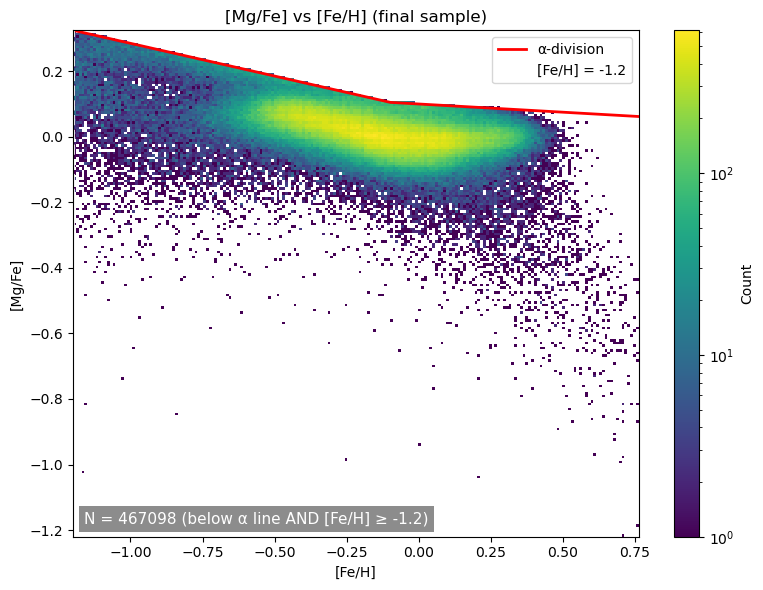

In [10]:
# -----------------------------
# 12) Plot 2: Mg/Fe vs Fe/H + alpha division + vertical line (FINAL SAMPLE)
# -----------------------------
plt.figure(figsize=(8, 6))
plt.hist2d(fe, mgfe, bins=200, norm=LogNorm(), cmap="viridis")
plt.colorbar(label="Count")

fe_grid = np.linspace(np.nanmin(fe), np.nanmax(fe), 500)
plt.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
plt.axvline(feh_cut, color="white", lw=2, ls="--", label=f"[Fe/H] = {feh_cut}")

plt.text(
    0.02, 0.02,
    f"N = {len(fe)} (below α line AND [Fe/H] ≥ {feh_cut})",
    transform=plt.gca().transAxes,
    fontsize=11,
    va="bottom",
    color="white",
    bbox=dict(facecolor="grey", alpha=0.9, edgecolor="none", pad=4),
)

plt.xlabel("[Fe/H]")
plt.ylabel("[Mg/Fe]")
plt.title("[Mg/Fe] vs [Fe/H] (final sample)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

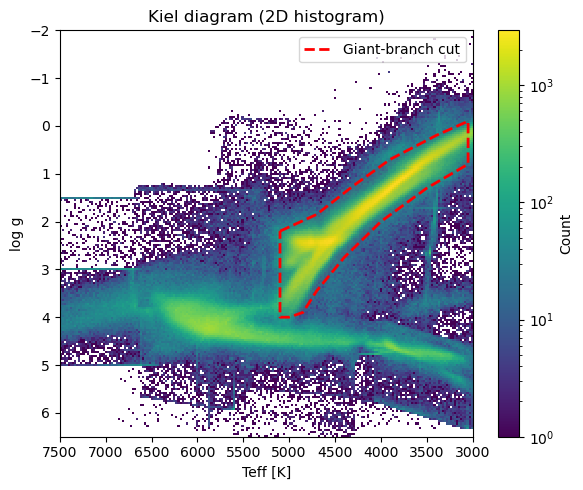

In [11]:
# -----------------------------
# 13) Plot 3: Kiel diagram (FULL SAMPLE) + polygon overlay
# -----------------------------
x_all = teff[finite_basic]
y_all = logg[finite_basic]

plt.figure(figsize=(6, 5))
plt.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
plt.colorbar(label="Count")

plt.xlabel("Teff [K]")
plt.ylabel("log g")
plt.xlim(7500, 3000)
plt.title("Kiel diagram (2D histogram)")

# polygon outline
gb_closed = np.vstack([gb_vertices, gb_vertices[0]])
plt.plot(gb_closed[:, 0], gb_closed[:, 1], "r--", lw=2, label="Giant-branch cut")
plt.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path

# --- Required columns ---
needed = ["al_h", "fe_h", "mg_h", "mn_h"]
missing = [c for c in needed if c not in t_sel.colnames]
if missing:
    raise KeyError(f"Missing columns in t_sel: {missing}. Check t_sel.colnames.")

# --- Axes in FULL t_sel index space ---
alfe_all = np.asarray(t_sel["al_h"], float) - np.asarray(t_sel["fe_h"], float)
mgmn_all = np.asarray(t_sel["mg_h"], float) - np.asarray(t_sel["mn_h"], float)

finite = np.isfinite(alfe_all) & np.isfinite(mgmn_all)

# finite arrays for plotting
x = alfe_all[finite]
y = mgmn_all[finite]

# ------------------------------------------------------------
# IMPORTANT: vertices must go around the perimeter (no crossing)
# This ordering makes a proper quadrilateral = whole red region.
# ------------------------------------------------------------
poly_vertices = np.array([
    [-0.4, -0.25],   # lower-left
    [ 0.15, -0.40],  # lower-right
    [ 0.6,  0.7],  # upper-right
    [-0.2,  0.70],   # upper-left
], dtype=float)

poly_path = Path(poly_vertices, closed=True)

# inside test on finite-only points
pts_finite = np.vstack([x, y]).T
inside_finite = poly_path.contains_points(pts_finite)

# map back to full length of t_sel (alignment-safe)
inside_full = np.zeros(len(t_sel), dtype=bool)
inside_full[np.where(finite)[0]] = inside_finite

# THIS is your polygon-selected sample (every star inside the quad)
t_poly = t_sel[inside_full]

print("t_sel size:", len(t_sel))
print("Finite points:", int(np.sum(finite)))
print("Inside polygon (finite):", int(np.sum(inside_finite)))
print("Inside fraction (finite):", float(np.sum(inside_finite) / np.sum(finite)))
print("t_poly size:", len(t_poly))

# ------------------------------------------------------------
# Plot: density + polygon outline (sanity)
# ------------------------------------------------------------
closed = np.vstack([poly_vertices, poly_vertices[0]])

plt.figure(figsize=(7, 5))
plt.hist2d(x, y, bins=250, norm=LogNorm(), cmap="viridis")
plt.colorbar(label="Count")
plt.plot(closed[:, 0], closed[:, 1], color="red", lw=3)
plt.fill(closed[:, 0], closed[:, 1], color="red", alpha=0.08)
plt.xlabel("[Al/Fe]")
plt.ylabel("[Mg/Mn]")
plt.title("Mg/Mn vs Al/Fe")
plt.tight_layout()
plt.show()


NameError: name 't_sel' is not defined

N(t_final): 391560
Have v_rad: 241314
Have VHELIO_AVG: 112209
Have either RV (used): 353522
  using v_rad: 241314
  using VHELIO_AVG fallback: 112208
Dropped (missing BOTH RVs or bad astrometry): 38038
N stars in phase-space maps: 353522


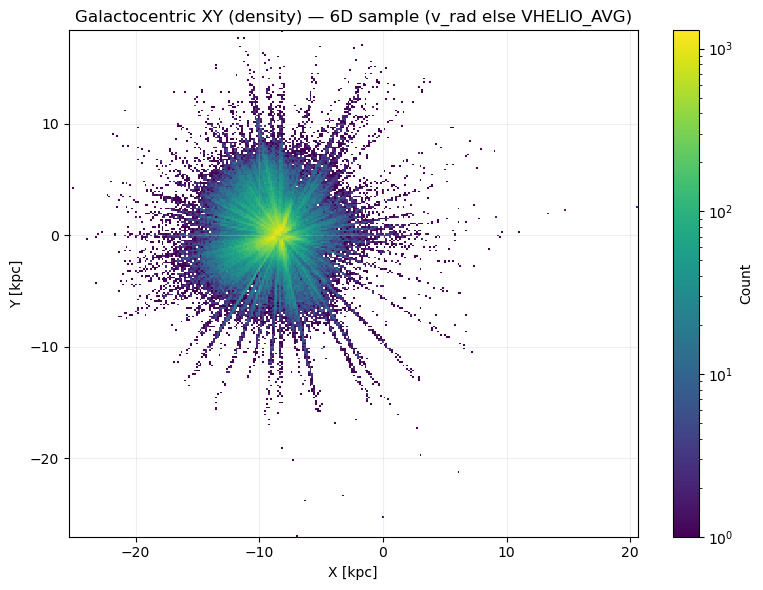

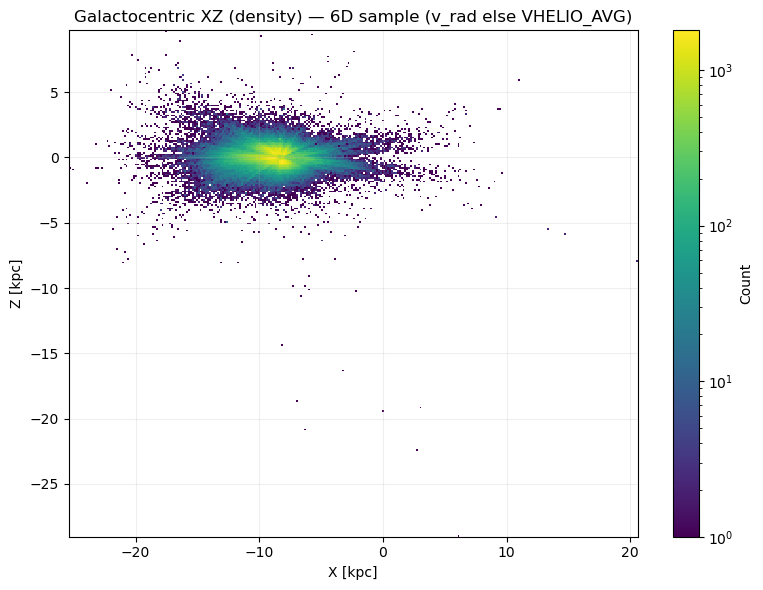

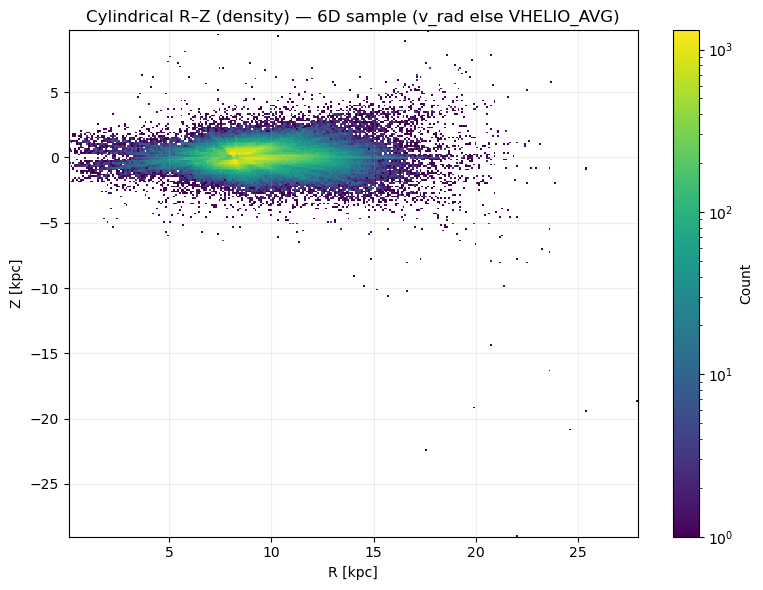

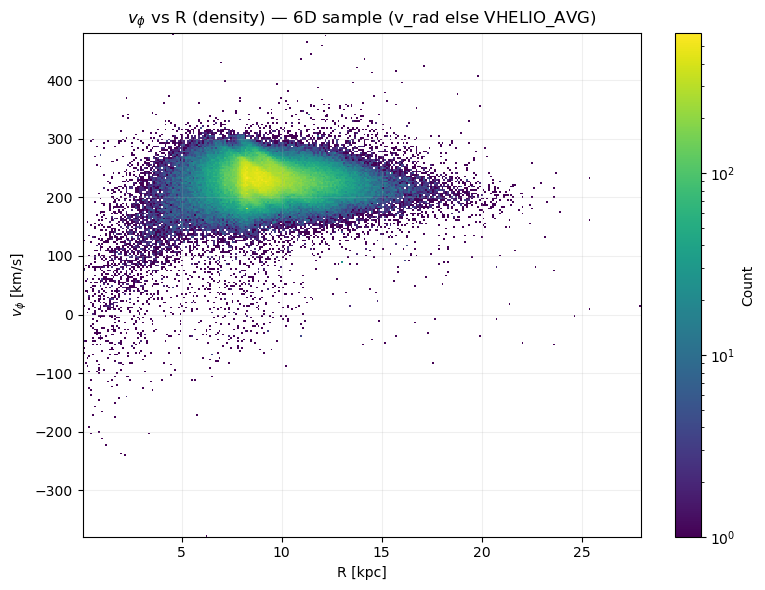

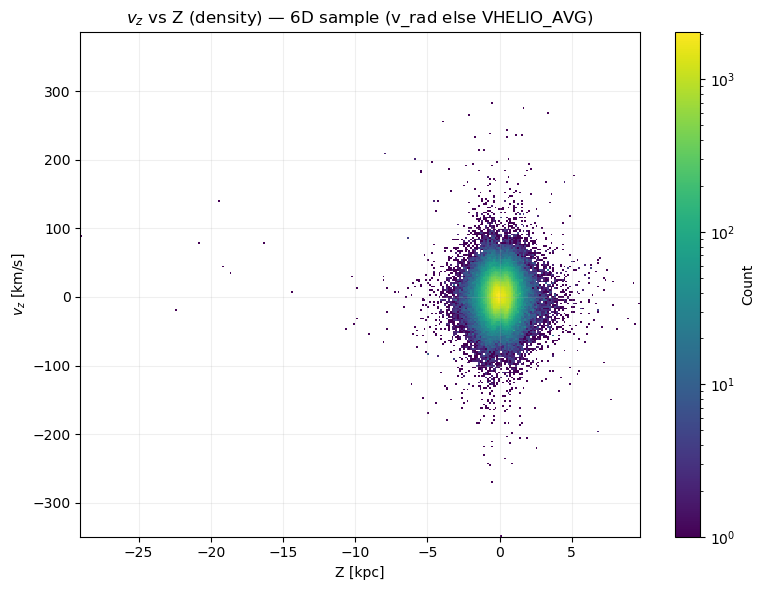

R range [kpc]: 0.05815139938222538 to 27.9500122180219
Z range [kpc]: -29.036534639859834 to 9.723087621420438
Median vphi [km/s]: 228.99589483746533
Median |vz| [km/s]: 12.500386069723945


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# ------------------------------------------------------------
# Input table (your final chemical/polygon/GB selection)
# ------------------------------------------------------------
t_final = t_poly  # or t_sel / t_poly, whichever is your final sample

# ------------------------------------------------------------
# 1) Pull needed columns
# ------------------------------------------------------------
plx  = np.asarray(t_final["zgr_plx"], float)   # mas
ra   = np.asarray(t_final["ra"], float)
dec  = np.asarray(t_final["dec"], float)
pmra = np.asarray(t_final["pmra"], float)
pmde = np.asarray(t_final["pmde"], float)

# Prefer v_rad; if missing/invalid, fall back to VHELIO_AVG
# (Handles masked columns too.)
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):  # MaskedColumn
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

vrad  = col_to_float_array(t_final, "v_rad") if "v_rad" in t_final.colnames else np.full(len(t_final), np.nan)
vhel  = col_to_float_array(t_final, "VHELIO_AVG") if "VHELIO_AVG" in t_final.colnames else np.full(len(t_final), np.nan)

# build "best available" radial velocity
v = np.where(np.isfinite(vrad), vrad, vhel)

# bookkeeping (optional but helpful)
has_vrad = np.isfinite(vrad)
has_vhel = np.isfinite(vhel)
has_v    = np.isfinite(v)

# ------------------------------------------------------------
# 2) Mask: need full 6D (plx>0 + finite pm + finite radial velocity)
# ------------------------------------------------------------
ok6d = (
    np.isfinite(plx) & (plx > 0) &
    np.isfinite(ra) & np.isfinite(dec) &
    np.isfinite(pmra) & np.isfinite(pmde) &
    has_v
)

print("N(t_final):", len(t_final))
print("Have v_rad:", int(np.sum(has_vrad)))
print("Have VHELIO_AVG:", int(np.sum(has_vhel)))
print("Have either RV (used):", int(np.sum(has_v)))
print("  using v_rad:", int(np.sum(ok6d & has_vrad)))
print("  using VHELIO_AVG fallback:", int(np.sum(ok6d & (~has_vrad) & has_vhel)))
print("Dropped (missing BOTH RVs or bad astrometry):", int(np.sum(~ok6d)))

# ------------------------------------------------------------
# 3) Build SkyCoord (6D) and transform
# ------------------------------------------------------------
dist = Distance((1000.0 / plx[ok6d]) * u.pc)

c = SkyCoord(
    ra=ra[ok6d] * u.deg,
    dec=dec[ok6d] * u.deg,
    distance=dist,
    pm_ra_cosdec=pmra[ok6d] * u.mas/u.yr,
    pm_dec=pmde[ok6d] * u.mas/u.yr,
    radial_velocity=v[ok6d] * u.km/u.s,
    frame="icrs",
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

gc = c.transform_to(galcen_frame)

# Cartesian positions/velocities
X  = gc.x.to_value(u.kpc)
Y  = gc.y.to_value(u.kpc)
Z  = gc.z.to_value(u.kpc)
VX = gc.v_x.to_value(u.km/u.s)
VY = gc.v_y.to_value(u.km/u.s)
VZ = gc.v_z.to_value(u.km/u.s)

# ------------------------------------------------------------
# 4) Cylindrical coords + velocities
# ------------------------------------------------------------
R   = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)

good = (
    np.isfinite(R) & (R > 1e-6) &
    np.isfinite(X) & np.isfinite(Y) & np.isfinite(Z) &
    np.isfinite(VX) & np.isfinite(VY) & np.isfinite(VZ)
)
X, Y, Z, VX, VY, VZ, R, phi = X[good], Y[good], Z[good], VX[good], VY[good], VZ[good], R[good], phi[good]

vR   = (X*VX + Y*VY) / R
vphi = (-X*VY + Y*VX) / R
vz   = VZ

print("N stars in phase-space maps:", len(X))

# ------------------------------------------------------------
# 5) Plots
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.hist2d(X, Y, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("X [kpc]"); plt.ylabel("Y [kpc]")
plt.title("Galactocentric XY (density) — 6D sample (v_rad else VHELIO_AVG)")
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
plt.hist2d(X, Z, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("X [kpc]"); plt.ylabel("Z [kpc]")
plt.title("Galactocentric XZ (density) — 6D sample (v_rad else VHELIO_AVG)")
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
plt.hist2d(R, Z, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("R [kpc]"); plt.ylabel("Z [kpc]")
plt.title("Cylindrical R–Z (density) — 6D sample (v_rad else VHELIO_AVG)")
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
plt.hist2d(R, vphi, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("R [kpc]"); plt.ylabel(r"$v_\phi$ [km/s]")
plt.title(r"$v_\phi$ vs R (density) — 6D sample (v_rad else VHELIO_AVG)")
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
plt.hist2d(Z, vz, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("Z [kpc]"); plt.ylabel(r"$v_z$ [km/s]")
plt.title(r"$v_z$ vs Z (density) — 6D sample (v_rad else VHELIO_AVG)")
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

print("R range [kpc]:", np.nanmin(R), "to", np.nanmax(R))
print("Z range [kpc]:", np.nanmin(Z), "to", np.nanmax(Z))
print("Median vphi [km/s]:", np.nanmedian(vphi))
print("Median |vz| [km/s]:", np.nanmedian(np.abs(vz)))

In [14]:
import numpy as np

# make sure this is the table you want to cut RIGHT NOW
# t_final = t_poly   # (example) set it explicitly if needed

def col_as_float(table, name):
    """Return column as float array, handling MaskedColumn."""
    col = table[name]
    if hasattr(col, "filled"):
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

# pull columns from CURRENT t_final
plx  = col_as_float(t_final, "zgr_plx")
ra   = col_as_float(t_final, "ra")
dec  = col_as_float(t_final, "dec")
pmra = col_as_float(t_final, "pmra")
pmde = col_as_float(t_final, "pmde")

v_rad = col_as_float(t_final, "v_rad")
v_hel = col_as_float(t_final, "VHELIO_AVG") if "VHELIO_AVG" in t_final.colnames else np.full(len(t_final), np.nan)

has_v = np.isfinite(v_rad) | np.isfinite(v_hel)

ok6d = (
    np.isfinite(plx) & (plx > 0) &
    np.isfinite(ra) & np.isfinite(dec) &
    np.isfinite(pmra) & np.isfinite(pmde) &
    has_v
)

t_final = t_final

print("len(t_final):", len(t_final))
print("len(ok6d):", len(ok6d))

len(t_final): 391560
len(ok6d): 391560


Parallax-valid stars: 388970 / 391560
N used for annuli plot (after parallax+astrometry finite): 388970
Stopping: reached 2 consecutive annuli with N < 100 at R~[19.0,19.5)
Plotted 36 annuli (dR=0.5) with minN=100.


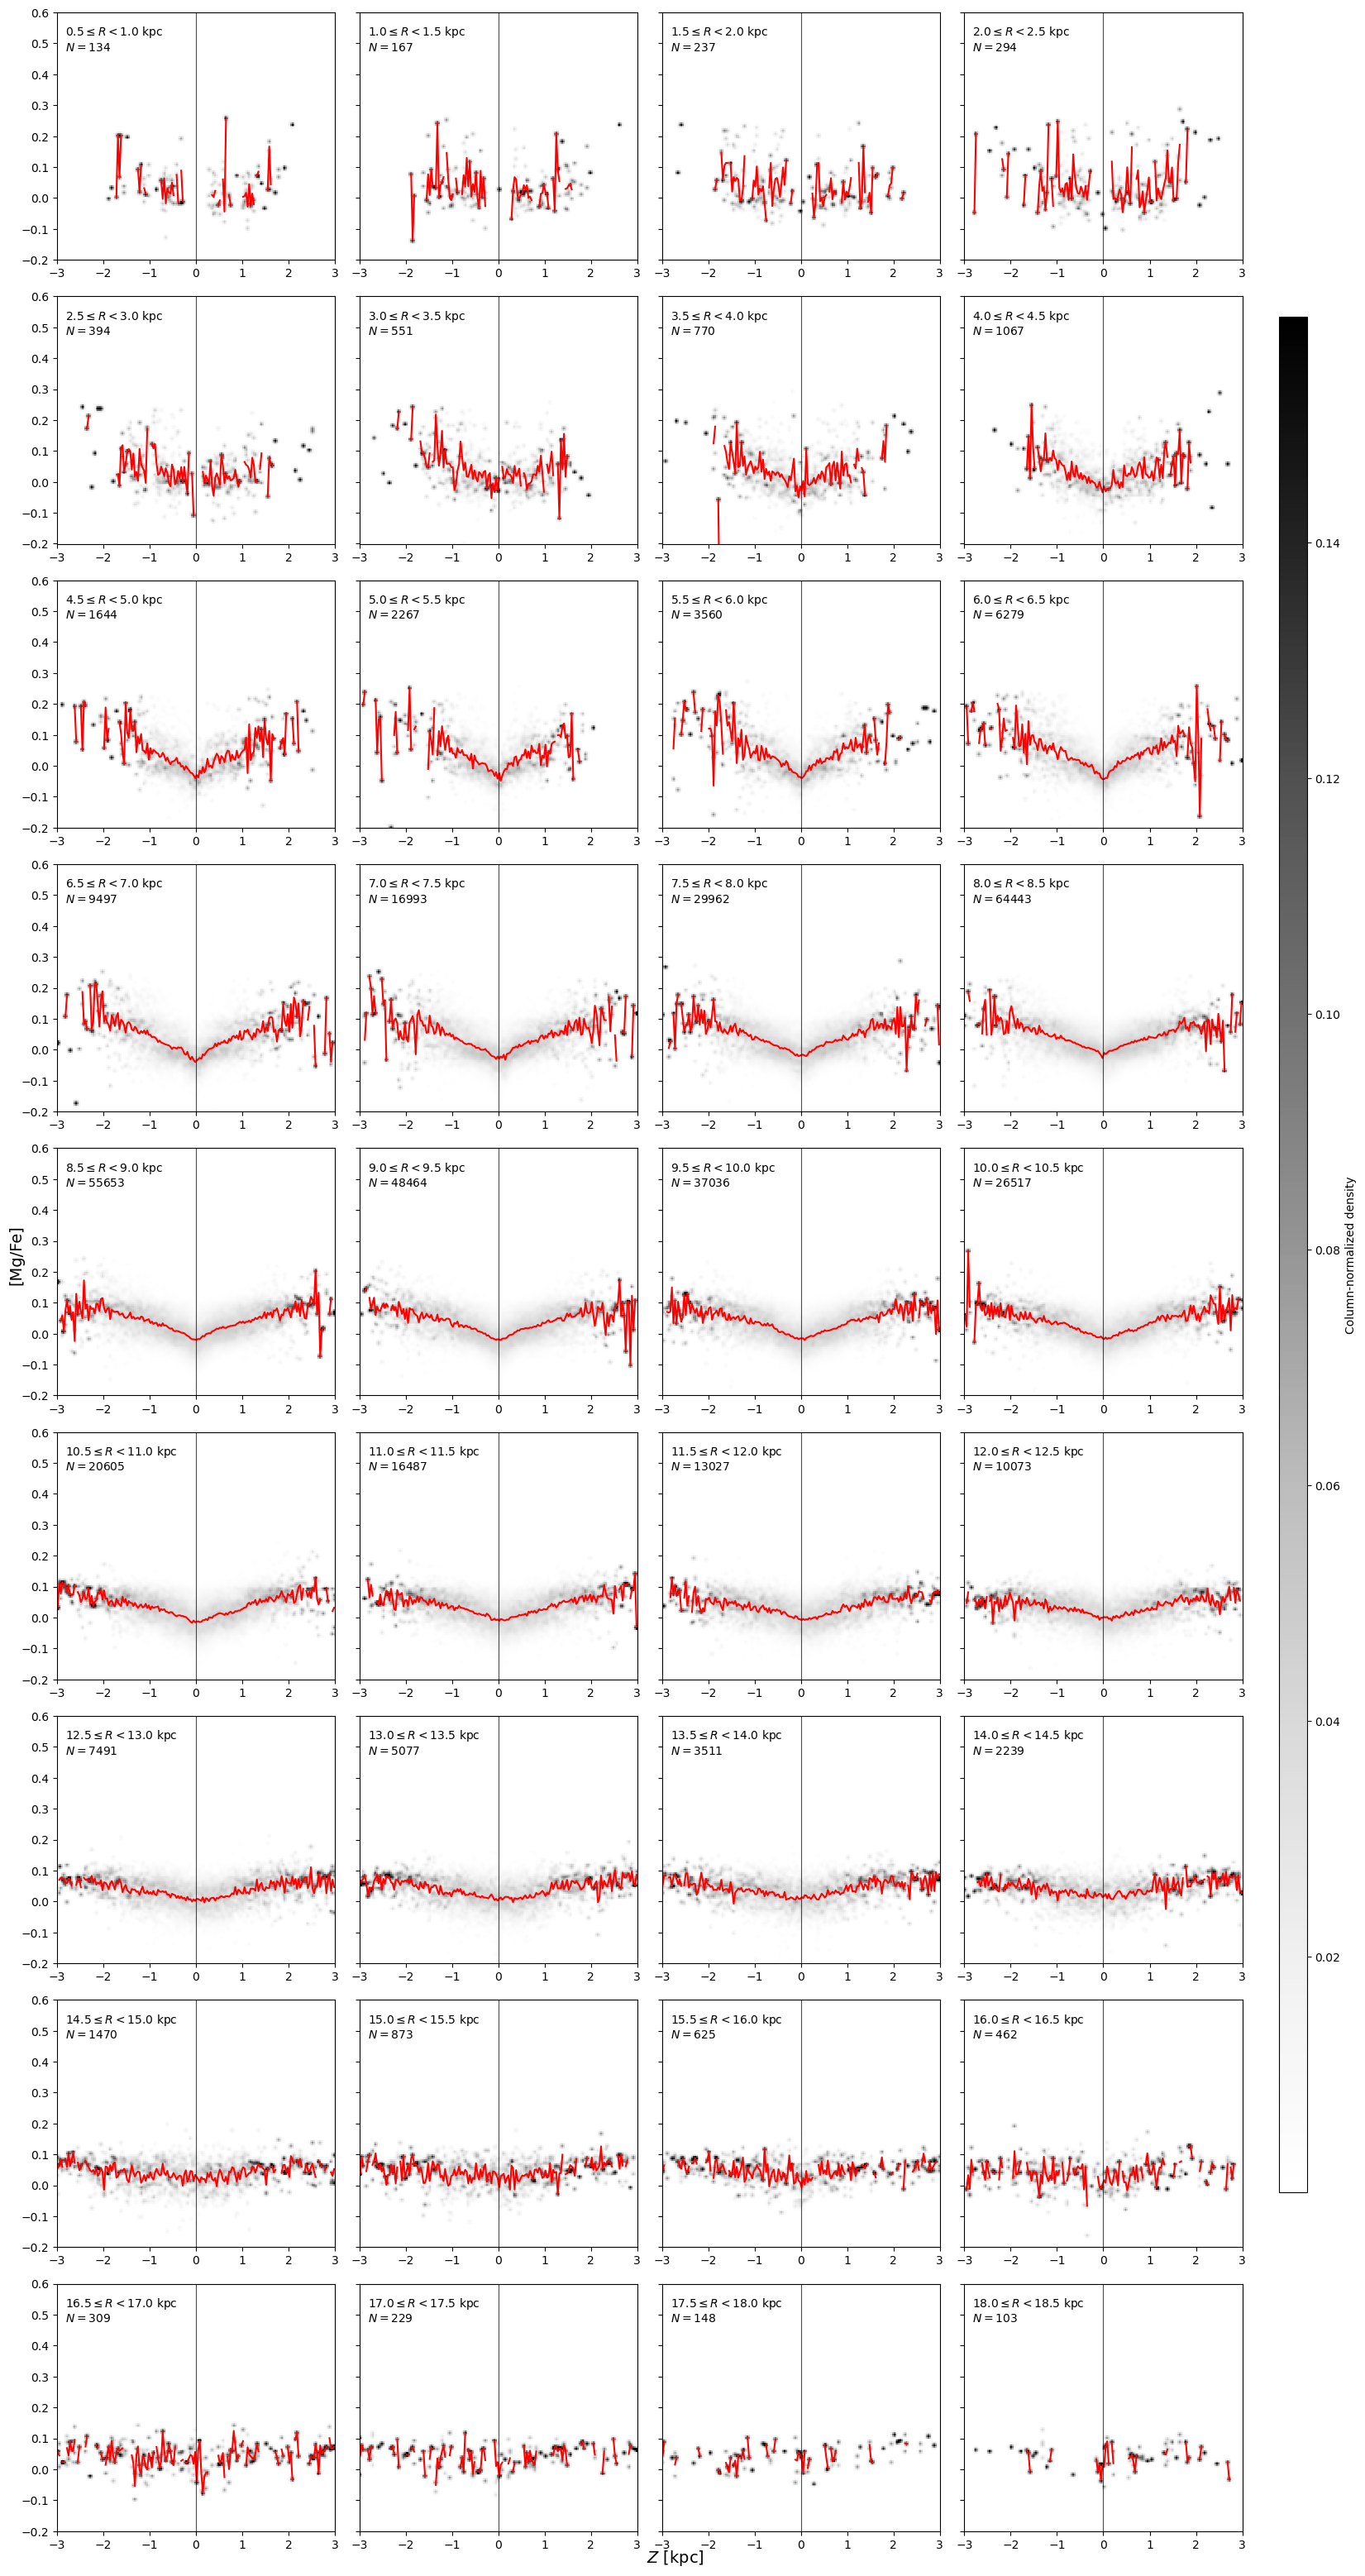

In [15]:
# ============================================================
# FULL annuli multi-panel plot (robust stop rule) — works with your NEW cuts
#   - assumes you already have t_final = t_poly (or whichever is final)
#   - uses zgr_plx parallax for distance (1/parallax)
#   - builds Galactocentric X,Y,Z -> R_all, Z_all
#   - makes multi-panel annuli plot of P(Mg/Fe | Z) + binned mean Mg/Fe(Z)
#   - STOP RULE FIXED: will NOT stop until it has seen at least one good annulus
#   - FIXED subplot error: no duplicate width_ratios / gridspec_kw
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance


# ============================================================
# 1) Distances from zgr_plx (parallax)  ->  d = 1 / parallax
#    ASSUMPTION: zgr_plx is in mas (common). If it's in arcsec, set plx_unit="arcsec"
# ============================================================
plx = np.asarray(t_final["zgr_plx"], float)

plx_unit = "mas"   # "mas" or "arcsec"
plx_snr_min = 5.0  # optional quality (helps a LOT). Set to 0 to disable.

# If you have parallax errors:
has_eplx = ("zgr_e_plx" in t_final.colnames)  # adjust name if yours differs

if has_eplx:
    eplx = np.asarray(t_final["zgr_e_plx"], float)
else:
    eplx = None

# Convert parallax to arcsec for Distance(parallax=...)
if plx_unit == "mas":
    plx_arcsec = plx / 1000.0
    if eplx is not None:
        eplx_arcsec = eplx / 1000.0
    else:
        eplx_arcsec = None
elif plx_unit == "arcsec":
    plx_arcsec = plx
    eplx_arcsec = eplx
else:
    raise ValueError("plx_unit must be 'mas' or 'arcsec'")

# Basic parallax validity
parallax_mask = np.isfinite(plx_arcsec) & (plx_arcsec > 0)

# Optional: parallax SNR cut if error exists
if eplx_arcsec is not None and plx_snr_min > 0:
    parallax_mask &= np.isfinite(eplx_arcsec) & (eplx_arcsec > 0) & ((plx_arcsec / eplx_arcsec) >= plx_snr_min)

print("Parallax-valid stars:", int(np.sum(parallax_mask)), "/", len(t_final))

# Apply parallax mask to everything we use downstream
t_use = t_final[parallax_mask]

# ============================================================
# 2) Build SkyCoord and transform to Galactocentric
# ============================================================
dist = Distance(parallax=plx_arcsec[parallax_mask] * u.arcsec)

c = SkyCoord(
    ra=np.asarray(t_use["ra"], float) * u.deg,
    dec=np.asarray(t_use["dec"], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_use["pmra"], float) * u.mas / u.yr,
    pm_dec=np.asarray(t_use["pmde"], float) * u.mas / u.yr,
    radial_velocity=np.asarray(t_use["v_rad"], float) * u.km / u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km / u.s,
)

gc = c.transform_to(galcen_frame)

X_all = gc.x.to_value(u.kpc)
Y_all = gc.y.to_value(u.kpc)
Z_all = gc.z.to_value(u.kpc)
R_all = np.sqrt(X_all**2 + Y_all**2)

mgfe_all = (np.asarray(t_use["mg_h"], float) - np.asarray(t_use["fe_h"], float))

# Basic finiteness
finite_all = np.isfinite(R_all) & np.isfinite(Z_all) & np.isfinite(mgfe_all)
R_all = R_all[finite_all]
Z_all = Z_all[finite_all]
mgfe_all = mgfe_all[finite_all]

print("N used for annuli plot (after parallax+astrometry finite):", len(R_all))

# ============================================================
# 3) Multi-panel annuli grid (STOP when N < minN) — FIXED
# ============================================================
dR = 0.5
minN = 100

# stop rule: require this many consecutive low-N annuli before stopping
stop_after_k_consecutive_lowN = 2

# (Optional) If you ONLY want to plot out to some max radius:
R_max_plot = None  # e.g. 16.0 ; set to None to use full

cmap_name = "Greys"

z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
z_centers  = 0.5 * (z_edges[:-1] + z_edges[1:])

smooth_sigma = (1.0, 1.0)
vmin_pct, vmax_pct = 2.0, 99.7

Rmin_data = np.nanmin(R_all)
Rmax_data = np.nanmax(R_all)

Rstart = np.floor(Rmin_data / dR) * dR
Rstop  = np.ceil(Rmax_data / dR) * dR
if R_max_plot is not None:
    Rstop = min(Rstop, R_max_plot)

annuli = []
imgs = []
mean_trends = []
Ns = []

lowN_streak = 0
seen_good = False  # <-- critical fix: don't stop until we've seen one good annulus

for Rmin in np.arange(Rstart, Rstop, dR):
    Rmax = Rmin + dR
    m = (R_all >= Rmin) & (R_all < Rmax)
    N = int(np.sum(m))

    if N < minN:
        if seen_good:
            lowN_streak += 1
            if lowN_streak >= stop_after_k_consecutive_lowN:
                print(f"Stopping: reached {lowN_streak} consecutive annuli with N < {minN} at R~[{Rmin:.1f},{Rmax:.1f})")
                break
        # If we haven't seen any good annulus yet, do NOT stop; keep going.
        continue
    else:
        seen_good = True
        lowN_streak = 0

    Z = Z_all[m]
    mgfe = mgfe_all[m]

    finite = np.isfinite(Z) & np.isfinite(mgfe)
    Z = Z[finite]
    mgfe = mgfe[finite]
    N = int(len(Z))
    if N < minN:
        continue

    # Column-normalized histogram P(Mg/Fe | Z)
    H, _, _ = np.histogram2d(Z, mgfe, bins=[z_edges, mgfe_edges])
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm  = np.divide(H, colsum, out=np.zeros_like(H), where=(colsum > 0))
    img = gaussian_filter(Hnorm, sigma=smooth_sigma).T

    # Mean Mg/Fe trend in each Z bin
    trend = np.full_like(z_centers, np.nan, dtype=float)
    for i in range(len(z_edges) - 1):
        mm = (Z >= z_edges[i]) & (Z < z_edges[i+1])
        if np.any(mm):
            trend[i] = np.nanmean(mgfe[mm])

    annuli.append((Rmin, Rmax))
    imgs.append(img)
    mean_trends.append(trend)
    Ns.append(N)

print(f"Plotted {len(annuli)} annuli (dR={dR}) with minN={minN}.")

if len(annuli) == 0:
    raise RuntimeError(
        "No annuli met minN after parallax filtering. "
        "Try lowering minN, relaxing parallax SNR, or verify zgr_plx units."
    )

# ============================================================
# 4) Shared color scale across panels
# ============================================================
vals = np.concatenate([img[(img > 0) & np.isfinite(img)] for img in imgs])
if len(vals) > 0:
    vmin, vmax = np.percentile(vals, [vmin_pct, vmax_pct])
else:
    vmin, vmax = 0.0, 1.0

# ============================================================
# 5) Plot grid
# ============================================================
n_panels = len(annuli)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2 * ncols, 3.6 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

pcm = None

for i, ax in enumerate(axes.flat):
    if i >= n_panels:
        ax.axis("off")
        continue

    Rmin, Rmax = annuli[i]
    img = imgs[i]
    trend = mean_trends[i]
    N = Ns[i]

    pcm = ax.pcolormesh(
        z_edges, mgfe_edges, img,
        shading="auto",
        vmin=vmin, vmax=vmax,
        cmap=cmap_name
    )

    ax.plot(z_centers, trend, color="red", lw=1.5)
    ax.axvline(0, color="k", lw=0.8, alpha=0.7)

    ax.text(
        0.03, 0.95,
        rf"${Rmin:.1f}\leq R<{Rmax:.1f}$ kpc" + "\n" + rf"$N={N}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.6)
    ax.tick_params(axis="x", which="both", labelbottom=True)

fig.supxlabel(r"$Z$ [kpc]", fontsize=14)
fig.supylabel(r"[Mg/Fe]", fontsize=14)

fig.tight_layout(rect=[0.0, 0.0, 0.92, 0.97])
cax = fig.add_axes([0.935, 0.15, 0.02, 0.70])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Column-normalized density")

plt.show()

In [16]:
# ============================================================
# CANONICAL STAR PACK (one place to define the arrays you will use)
# ============================================================
import numpy as np
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# Pick ONE final table and stick with it:
t_use = t_final    # or t_sel, or t_final — choose ONE

# --- parallax distance mask ---
plx = np.asarray(t_use["zgr_plx"], float)  # mas
plx_ok = np.isfinite(plx) & (plx > 0)

# (optional) safety rail
# plx_ok &= (plx >= 0.02)

t_use = t_use[plx_ok]
dist = Distance((1000.0 / np.asarray(t_use["zgr_plx"], float)) * u.pc)

# --- build SkyCoord ---
galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

c = SkyCoord(
    ra=np.asarray(t_use["ra"], float) * u.deg,
    dec=np.asarray(t_use["dec"], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_use["pmra"], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_use["pmde"], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_use["v_rad"], float) * u.km/u.s,
)

gc = c.transform_to(galcen_frame)

# --- coords ---
X_all = gc.x.to_value(u.kpc)
Y_all = gc.y.to_value(u.kpc)
Z_all = gc.z.to_value(u.kpc)
R_all = np.sqrt(X_all**2 + Y_all**2)
phi_all = np.arctan2(Y_all, X_all)

# --- chemistry (SAME t_use, same length) ---
mgfe_all = np.asarray(t_use["mg_h"], float) - np.asarray(t_use["fe_h"], float)

# --- final finiteness ---
finite = (
    np.isfinite(X_all) & np.isfinite(Y_all) & np.isfinite(Z_all) &
    np.isfinite(R_all) & np.isfinite(phi_all) & np.isfinite(mgfe_all)
)

X_star   = X_all[finite]
Y_star   = Y_all[finite]
Z_star   = Z_all[finite]
R_star   = R_all[finite]
phi_star = phi_all[finite]
mgfe_star = mgfe_all[finite]

# --- optional max radius cut (keep this if you want) ---
Rmax_keep = 16.0
mRmax = (R_star < Rmax_keep)

X_star   = X_star[mRmax]
Y_star   = Y_star[mRmax]
Z_star   = Z_star[mRmax]
R_star   = R_star[mRmax]
phi_star = phi_star[mRmax]
mgfe_star = mgfe_star[mRmax]

print("Lengths:", len(R_star), len(Z_star), len(phi_star), len(mgfe_star))
assert len(R_star) == len(mgfe_star) == len(phi_star) == len(Z_star)


Lengths: 389650 389650 389650 389650


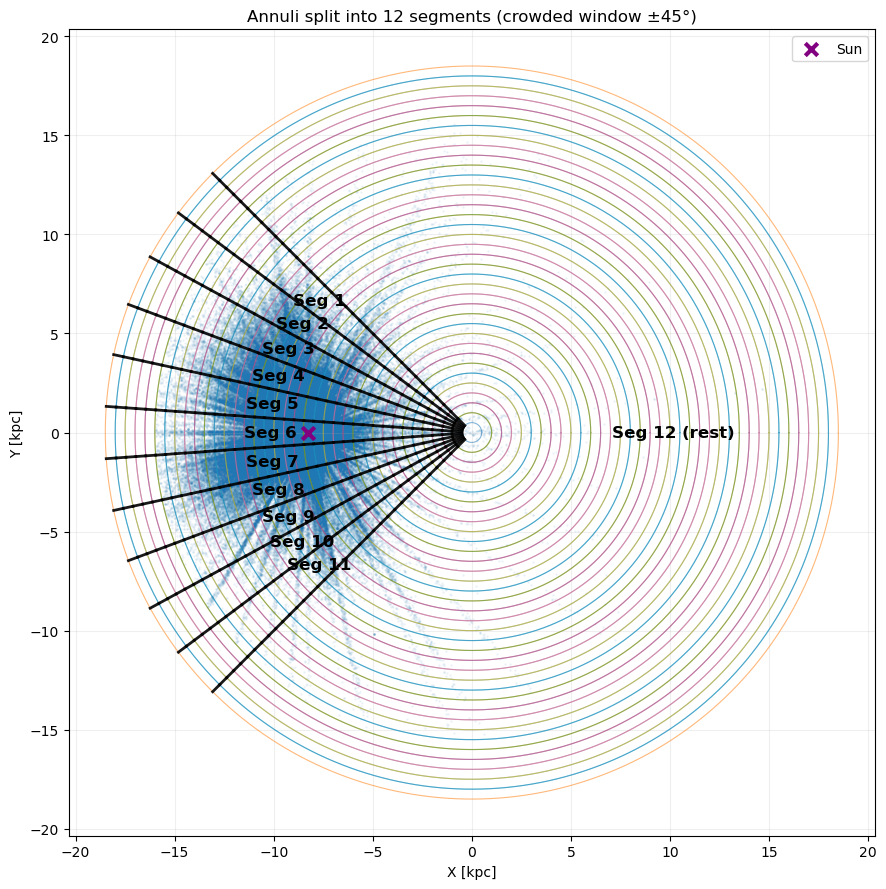

In [17]:
# ============================================================
# SECTION 1: DEFINE 11+1 SEGMENTS (11 crowded wedges + 1 rest)
#            + PLOT THE SEGMENT GEOMETRY ON XY WITH ANNULI
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# USER SETTINGS (SEGMENT GEOMETRY)
# ----------------------------
phi0 = np.pi                 # crowded direction
crowd_halfwidth_deg = 45     # +/- degrees around phi0 = crowded window
n_crowd = 11                 # number of wedges inside crowded window
seg_rest_id = n_crowd + 1    # rest segment id (12)

# choose which segments you will later analyze/store:
#   - crowded only (1..11): recommended if you want to ignore "rest"
SEG_PLOT = list(range(1, n_crowd + 1))
#   - OR include rest too:
# SEG_PLOT = list(range(1, n_crowd + 2))  # 1..12

def wrap_to_2pi(a):
    return np.mod(a, 2*np.pi)

def between_ccw(x, a, b):
    da = (b - a) % (2*np.pi)
    dx = (x - a) % (2*np.pi)
    return dx < da

def segment_masks_ncrowd(phi, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11):
    """
    Returns:
      segm: dict {1..n_crowd, n_crowd+1(rest)} boolean masks
      crowd_bounds: boundary angles (len n_crowd+1) spanning crowded window CCW
      (a,b): crowded window edges
    """
    ph = wrap_to_2pi(phi)
    phi0 = wrap_to_2pi(phi0)

    hw = np.deg2rad(crowd_halfwidth_deg)
    a = wrap_to_2pi(phi0 - hw)
    b = wrap_to_2pi(phi0 + hw)

    span = (b - a) % (2*np.pi)
    crowd_bounds = wrap_to_2pi(a + np.linspace(0, span, n_crowd + 1))

    segm = {}
    for i in range(n_crowd):
        segm[i+1] = between_ccw(ph, crowd_bounds[i], crowd_bounds[i+1])

    in_crowd = between_ccw(ph, a, b)
    segm[n_crowd+1] = ~in_crowd  # rest
    return segm, crowd_bounds, (a, b)

# sanity check (should now match)
assert len(mgfe_all) == len(X_all)

##### ------------------------------------------------------------
# REQUIRE: X_star, Y_star, phi_star, and annuli exist already
# (X_star/Y_star/phi_star are your star arrays after your cuts)
# annuli = list of (Rmin,Rmax) you kept (or use your full annuli list)
# ------------------------------------------------------------
segm, crowd_bounds, (a, b) = segment_masks_ncrowd(
    phi_star, phi0=phi0, crowd_halfwidth_deg=crowd_halfwidth_deg, n_crowd=n_crowd
)

# sanity check
for sid in range(1, n_crowd+2):
    assert len(segm[sid]) == len(phi_star), f"segm[{sid}] length mismatch"

# ------------------------------------------------------------
# PLOT SEGMENT LINES + ANNULI ON XY
# ------------------------------------------------------------
plt.figure(figsize=(9, 9))
plt.scatter(X_star, Y_star, s=1, alpha=0.05, zorder=1)

theta = np.linspace(0, 2*np.pi, 800)

# if you want to plot only a subset of annuli for clarity, slice annuli[:N]
for (Rmin, Rmax) in annuli:
    # annulus circles
    plt.plot(Rmin*np.cos(theta), Rmin*np.sin(theta), lw=0.8, alpha=0.55, zorder=2)
    plt.plot(Rmax*np.cos(theta), Rmax*np.sin(theta), lw=0.8, alpha=0.55, zorder=2)

    # draw crowded-region boundaries
    for ang in crowd_bounds:
        plt.plot([Rmin*np.cos(ang), Rmax*np.cos(ang)],
                 [Rmin*np.sin(ang), Rmax*np.sin(ang)],
                 color="k", lw=2.0, alpha=0.90, zorder=3)

# label segments at a representative radius
R_label = np.median([r[0] for r in annuli]) * 1.1

# midpoints for the n_crowd wedges
mid_angles = []
for i in range(n_crowd):
    ang0 = crowd_bounds[i]
    ang1 = crowd_bounds[i+1]
    d = (ang1 - ang0) % (2*np.pi)
    mid_angles.append((ang0 + 0.5*d) % (2*np.pi))

# midpoint for the complement arc (rest)
comp_span = (a - b) % (2*np.pi)  # CCW distance b->a
mid_rest = (b + 0.5*comp_span) % (2*np.pi)

for i, mid in enumerate(mid_angles, start=1):
    plt.text(R_label*np.cos(mid), R_label*np.sin(mid),
             f"Seg {i}", fontsize=12, weight="bold",
             ha="center", va="center")

plt.text(R_label*np.cos(mid_rest), R_label*np.sin(mid_rest),
         f"Seg {seg_rest_id} (rest)", fontsize=12, weight="bold",
         ha="center", va="center")

# Sun marker (optional)
R0 = 8.275
plt.scatter(-R0, 0, marker="x", s=80, c="purple", linewidths=3, zorder=5, label="Sun")

plt.gca().set_aspect("equal", "box")
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.title(f"Annuli split into {n_crowd+1} segments (crowded window ±{crowd_halfwidth_deg}°)")
plt.grid(alpha=0.2)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


In [18]:

# ============================================================
# CANONICAL BUILD: stars + segments must be built together
# ============================================================

# 1) (re)build your final star arrays (these must all match)
# (Use exactly ONE final table)
t_use = t_final   # <-- choose ONE: t_poly or t_sel etc.

plx = np.asarray(t_use["zgr_plx"], float)
plx_ok = np.isfinite(plx) & (plx > 0)
t_use = t_use[plx_ok]

dist = Distance((1000.0/np.asarray(t_use["zgr_plx"], float)) * u.pc)

c = SkyCoord(
    ra=np.asarray(t_use["ra"], float) * u.deg,
    dec=np.asarray(t_use["dec"], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_use["pmra"], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_use["pmde"], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_use["v_rad"], float) * u.km/u.s,
)

gc = c.transform_to(galcen_frame)

X = gc.x.to_value(u.kpc)
Y = gc.y.to_value(u.kpc)
Z = gc.z.to_value(u.kpc)
R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)
mgfe = np.asarray(t_use["mg_h"], float) - np.asarray(t_use["fe_h"], float)

# 2) finiteness cut (apply to ALL arrays)
finite = np.isfinite(X) & np.isfinite(Y) & np.isfinite(Z) & np.isfinite(R) & np.isfinite(phi) & np.isfinite(mgfe)
X_star, Y_star, Z_star, R_star, phi_star, mgfe_star = X[finite], Y[finite], Z[finite], R[finite], phi[finite], mgfe[finite]

# 3) apply your Rmax_keep cut (apply to ALL arrays)
Rmax_keep = 16.0
mRmax = (R_star < Rmax_keep)
X_star, Y_star, Z_star, R_star, phi_star, mgfe_star = (
    X_star[mRmax], Y_star[mRmax], Z_star[mRmax], R_star[mRmax], phi_star[mRmax], mgfe_star[mRmax]
)

print("Final lengths:", len(R_star), len(phi_star), len(mgfe_star))
assert len(R_star) == len(phi_star) == len(mgfe_star) == len(Z_star)

# 4) NOW build segments from THIS phi_star (do not filter afterwards!)
segm, crowd_bounds, (a, b) = segment_masks_ncrowd(
    phi_star, phi0=phi0, crowd_halfwidth_deg=crowd_halfwidth_deg, n_crowd=n_crowd
)
for sid in SEG_PLOT:
    assert len(segm[sid]) == len(R_star), f"segm[{sid}] mismatch"
print("segm lengths OK")


Final lengths: 389650 389650 389650
segm lengths OK


In [19]:
print("len(R_star)   =", len(R_star))
print("len(phi_star) =", len(phi_star))
for s in SEG_PLOT[:3]:
    print(f"len(segm[{s}]) =", len(segm[s]))


len(R_star)   = 389650
len(phi_star) = 389650
len(segm[1]) = 389650
len(segm[2]) = 389650
len(segm[3]) = 389650


Annulus 13.5–14.0 kpc: Ntot = 3635


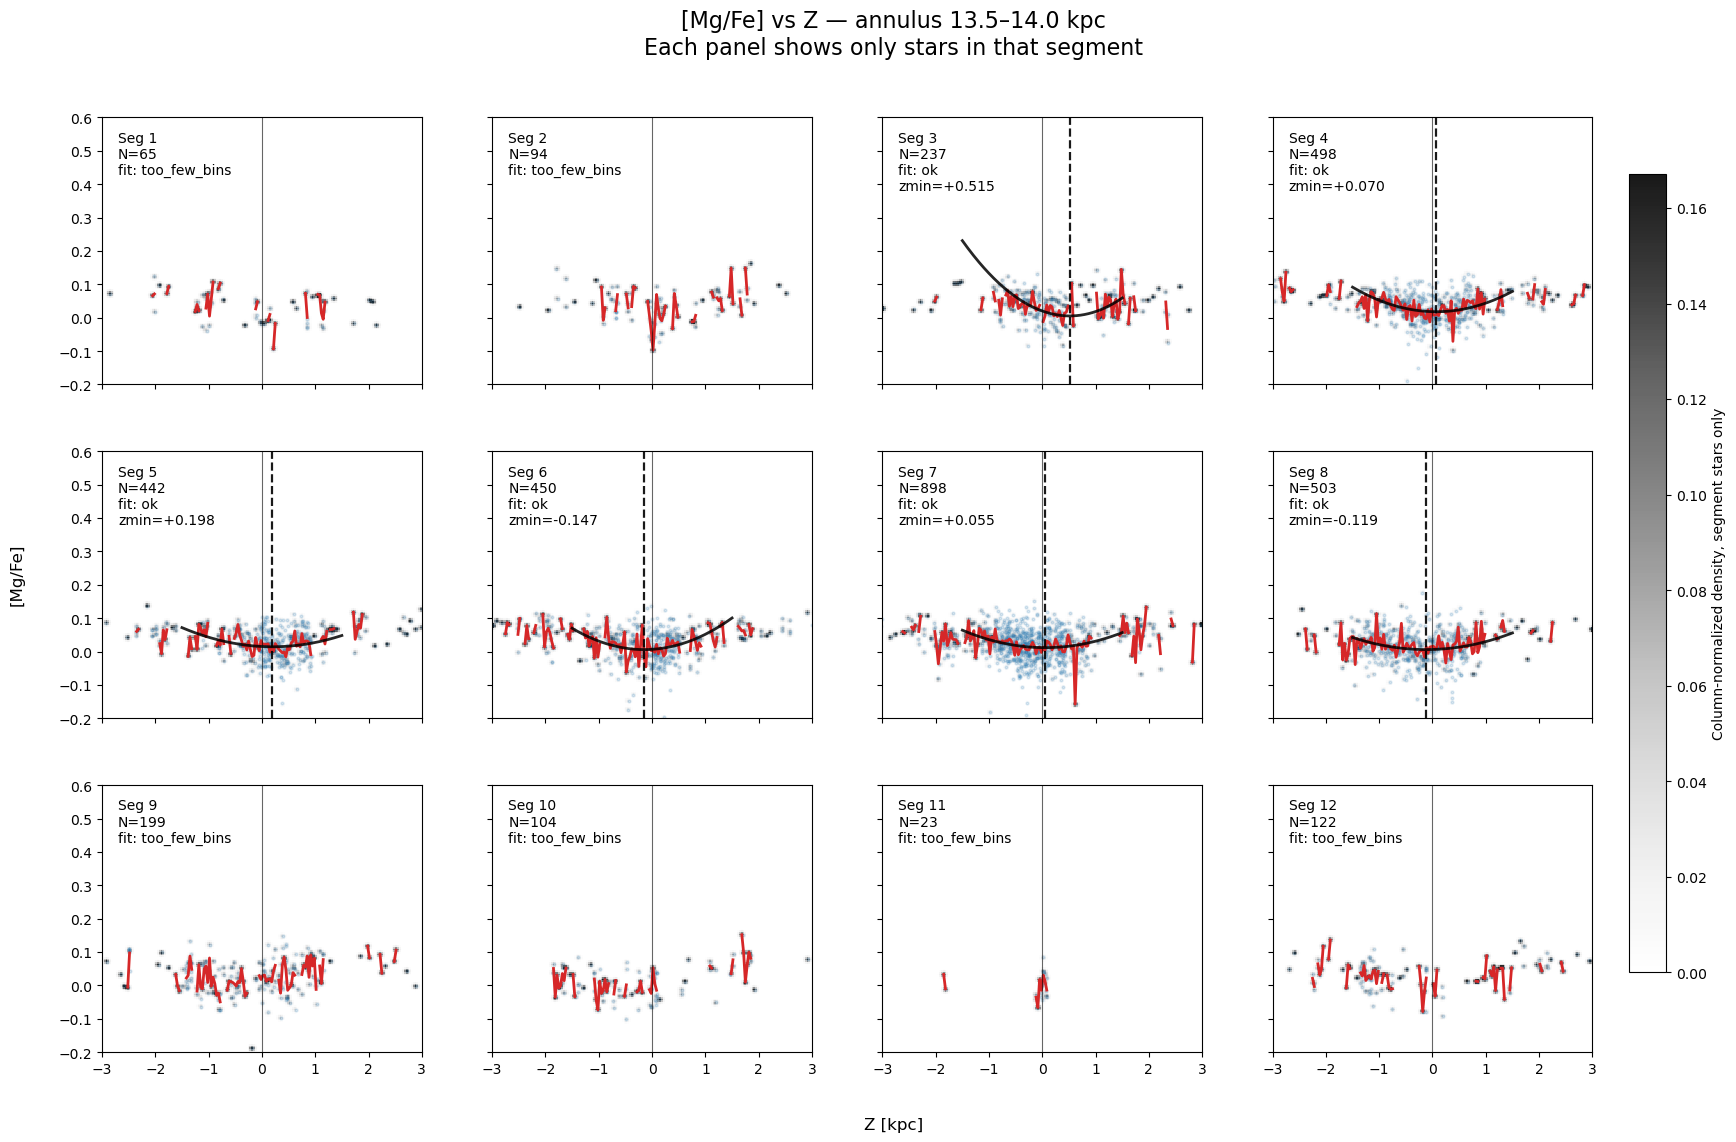

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

Rmin_focus, Rmax_focus = 13.5, 14.0


SEG_PLOT = list(range(1, n_crowd + 2))  # 1..(n_crowd+1)

minN_seg_total = 10     # need at least this many stars in segment to fit
min_bin_count  = 5      # need at least this many stars per Z-bin to use it in mean trend

# quadratic fit window
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8

# background smoothing
smooth_sigma_img = (1.0, 1.0)

# plot ranges
xlim = (-3, 3)
ylim = (-0.2, 0.6)

# ============================
# HELPERS
# ============================
def binned_mean_and_counts(Zs, Ys, z_edges):
    nb = len(z_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Zs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])
    return mean, cnt

def quad_fit_on_trend(z_centers, trend, cnt, zmin=z_fit_min, zmax=z_fit_max,
                      min_cnt=min_bin_count, min_bins=min_bins_for_fit):
    """
    Fit y = a z^2 + b z + c to trend within [zmin,zmax],
    requiring cnt>=min_cnt and finite trend.
    Returns: (a,b,c), status, z0_min
    """
    zc = np.asarray(z_centers)
    tr = np.asarray(trend)
    cnt = np.asarray(cnt)

    m = (zc >= zmin) & (zc <= zmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan

    x = zc[m]
    y = tr[m]

    a, b, c = np.polyfit(x, y, deg=2)

    # need upward-opening parabola for a minimum
    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan

    z0 = -b/(2*a)
    if not (zmin <= z0 <= zmax):
        return (a, b, c), "min_outside_window", np.nan

    return (a, b, c), "ok", float(z0)

# ============================
# 1) SELECT ANNULUS STARS
# ============================
mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
Ntot = int(np.sum(mR))
print(f"Annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc: Ntot = {Ntot}")

if Ntot == 0:
    raise RuntimeError("No stars in that annulus (check R_star units / cuts).")

Zr_all = Z_star[mR]
mgr_all = mgfe_star[mR]
good_bg = np.isfinite(Zr_all) & np.isfinite(mgr_all)
Zr_all = Zr_all[good_bg]
mgr_all = mgr_all[good_bg]

# ============================
# 2) PRECOMPUTE PER-SEGMENT IMAGES
# ============================

z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

seg_images = {}
seg_counts = {}
seg_vmax_vals = []

for seg_id in SEG_PLOT:
    mseg = mR & segm[seg_id]

    Zs = np.asarray(Z_star[mseg], float)
    Ys = np.asarray(mgfe_star[mseg], float)

    good = np.isfinite(Zs) & np.isfinite(Ys)
    Zs = Zs[good]
    Ys = Ys[good]

    Nseg = len(Zs)
    seg_counts[seg_id] = Nseg

    if Nseg == 0:
        seg_images[seg_id] = None
        continue

    H, _, _ = np.histogram2d(
        Zs,
        Ys,
        bins=[z_edges, mgfe_edges]
    )

    # column-normalize by Z-bin, same as before
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm = np.divide(
        H,
        colsum,
        out=np.zeros_like(H),
        where=(colsum > 0)
    )

    img_seg = gaussian_filter(Hnorm, sigma=smooth_sigma_img).T

    seg_images[seg_id] = img_seg

    vals = img_seg[(img_seg > 0) & np.isfinite(img_seg)]
    if vals.size > 0:
        seg_vmax_vals.append(np.percentile(vals, 99.7))

# Use common color scaling across panels
# This makes panels comparable.
if len(seg_vmax_vals) > 0:
    vmin = 0.0
    vmax = np.nanmedian(seg_vmax_vals)
else:
    vmin, vmax = 0.0, 1.0

    
# ============================
# 3) MULTI-PANEL: ONE SUBPLOT PER SEGMENT
# ============================

nseg = len(SEG_PLOT)
ncols = 4
nrows = int(np.ceil(nseg / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.6 * ncols, 3.8 * nrows),
    sharex=True,
    sharey=True
)
axes = np.atleast_2d(axes)

pcm = None

for j, ax in enumerate(axes.flat):
    if j >= nseg:
        ax.axis("off")
        continue

    seg_id = SEG_PLOT[j]
    mseg = mR & segm[seg_id]

    Zs = np.asarray(Z_star[mseg], float)
    Ys = np.asarray(mgfe_star[mseg], float)

    good = np.isfinite(Zs) & np.isfinite(Ys)
    Zs = Zs[good]
    Ys = Ys[good]

    Nseg = len(Zs)

    # ----------------------------
    # Segment-specific background
    # ----------------------------
    img_seg = seg_images[seg_id]

    if img_seg is not None:
        pcm = ax.pcolormesh(
            z_edges,
            mgfe_edges,
            img_seg,
            shading="auto",
            vmin=vmin,
            vmax=vmax,
            cmap="Greys",
            alpha=0.9
        )

    # optional: show individual stars in this segment only
    ax.scatter(
        Zs,
        Ys,
        s=4,
        color="tab:blue",
        alpha=0.15,
        rasterized=True
    )

    # if too few stars, annotate and move on
    if Nseg < minN_seg_total:
        ax.text(
            0.05, 0.95,
            f"Seg {seg_id}\nN={Nseg}\n(too few)",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
        )
        ax.axvline(0, color="k", lw=0.8, alpha=0.6)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        continue

    # mean trend using only this segment
    mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)

    # quadratic fit using only this segment
    (a, b, c), st, z0 = quad_fit_on_trend(
        z_centers,
        mean_line,
        cnt_line
    )

    # plot mean trend
    ax.plot(
        z_centers,
        mean_line,
        lw=2.0,
        color="tab:red",
        label="segment mean"
    )

    # plot quadratic fit
    if np.isfinite(a) and np.isfinite(b) and np.isfinite(c):
        zfit = np.linspace(z_fit_min, z_fit_max, 200)
        yfit = a * zfit**2 + b * zfit + c
        ax.plot(
            zfit,
            yfit,
            color="k",
            lw=2.0,
            alpha=0.85,
            label="quadratic fit"
        )

    # vertical line at fitted minimum
    if np.isfinite(z0) and st == "ok":
        ax.axvline(
            z0,
            color="k",
            ls="--",
            lw=1.6,
            alpha=0.9
        )

    ax.axvline(0, color="k", lw=0.8, alpha=0.6)

    ax.text(
        0.05, 0.95,
        f"Seg {seg_id}\nN={Nseg}\nfit: {st}"
        + (f"\nzmin={z0:+.3f}" if (np.isfinite(z0) and st == "ok") else ""),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

fig.suptitle(
    f"[Mg/Fe] vs Z — annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc\n"
    "Each panel shows only stars in that segment",
    fontsize=16,
    y=0.995
)

fig.supylabel("[Mg/Fe]")
fig.supxlabel("Z [kpc]")

fig.subplots_adjust(
    left=0.07,
    right=0.88,
    bottom=0.08,
    top=0.90,
    wspace=0.22,
    hspace=0.25
)

if pcm is not None:
    cax = fig.add_axes([0.90, 0.15, 0.02, 0.70])
    cb = fig.colorbar(pcm, cax=cax)
    cb.set_label("Column-normalized density, segment stars only")

plt.show()
plt.close(fig)

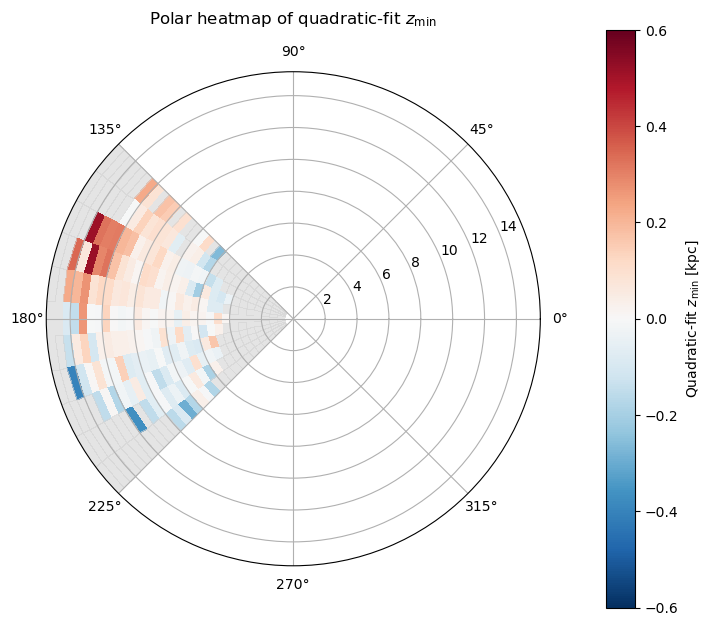

In [21]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# ============================================================
# SETTINGS YOU CAN TWEAK
# ============================================================
# If you already have these in your session, keep them consistent:
# - R_star, Z_star, mgfe_star
# - segm (dict-like: segm[seg_id] boolean mask)
# - z_edges, mgfe_edges
# - crowd_bounds, n_crowd, SEG_PLOT, (optional) seg_rest_id

minN_seg_total = 15      # need at least this many stars in segment total (per annulus) to fit
min_bin_count  = 5       # need at least this many stars per Z-bin to use it in mean trend

# quadratic fit window
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8

# ============================================================
# HELPERS
# ============================================================
def binned_mean_and_counts(Zs, Ys, z_edges):
    nb = len(z_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Zs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])

    return mean, cnt

def quad_fit_on_trend(z_centers, trend, cnt,
                      zmin=z_fit_min, zmax=z_fit_max,
                      min_cnt=min_bin_count, min_bins=min_bins_for_fit):
    """
    Fit y = a z^2 + b z + c to trend within [zmin,zmax],
    requiring cnt>=min_cnt and finite trend.
    Returns: (a,b,c), status, z0_min
    """
    zc  = np.asarray(z_centers)
    tr  = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    m = (zc >= zmin) & (zc <= zmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan

    x = zc[m]
    y = tr[m]

    a, b, c = np.polyfit(x, y, deg=2)

    # need upward-opening parabola for a minimum
    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan

    z0 = -b/(2*a)
    if not (zmin <= z0 <= zmax):
        return (a, b, c), "min_outside_window", np.nan

    return (a, b, c), "ok", float(z0)

# ============================================================
# PART A: COMPUTE QUADRATIC z_min FOR ALL (ANNULUS, SEGMENT)
# ============================================================

# ------------------------------------------------------------
# Annulus edges (define directly; no df_min needed)
# ------------------------------------------------------------
# Annulus edges (kpc) — 0.5 kpc bins from 0.5 to 14.5
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)   # edges include endpoint

R_edges_kept = np.asarray(R_edges, float)   


if len(R_edges_kept) < 2:
    raise RuntimeError("Not enough annuli edges to compute z_min map.")

z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

rows = []
for ir in range(len(R_edges_kept) - 1):
    Rmin_focus = float(R_edges_kept[ir])
    Rmax_focus = float(R_edges_kept[ir + 1])

    mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    Ntot = int(np.sum(mR))
    if Ntot == 0:
        # still write rows with status so downstream plots can show masked cells
        for seg_id in SEG_PLOT:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             z_min_quad=np.nan, status_quad="no_stars_annulus"))
        continue

    for seg_id in SEG_PLOT:
        mseg = mR & segm[seg_id]
        Nseg = int(np.sum(mseg))

        if Nseg < minN_seg_total:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             z_min_quad=np.nan, status_quad="too_few_stars"))
            continue

        Zs = Z_star[mseg]
        Ys = mgfe_star[mseg]
        good = np.isfinite(Zs) & np.isfinite(Ys)
        Zs, Ys = Zs[good], Ys[good]

        mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)
        (a, b, c), st, z0 = quad_fit_on_trend(z_centers, mean_line, cnt_line)

        rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                         z_min_quad=z0, status_quad=st))

df_quad = pd.DataFrame(rows)
# ============================================================
# PART B: POLAR HEATMAP USING QUADRATIC-FIT z_min (z_min_quad)
# ============================================================

zlim = 0.6  # show only if |z_min| <= zlim

# Decide which segments are plottable with crowd_bounds (crowded wedges only)
try:
    SEG_PLOT_heat = [s for s in SEG_PLOT if s != seg_rest_id]
except NameError:
    SEG_PLOT_heat = list(SEG_PLOT)

n_th_from_bounds = len(crowd_bounds) - 1
if len(SEG_PLOT_heat) != n_th_from_bounds:
    SEG_PLOT_heat = list(range(1, n_th_from_bounds + 1))

n_th = len(SEG_PLOT_heat)

# Angular edges from crowd_bounds
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

if len(theta_edges) != n_th + 1:
    raise RuntimeError(
        f"theta_edges has len={len(theta_edges)} but needs n_th+1={n_th+1}. "
        "This means SEG_PLOT_heat doesn't match crowd_bounds."
    )

# Radial edges
R_edges_kept = np.array(
    sorted(set(df_quad["Rmin"].tolist() + df_quad["Rmax"].tolist())),
    float
)
if len(R_edges_kept) < 2:
    raise RuntimeError("Not enough annuli to build heatmap.")

n_r = len(R_edges_kept) - 1

# Fill map from df_quad using z_min_quad/status_quad
Zmap_raw = np.full((n_r, n_th), np.nan, float)
seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

for _, row in df_quad.iterrows():
    if row["status_quad"] != "ok":
        continue

    seg = int(row["seg"])
    if seg not in seg_to_col:
        continue

    zmin = float(row["z_min_quad"])
    if not np.isfinite(zmin):
        continue

    Rmin = float(row["Rmin"])
    ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
    if not (0 <= ir < n_r):
        continue

    it = seg_to_col[seg]
    Zmap_raw[ir, it] = zmin

Zmap = np.where(np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim), Zmap_raw, np.nan)

# Plot
fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")

ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_kept)  # (n_r+1, n_th+1)

pcm = ax.pcolormesh(
    TH, RR, Zmap,
    shading="flat",
    cmap=cmap,
    vmin=-zlim,
    vmax=+zlim
)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"Quadratic-fit $z_{\min}$ [kpc]")

ax.set_title(r"Polar heatmap of quadratic-fit $z_{\min}$", y=1.08)

# Segment labels
#theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
#r_label = R_edges_kept[-1] * 1.05
#for j, th in enumerate(theta_centers):
#    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
#            ha="center", va="center", fontsize=10, weight="bold")

plt.show()


N total: 391560
Position-valid: 391560
Segment populations (first few):
  S1: 3333
  S2: 8911
  S3: 17866
  S4: 36843
  S5: 80319
  S6: 119901

Status counts:
 status
ok    330
Name: count, dtype: int64


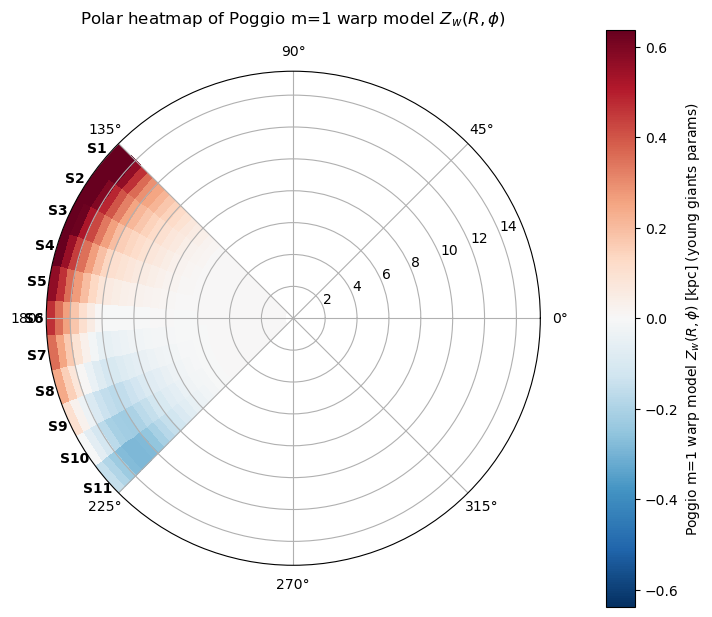

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance


# -------------------------
# Helpers
# -------------------------
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):  # MaskedColumn
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)


# ============================================================
# Poggio m=1 global parametric warp (Young Giants parameters)
# ============================================================
def poggio_m1_global_Zw(R_kpc, phi_rad,
                        Rw=5.5,
                        hw0=0.012,
                        alpha_w=1.9,
                        phiLON0_deg=0.1,
                        RT=12.1,
                        beta_deg_per_kpc=9.9):
    """
    Z_w(R,phi) = h_w(R) * sin(phi - phi_LON(R))
    (Young giants parameter set hard-coded by defaults)
    """
    R = np.asarray(R_kpc, float)
    phi = np.asarray(phi_rad, float)

    # amplitude h_w(R)
    hw = np.zeros_like(R, dtype=float)
    m = np.isfinite(R) & (R > Rw)
    hw[m] = hw0 * (R[m] - Rw)**alpha_w

    # line of nodes phi_LON(R)
    phiLON0 = np.deg2rad(phiLON0_deg)
    beta = np.deg2rad(beta_deg_per_kpc)  # rad/kpc

    phiLON = np.full_like(R, phiLON0, dtype=float)
    mt = np.isfinite(R) & (R > RT)
    phiLON[mt] = phiLON0 + beta * (R[mt] - RT)

    return hw * np.sin(phi - phiLON)


# ============================================================
# USER INPUTS REQUIRED IN YOUR SESSION:
#   - t_final  (your table)
#   - crowd_bounds (radians, len = n_th+1)
# ============================================================
t_final = t_final

# Annuli (match your previous work)
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)


# ============================================================
# PART 1: Build R_all, phi_all for everyone (NO RV needed)
# ============================================================
N = len(t_final)

plx  = col_to_float_array(t_final, "zgr_plx")  # mas
ra   = col_to_float_array(t_final, "ra")
dec  = col_to_float_array(t_final, "dec")

ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

R_all   = np.full(N, np.nan, dtype=float)
phi_all = np.full(N, np.nan, dtype=float)

if np.any(ok_pos):
    dist = Distance((1000.0 / plx[ok_pos]) * u.pc)
    c_pos = SkyCoord(ra=ra[ok_pos]*u.deg, dec=dec[ok_pos]*u.deg, distance=dist, frame="icrs")
    gc = c_pos.transform_to(galcen_frame)

    X = gc.x.to_value(u.kpc)
    Y = gc.y.to_value(u.kpc)

    R_all[ok_pos] = np.sqrt(X**2 + Y**2)
    phi_all[ok_pos] = np.arctan2(Y, X)  # [-pi, pi]

print("N total:", N)
print("Position-valid:", int(np.sum(ok_pos)))


# ============================================================
# PART 2: Angle-wrap fix + segment masks (aligned to t_final)
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)

print("Segment populations (first few):")
for k in range(1, min(n_th, 6) + 1):
    print(f"  S{k}: {int(np.sum(segm[k]))}")


# ============================================================
# PART 3: Compute Zw for each star, then bin-average to (R,seg)
# ============================================================
Zw_star = np.full(N, np.nan, dtype=float)
ok_w = np.isfinite(R_all) & np.isfinite(phi_u)
Zw_star[ok_w] = poggio_m1_global_Zw(R_all[ok_w], phi_u[ok_w])

rows = []
for ir in range(len(R_edges_kept) - 1):
    Rmin = float(R_edges_kept[ir])
    Rmax = float(R_edges_kept[ir+1])

    mR = (R_all >= Rmin) & (R_all < Rmax) & np.isfinite(R_all)
    if int(np.sum(mR)) == 0:
        for seg in SEG_PLOT_heat:
            rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                             Zw_mean=np.nan, N=0, status="no_stars_annulus"))
        continue

    for seg in SEG_PLOT_heat:
        mseg = mR & segm[seg]
        good = mseg & np.isfinite(Zw_star)
        Nbin = int(np.sum(good))

        if Nbin == 0:
            rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                             Zw_mean=np.nan, N=0, status="empty"))
            continue

        rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                         Zw_mean=float(np.nanmean(Zw_star[good])),
                         N=Nbin, status="ok"))

df_warp = pd.DataFrame(rows)
print("\nStatus counts:\n", df_warp["status"].value_counts(dropna=False))


# ============================================================
# PART 4: Polar heatmap of the warp-only field
# ============================================================
R_edges_plot = np.array(sorted(set(df_warp["Rmin"].tolist() + df_warp["Rmax"].tolist())), float)
n_r = len(R_edges_plot) - 1
n_th = len(SEG_PLOT_heat)

seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}
Zmap = np.full((n_r, n_th), np.nan, float)

for _, row in df_warp.iterrows():
    if row["status"] != "ok":
        continue
    Rmin = float(row["Rmin"])
    seg  = int(row["seg"])
    Zw   = float(row["Zw_mean"])

    ir = np.searchsorted(R_edges_plot, Rmin, side="right") - 1
    if (0 <= ir < n_r) and (seg in seg_to_col) and np.isfinite(Zw):
        Zmap[ir, seg_to_col[seg]] = Zw

# choose color range from robust percentiles so it’s readable
finite = np.isfinite(Zmap)
if np.any(finite):
    vmax = np.nanpercentile(np.abs(Zmap[finite]), 98)
    if not np.isfinite(vmax) or vmax == 0:
        vmax = 0.1
else:
    vmax = 0.1

fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")

ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_plot)

pcm = ax.pcolormesh(TH, RR, Zmap, shading="flat", cmap=cmap, vmin=-vmax, vmax=+vmax)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"Poggio m=1 warp model $Z_w(R,\phi)$ [kpc] (young giants params)")

ax.set_title(r"Polar heatmap of Poggio m=1 warp model $Z_w(R,\phi)$", y=1.08)

# Segment labels
theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_plot[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
            ha="center", va="center", fontsize=10, weight="bold")

plt.show()

Lengths check:
  len(t_final): 391560
  len(R_star): 391560
  len(Z_star): 391560
  len(phi_all): 391560
  len(mgfe_star): 391560
Segment counts (first few):
  S1: 3333
  S2: 8911
  S3: 17866
  S4: 36843
  S5: 80319
  S6: 119901
Warp subtraction done.
  finite Z: 391560
  finite Z_corr: 391560

Status counts:
 status_quad
ok                    181
too_few_bins          105
too_few_stars          36
bad_curvature           7
min_outside_window      1
Name: count, dtype: int64


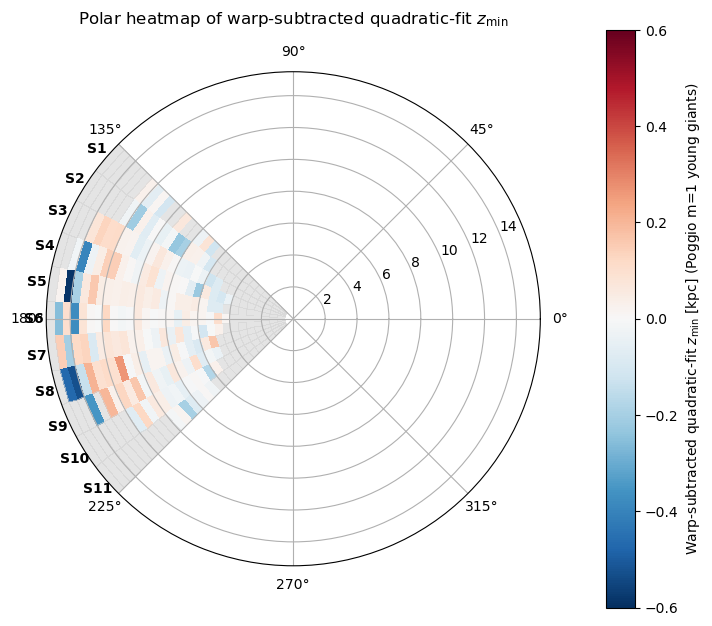

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance


# ============================================================
# Helpers
# ============================================================
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

def binned_mean_and_counts(Zs, Ys, z_edges):
    nb = len(z_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Zs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])
    return mean, cnt

def quad_fit_on_trend(z_centers, trend, cnt,
                      zmin=-1.5, zmax=1.5,
                      min_cnt=5, min_bins=8):
    zc  = np.asarray(z_centers)
    tr  = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    m = (zc >= zmin) & (zc <= zmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan

    x = zc[m]
    y = tr[m]

    a, b, c = np.polyfit(x, y, deg=2)

    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan

    z0 = -b/(2*a)
    if not (zmin <= z0 <= zmax):
        return (a, b, c), "min_outside_window", np.nan

    return (a, b, c), "ok", float(z0)


# ============================================================
# Poggio m=1 global parametric warp (Young Giants parameters)
# ============================================================
def poggio_m1_global_Zw(R, phi,
                               Rw=5.5,
                               A0=0.012,
                               alpha=1.9,
                               phiLON0_deg=0.1,
                               RT=12.1,
                               beta_deg_per_kpc=9.9):
    """
    Global m=1 warp:
      Z_w(R,phi) = A(R) * sin(phi - phi_LON(R))
    """

    R = np.asarray(R, float)
    phi = np.asarray(phi, float)

    # --- Warp amplitude ---
    A = np.zeros_like(R)
    mask = R > Rw
    A[mask] = A0 * (R[mask] - Rw)**alpha

    # --- Line of nodes ---
    phiLON0 = np.deg2rad(phiLON0_deg)
    beta = np.deg2rad(beta_deg_per_kpc)

    phiLON = phiLON0 + beta * np.maximum(R - RT, 0.0)

    return A * np.sin(phi - phiLON)
# ============================================================
# 0) USER SETTINGS
# ============================================================
minN_seg_total = 15
min_bin_count  = 5
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8

# Annuli
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)

# Plot mask range
zlim = 0.6


# ============================================================
# 1) BUILD ALIGNED R_star, Z_star, phi_all FROM t_final (NO SUBSETTING)
# ============================================================
N = len(t_final)

plx = col_to_float_array(t_final, "zgr_plx")  # mas
ra  = col_to_float_array(t_final, "ra")
dec = col_to_float_array(t_final, "dec")

ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

R_star  = np.full(N, np.nan, dtype=float)
Z_star  = np.full(N, np.nan, dtype=float)
phi_all = np.full(N, np.nan, dtype=float)

if np.any(ok_pos):
    dist = Distance((1000.0 / plx[ok_pos]) * u.pc)
    c_pos = SkyCoord(
        ra=ra[ok_pos] * u.deg,
        dec=dec[ok_pos] * u.deg,
        distance=dist,
        frame="icrs",
    )
    gc = c_pos.transform_to(galcen_frame)
    X = gc.x.to_value(u.kpc)
    Y = gc.y.to_value(u.kpc)
    Z = gc.z.to_value(u.kpc)

    R = np.sqrt(X**2 + Y**2)
    phi = np.arctan2(Y, X)  # [-pi, pi]

    R_star[ok_pos]  = R
    Z_star[ok_pos]  = Z
    phi_all[ok_pos] = phi

# mgfe aligned to t_final
mgfe_star = col_to_float_array(t_final, "mg_h") - col_to_float_array(t_final, "fe_h")

print("Lengths check:")
print("  len(t_final):", N)
print("  len(R_star):", len(R_star))
print("  len(Z_star):", len(Z_star))
print("  len(phi_all):", len(phi_all))
print("  len(mgfe_star):", len(mgfe_star))


# ============================================================
# 2) REBUILD segm masks ALIGNED TO THIS SAME t_final LENGTH
#    (Angle-wrap fix done here so segm cannot be mismatched)
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)

print("Segment counts (first few):")
for k in range(1, min(6, n_th) + 1):
    print(f"  S{k}: {int(np.sum(segm[k]))}")


# ============================================================
# 3) WARP SUBTRACTION: Z_corr = Z - Zw(R,phi_u)
# ============================================================
Zw = np.full_like(Z_star, np.nan, dtype=float)
ok_warp = np.isfinite(R_star) & np.isfinite(phi_u) & np.isfinite(Z_star)
Zw[ok_warp] = poggio_m1_global_Zw(R_star[ok_warp], phi_u[ok_warp])

Z_corr = np.full_like(Z_star, np.nan, dtype=float)
Z_corr[ok_warp] = Z_star[ok_warp] - Zw[ok_warp]

print("Warp subtraction done.")
print("  finite Z:", int(np.sum(np.isfinite(Z_star))))
print("  finite Z_corr:", int(np.sum(np.isfinite(Z_corr))))


# ============================================================
# 4) COMPUTE quadratic z_min per (annulus, segment) using Z_corr
# ============================================================
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

rows = []
for ir in range(len(R_edges_kept) - 1):
    Rmin_focus = float(R_edges_kept[ir])
    Rmax_focus = float(R_edges_kept[ir + 1])

    mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    if int(np.sum(mR)) == 0:
        for seg_id in SEG_PLOT_heat:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             z_min_quad=np.nan, status_quad="no_stars_annulus"))
        continue

    for seg_id in SEG_PLOT_heat:
        mseg = mR & segm[seg_id]

        # Require finite Zcorr and finite mgfe
        good = mseg & np.isfinite(Z_corr) & np.isfinite(mgfe_star)
        Nseg = int(np.sum(good))

        if Nseg < minN_seg_total:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             z_min_quad=np.nan, status_quad="too_few_stars"))
            continue

        Zs = Z_corr[good]
        Ys = mgfe_star[good]

        mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)
        (_, _, _), st, z0 = quad_fit_on_trend(
            z_centers, mean_line, cnt_line,
            zmin=z_fit_min, zmax=z_fit_max,
            min_cnt=min_bin_count,
            min_bins=min_bins_for_fit
        )

        rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                         z_min_quad=z0, status_quad=st))

df_quad = pd.DataFrame(rows)
print("\nStatus counts:\n", df_quad["status_quad"].value_counts(dropna=False))


# ============================================================
# 5) POLAR HEATMAP
# ============================================================
# Radial edges from df (just like your original)
R_edges_kept2 = np.array(sorted(set(df_quad["Rmin"].tolist() + df_quad["Rmax"].tolist())), float)
n_r = len(R_edges_kept2) - 1
n_th = len(SEG_PLOT_heat)

Zmap_raw = np.full((n_r, n_th), np.nan, float)
seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

for _, row in df_quad.iterrows():
    if row["status_quad"] != "ok":
        continue
    seg = int(row["seg"])
    if seg not in seg_to_col:
        continue
    zmin = float(row["z_min_quad"])
    if not np.isfinite(zmin):
        continue

    Rmin = float(row["Rmin"])
    ir2 = np.searchsorted(R_edges_kept2, Rmin, side="right") - 1
    if not (0 <= ir2 < n_r):
        continue

    Zmap_raw[ir2, seg_to_col[seg]] = zmin

Zmap = np.where(np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim), Zmap_raw, np.nan)

fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_kept2)

pcm = ax.pcolormesh(TH, RR, Zmap, shading="flat", cmap=cmap, vmin=-zlim, vmax=+zlim)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"Warp-subtracted quadratic-fit $z_{\min}$ [kpc] (Poggio m=1 young giants)")

ax.set_title(r"Polar heatmap of warp-subtracted quadratic-fit $z_{\min}$", y=1.08)

theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_kept2[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}", ha="center", va="center",
            fontsize=10, weight="bold")

plt.show()

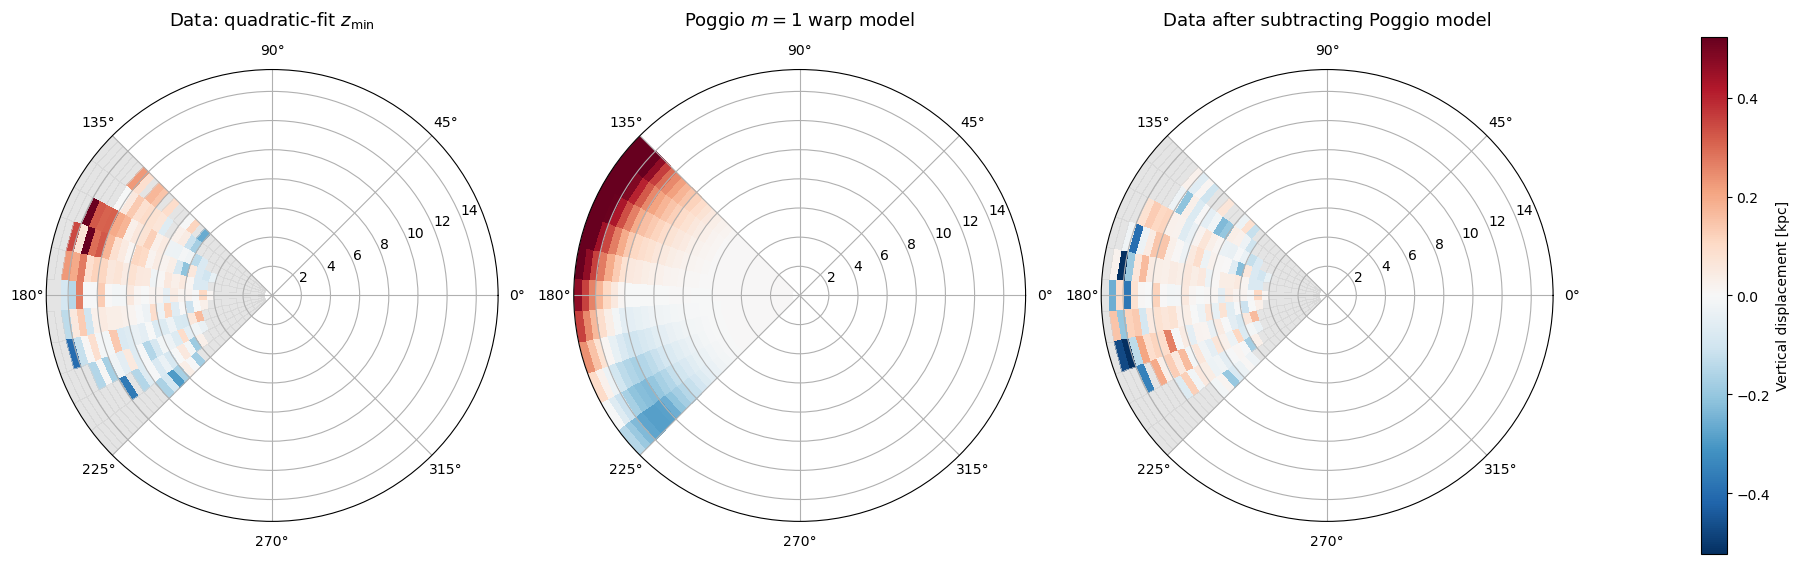

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# ============================================================
# HELPERS
# ============================================================
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

def binned_mean_and_counts(Zs, Ys, z_edges):
    nb = len(z_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Zs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])

    return mean, cnt

def quad_fit_on_trend(z_centers, trend, cnt,
                      zmin=-1.5, zmax=1.5,
                      min_cnt=5, min_bins=8):
    zc  = np.asarray(z_centers)
    tr  = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    m = (zc >= zmin) & (zc <= zmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan

    x = zc[m]
    y = tr[m]

    a, b, c = np.polyfit(x, y, deg=2)

    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan

    z0 = -b / (2 * a)
    if not (zmin <= z0 <= zmax):
        return (a, b, c), "min_outside_window", np.nan

    return (a, b, c), "ok", float(z0)

def poggio_m1_global_Zw(R, phi,
                        Rw=5.5,
                        A0=0.012,
                        alpha=1.9,
                        phiLON0_deg=0.1,
                        RT=12.1,
                        beta_deg_per_kpc=9.9):
    """
    Z_w(R,phi) = A(R) * sin(phi - phi_LON(R))
    """
    R = np.asarray(R, float)
    phi = np.asarray(phi, float)

    A = np.zeros_like(R)
    m = np.isfinite(R) & (R > Rw)
    A[m] = A0 * (R[m] - Rw) ** alpha

    phiLON0 = np.deg2rad(phiLON0_deg)
    beta = np.deg2rad(beta_deg_per_kpc)
    phiLON = phiLON0 + beta * np.maximum(R - RT, 0.0)

    return A * np.sin(phi - phiLON)

def build_zmin_map(R_use, Z_use, mgfe_use, segm, SEG_PLOT_heat, R_edges_kept, z_edges,
                   minN_seg_total=15, min_bin_count=5,
                   z_fit_min=-1.5, z_fit_max=1.5, min_bins_for_fit=8,
                   zlim=0.6):
    """
    Build polar map of quadratic-fit z_min from data arrays.
    Returns Zmap, df_quad.
    """
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    rows = []
    for ir in range(len(R_edges_kept) - 1):
        Rmin_focus = float(R_edges_kept[ir])
        Rmax_focus = float(R_edges_kept[ir + 1])

        mR = (R_use >= Rmin_focus) & (R_use < Rmax_focus)
        Ntot = int(np.sum(mR))

        if Ntot == 0:
            for seg_id in SEG_PLOT_heat:
                rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                                 z_min_quad=np.nan, status_quad="no_stars_annulus"))
            continue

        for seg_id in SEG_PLOT_heat:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_use) & np.isfinite(mgfe_use)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                                 z_min_quad=np.nan, status_quad="too_few_stars"))
                continue

            Zs = Z_use[good]
            Ys = mgfe_use[good]

            mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)
            (_, _, _), st, z0 = quad_fit_on_trend(
                z_centers, mean_line, cnt_line,
                zmin=z_fit_min, zmax=z_fit_max,
                min_cnt=min_bin_count, min_bins=min_bins_for_fit
            )

            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             z_min_quad=z0, status_quad=st))

    df_quad = pd.DataFrame(rows)

    # Build map
    R_edges_plot = np.array(
        sorted(set(df_quad["Rmin"].tolist() + df_quad["Rmax"].tolist())),
        float
    )
    n_r = len(R_edges_plot) - 1
    n_th = len(SEG_PLOT_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

    for _, row in df_quad.iterrows():
        if row["status_quad"] != "ok":
            continue

        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmin = float(row["z_min_quad"])
        if not np.isfinite(zmin):
            continue

        Rmin = float(row["Rmin"])
        ir2 = np.searchsorted(R_edges_plot, Rmin, side="right") - 1
        if not (0 <= ir2 < n_r):
            continue

        Zmap_raw[ir2, seg_to_col[seg]] = zmin

    Zmap = np.where(np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim), Zmap_raw, np.nan)
    return Zmap, df_quad, R_edges_plot

def build_model_map(R_all, phi_u, segm, SEG_PLOT_heat, R_edges_kept):
    """
    Build polar map of mean Poggio model Zw in each (R,seg) bin.
    """
    Zw_star = np.full_like(R_all, np.nan, dtype=float)
    ok = np.isfinite(R_all) & np.isfinite(phi_u)
    Zw_star[ok] = poggio_m1_global_Zw(R_all[ok], phi_u[ok])

    rows = []
    for ir in range(len(R_edges_kept) - 1):
        Rmin = float(R_edges_kept[ir])
        Rmax = float(R_edges_kept[ir + 1])

        mR = (R_all >= Rmin) & (R_all < Rmax) & np.isfinite(R_all)

        if int(np.sum(mR)) == 0:
            for seg in SEG_PLOT_heat:
                rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                                 Zw_mean=np.nan, status="no_stars_annulus"))
            continue

        for seg in SEG_PLOT_heat:
            good = mR & segm[seg] & np.isfinite(Zw_star)
            if int(np.sum(good)) == 0:
                rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                                 Zw_mean=np.nan, status="empty"))
                continue

            rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                             Zw_mean=float(np.nanmean(Zw_star[good])),
                             status="ok"))

    df_warp = pd.DataFrame(rows)

    R_edges_plot = np.array(
        sorted(set(df_warp["Rmin"].tolist() + df_warp["Rmax"].tolist())),
        float
    )
    n_r = len(R_edges_plot) - 1
    n_th = len(SEG_PLOT_heat)

    Zmap = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

    for _, row in df_warp.iterrows():
        if row["status"] != "ok":
            continue

        Rmin = float(row["Rmin"])
        seg  = int(row["seg"])
        Zw   = float(row["Zw_mean"])

        ir = np.searchsorted(R_edges_plot, Rmin, side="right") - 1
        if (0 <= ir < n_r) and (seg in seg_to_col) and np.isfinite(Zw):
            Zmap[ir, seg_to_col[seg]] = Zw

    return Zmap, df_warp, R_edges_plot

# ============================================================
# USER SETTINGS
# ============================================================
minN_seg_total = 15
min_bin_count  = 5
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8
zlim = 0.6

R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)

# ============================================================
# BUILD ALIGNED ARRAYS FROM t_final
# ============================================================
N = len(t_final)

plx = col_to_float_array(t_final, "zgr_plx")
ra  = col_to_float_array(t_final, "ra")
dec = col_to_float_array(t_final, "dec")

ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

R_star  = np.full(N, np.nan, dtype=float)
Z_star  = np.full(N, np.nan, dtype=float)
phi_all = np.full(N, np.nan, dtype=float)

if np.any(ok_pos):
    dist = Distance((1000.0 / plx[ok_pos]) * u.pc)
    c_pos = SkyCoord(
        ra=ra[ok_pos] * u.deg,
        dec=dec[ok_pos] * u.deg,
        distance=dist,
        frame="icrs"
    )
    gc = c_pos.transform_to(galcen_frame)

    X = gc.x.to_value(u.kpc)
    Y = gc.y.to_value(u.kpc)
    Z = gc.z.to_value(u.kpc)

    R_star[ok_pos]  = np.sqrt(X**2 + Y**2)
    Z_star[ok_pos]  = Z
    phi_all[ok_pos] = np.arctan2(Y, X)

mgfe_star = col_to_float_array(t_final, "mg_h") - col_to_float_array(t_final, "fe_h")

# ============================================================
# ANGULAR EDGES AND SEGMENTS
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2 * np.pi)) + theta0

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

segm = {}
for j in range(n_th):
    segm[j + 1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j + 1]) & np.isfinite(phi_u)

# ============================================================
# PANEL 1: YOUR DATA
# ============================================================
Zmap_data, df_quad_data, R_edges_plot_data = build_zmin_map(
    R_use=R_star,
    Z_use=Z_star,
    mgfe_use=mgfe_star,
    segm=segm,
    SEG_PLOT_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    zlim=zlim
)

# ============================================================
# PANEL 2: POGGIO MODEL
# ============================================================
Zmap_model, df_warp, R_edges_plot_model = build_model_map(
    R_all=R_star,
    phi_u=phi_u,
    segm=segm,
    SEG_PLOT_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept
)

# ============================================================
# PANEL 3: DATA - MODEL
# ============================================================
Zw_star = np.full_like(Z_star, np.nan, dtype=float)
ok_warp = np.isfinite(R_star) & np.isfinite(phi_u) & np.isfinite(Z_star)
Zw_star[ok_warp] = poggio_m1_global_Zw(R_star[ok_warp], phi_u[ok_warp])

Z_corr = np.full_like(Z_star, np.nan, dtype=float)
Z_corr[ok_warp] = Z_star[ok_warp] - Zw_star[ok_warp]

Zmap_sub, df_quad_sub, R_edges_plot_sub = build_zmin_map(
    R_use=R_star,
    Z_use=Z_corr,
    mgfe_use=mgfe_star,
    segm=segm,
    SEG_PLOT_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    zlim=zlim
)

# ============================================================
# FORCE SAME RADIAL EDGES
# ============================================================
# These should usually match, but this checks:
if not (np.allclose(R_edges_plot_data, R_edges_plot_model) and np.allclose(R_edges_plot_data, R_edges_plot_sub)):
    raise RuntimeError("Radial edges do not match between panels. Check binning.")

R_edges_plot = R_edges_plot_data

# ============================================================
# SHARED COLOR SCALE
# ============================================================
all_vals = np.concatenate([
    Zmap_data[np.isfinite(Zmap_data)],
    Zmap_model[np.isfinite(Zmap_model)],
    Zmap_sub[np.isfinite(Zmap_sub)],
])

if len(all_vals) > 0:
    vmax = np.nanpercentile(np.abs(all_vals), 98)
    vmax = min(vmax, zlim)
    if not np.isfinite(vmax) or vmax == 0:
        vmax = zlim
else:
    vmax = zlim

# ============================================================
# 3-PANEL FIGURE
# ============================================================
fig, axes = plt.subplots(
    1, 3,
    subplot_kw={"projection": "polar"},
    figsize=(18, 6),
    constrained_layout=True
)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_plot)

panel_maps = [Zmap_data, Zmap_model, Zmap_sub]
panel_titles = [
    r"Data: quadratic-fit $z_{\min}$",
    r"Poggio $m=1$ warp model",
    r"Data after subtracting Poggio model"
]

pcm = None
for ax, Zmap_i, title in zip(axes, panel_maps, panel_titles):
    ax.set_theta_zero_location("E")
    ax.set_theta_direction(1)

    pcm = ax.pcolormesh(
        TH, RR, Zmap_i,
        shading="flat",
        cmap=cmap,
        vmin=-vmax,
        vmax=+vmax
    )

    ax.set_title(title, y=1.08, fontsize=13)

    

# Shared colorbar
cb = fig.colorbar(pcm, ax=axes, pad=0.08, shrink=0.9)
cb.set_label(r"Vertical displacement [kpc]")

plt.show()

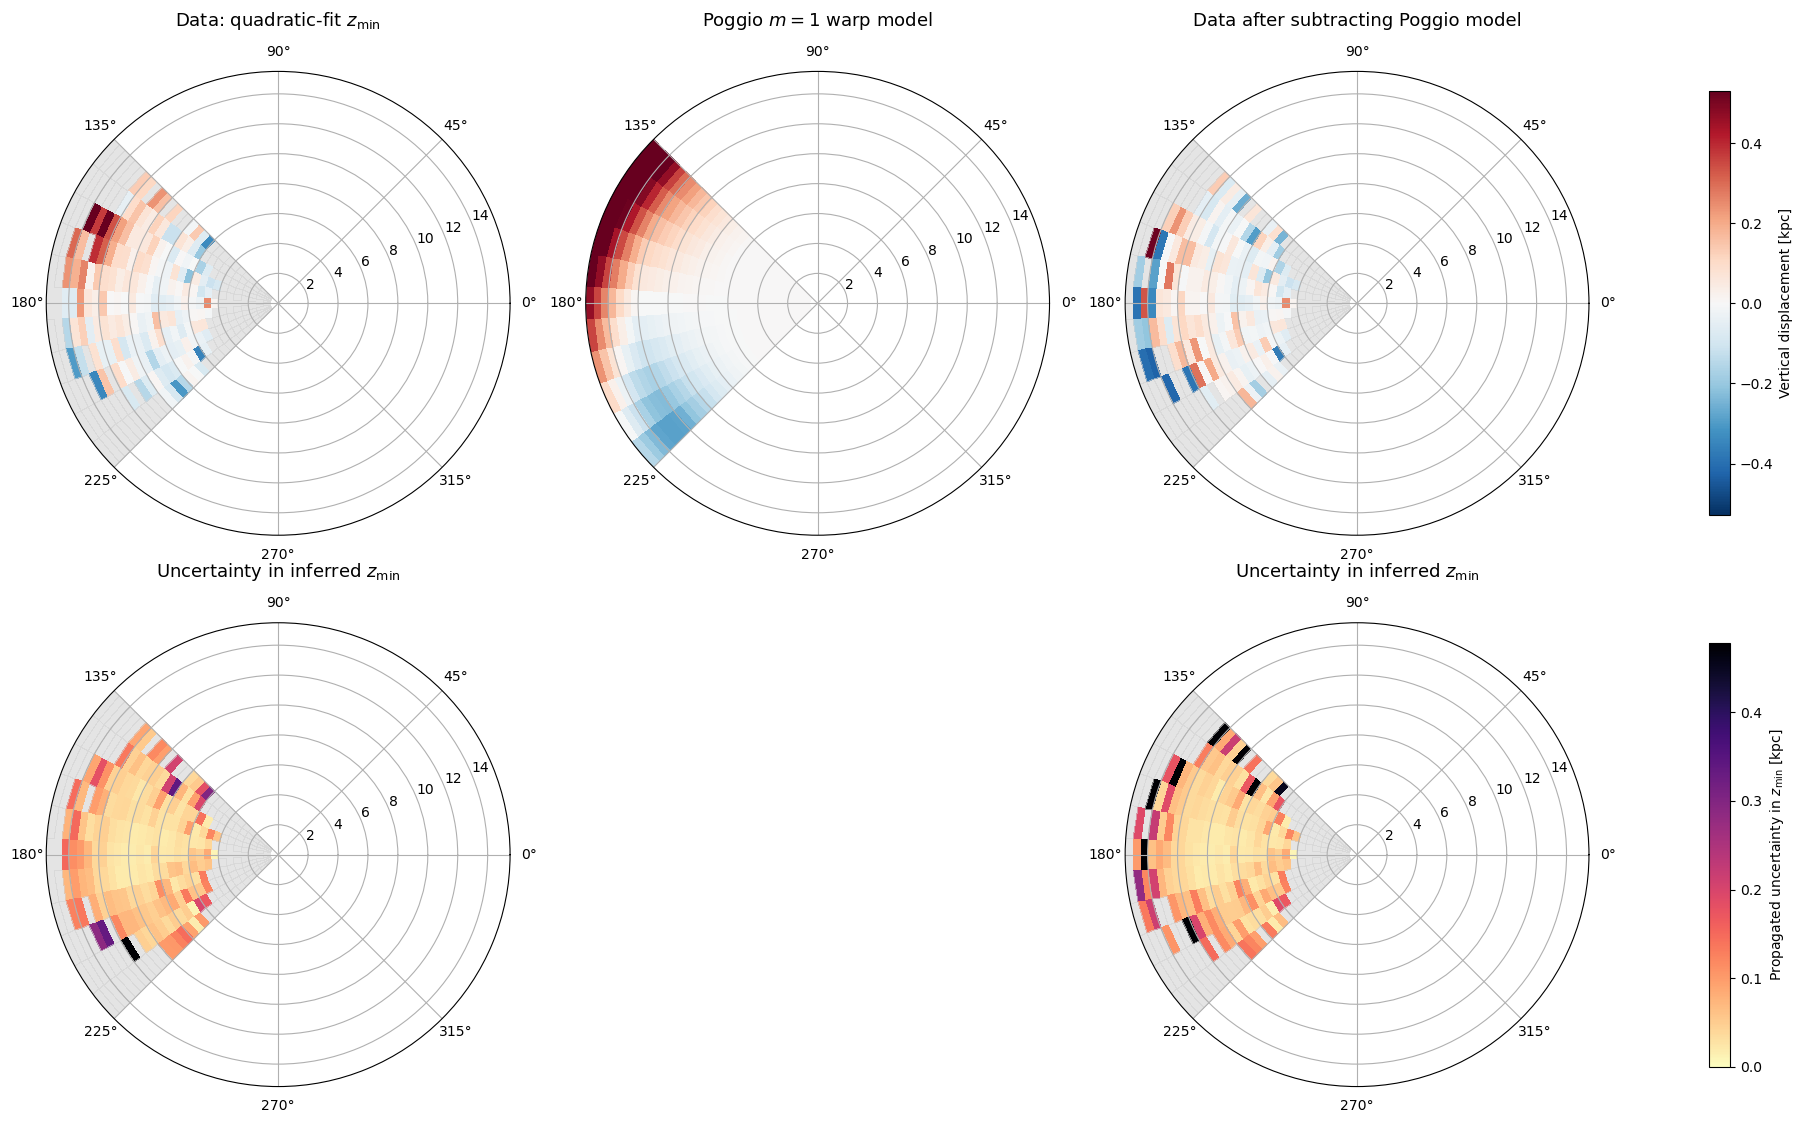

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# ============================================================
# HELPERS
# ============================================================
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

def binned_mean_count_sem(Zs, Ys, z_edges):
    """
    Return mean(Y), count, and SEM(Y) in each z-bin.
    SEM = sample std / sqrt(N), requiring N >= 2.
    """
    nb = len(z_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)
    sem  = np.full(nb, np.nan, float)

    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Zs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        n = int(np.sum(m))
        cnt[i] = n
        if n > 0:
            ybin = Ys[m]
            mean[i] = np.nanmean(ybin)
            if n >= 2:
                s = np.nanstd(ybin, ddof=1)
                sem[i] = s / np.sqrt(n)

    return mean, cnt, sem

def quad_fit_on_trend_with_err(z_centers, trend, cnt, sem,
                               zmin=-1.5, zmax=1.5,
                               min_cnt=5, min_bins=8):
    """
    Weighted quadratic fit y = a z^2 + b z + c.
    Uses SEM on mean(Mg/Fe) per z-bin as fit uncertainty.
    Returns:
      (a,b,c), status, z0, sigma_z0
    """
    zc   = np.asarray(z_centers, float)
    tr   = np.asarray(trend, float)
    cnt  = np.asarray(cnt, int)
    sem  = np.asarray(sem, float)

    # use only bins that are in range, finite, populated, and have finite positive SEM
    m = (
        (zc >= zmin) & (zc <= zmax) &
        np.isfinite(tr) &
        (cnt >= min_cnt) &
        np.isfinite(sem) & (sem > 0)
    )

    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan, np.nan

    x = zc[m]
    y = tr[m]
    s = sem[m]

    # If any SEMs are absurdly tiny, impose a small floor for numerical stability
    pos = s[np.isfinite(s) & (s > 0)]
    if len(pos) == 0:
        return (np.nan, np.nan, np.nan), "bad_sem", np.nan, np.nan
    s_floor = max(np.nanpercentile(pos, 10) * 0.25, 1e-4)
    s = np.maximum(s, s_floor)

    try:
        # np.polyfit weights are 1/sigma, not 1/sigma^2
        coeffs, cov = np.polyfit(x, y, deg=2, w=1.0/s, cov=True)
    except Exception:
        return (np.nan, np.nan, np.nan), "fit_failed", np.nan, np.nan

    a, b, c = coeffs

    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan, np.nan

    z0 = -b / (2.0 * a)
    if not (zmin <= z0 <= zmax):
        return (a, b, c), "min_outside_window", np.nan, np.nan

    # propagate covariance of (a,b) into z0 = -b/(2a)
    # coeff order from polyfit is [a,b,c]
    var_a  = cov[0, 0]
    var_b  = cov[1, 1]
    cov_ab = cov[0, 1]

    dz_da = b / (2.0 * a**2)
    dz_db = -1.0 / (2.0 * a)

    var_z0 = dz_da**2 * var_a + dz_db**2 * var_b + 2.0 * dz_da * dz_db * cov_ab

    if (not np.isfinite(var_z0)) or (var_z0 < 0):
        sigma_z0 = np.nan
    else:
        sigma_z0 = np.sqrt(var_z0)

    return (a, b, c), "ok", float(z0), float(sigma_z0)

def poggio_m1_global_Zw(R, phi,
                        Rw=5.5,
                        A0=0.012,
                        alpha=1.9,
                        phiLON0_deg=0.1,
                        RT=12.1,
                        beta_deg_per_kpc=9.9):
    """
    Z_w(R,phi) = A(R) * sin(phi - phi_LON(R))
    """
    R = np.asarray(R, float)
    phi = np.asarray(phi, float)

    A = np.zeros_like(R)
    m = np.isfinite(R) & (R > Rw)
    A[m] = A0 * (R[m] - Rw) ** alpha

    phiLON0 = np.deg2rad(phiLON0_deg)
    beta = np.deg2rad(beta_deg_per_kpc)
    phiLON = phiLON0 + beta * np.maximum(R - RT, 0.0)

    return A * np.sin(phi - phiLON)

def build_zmin_and_err_maps(R_use, Z_use, mgfe_use, segm, SEG_PLOT_heat, R_edges_kept, z_edges,
                            minN_seg_total=15, min_bin_count=5,
                            z_fit_min=-1.5, z_fit_max=1.5, min_bins_for_fit=8,
                            zlim=0.6):
    """
    Build polar maps of:
      - quadratic-fit z_min
      - propagated uncertainty sigma(z_min)
    Returns:
      Zmap, Emap, df_quad, R_edges_plot
    """
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    rows = []
    for ir in range(len(R_edges_kept) - 1):
        Rmin_focus = float(R_edges_kept[ir])
        Rmax_focus = float(R_edges_kept[ir + 1])

        mR = (R_use >= Rmin_focus) & (R_use < Rmax_focus)
        Ntot = int(np.sum(mR))

        if Ntot == 0:
            for seg_id in SEG_PLOT_heat:
                rows.append(dict(
                    Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                    z_min_quad=np.nan, z_min_err=np.nan,
                    status_quad="no_stars_annulus"
                ))
            continue

        for seg_id in SEG_PLOT_heat:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_use) & np.isfinite(mgfe_use)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                    z_min_quad=np.nan, z_min_err=np.nan,
                    status_quad="too_few_stars"
                ))
                continue

            Zs = Z_use[good]
            Ys = mgfe_use[good]

            mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
            (_, _, _), st, z0, z0err = quad_fit_on_trend_with_err(
                z_centers, mean_line, cnt_line, sem_line,
                zmin=z_fit_min, zmax=z_fit_max,
                min_cnt=min_bin_count, min_bins=min_bins_for_fit
            )

            rows.append(dict(
                Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                z_min_quad=z0, z_min_err=z0err,
                status_quad=st
            ))

    df_quad = pd.DataFrame(rows)

    # Build maps
    R_edges_plot = np.array(
        sorted(set(df_quad["Rmin"].tolist() + df_quad["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_plot) - 1
    n_th = len(SEG_PLOT_heat)
    seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    Emap_raw = np.full((n_r, n_th), np.nan, float)

    for _, row in df_quad.iterrows():
        if row["status_quad"] != "ok":
            continue

        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmin = float(row["z_min_quad"])
        zerr = float(row["z_min_err"]) if np.isfinite(row["z_min_err"]) else np.nan

        if not np.isfinite(zmin):
            continue

        Rmin = float(row["Rmin"])
        ir2 = np.searchsorted(R_edges_plot, Rmin, side="right") - 1
        if not (0 <= ir2 < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir2, it] = zmin
        Emap_raw[ir2, it] = zerr

    # match original display clipping for z_min
    Zmap = np.where(np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim), Zmap_raw, np.nan)

    # keep uncertainty only where z_min is actually shown
    Emap = np.where(np.isfinite(Zmap), Emap_raw, np.nan)

    return Zmap, Emap, df_quad, R_edges_plot

def build_model_map(R_all, phi_u, segm, SEG_PLOT_heat, R_edges_kept):
    """
    Build polar map of mean Poggio model Zw in each (R,seg) bin.
    """
    Zw_star = np.full_like(R_all, np.nan, dtype=float)
    ok = np.isfinite(R_all) & np.isfinite(phi_u)
    Zw_star[ok] = poggio_m1_global_Zw(R_all[ok], phi_u[ok])

    rows = []
    for ir in range(len(R_edges_kept) - 1):
        Rmin = float(R_edges_kept[ir])
        Rmax = float(R_edges_kept[ir + 1])

        mR = (R_all >= Rmin) & (R_all < Rmax) & np.isfinite(R_all)

        if int(np.sum(mR)) == 0:
            for seg in SEG_PLOT_heat:
                rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                                 Zw_mean=np.nan, status="no_stars_annulus"))
            continue

        for seg in SEG_PLOT_heat:
            good = mR & segm[seg] & np.isfinite(Zw_star)
            if int(np.sum(good)) == 0:
                rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                                 Zw_mean=np.nan, status="empty"))
                continue

            rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg),
                             Zw_mean=float(np.nanmean(Zw_star[good])),
                             status="ok"))

    df_warp = pd.DataFrame(rows)

    R_edges_plot = np.array(
        sorted(set(df_warp["Rmin"].tolist() + df_warp["Rmax"].tolist())),
        float
    )
    n_r = len(R_edges_plot) - 1
    n_th = len(SEG_PLOT_heat)

    Zmap = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

    for _, row in df_warp.iterrows():
        if row["status"] != "ok":
            continue

        Rmin = float(row["Rmin"])
        seg  = int(row["seg"])
        Zw   = float(row["Zw_mean"])

        ir = np.searchsorted(R_edges_plot, Rmin, side="right") - 1
        if (0 <= ir < n_r) and (seg in seg_to_col) and np.isfinite(Zw):
            Zmap[ir, seg_to_col[seg]] = Zw

    return Zmap, df_warp, R_edges_plot

# ============================================================
# USER SETTINGS
# ============================================================
minN_seg_total = 15
min_bin_count  = 5
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8
zlim = 0.6

R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)

# ============================================================
# BUILD ALIGNED ARRAYS FROM t_final
# ============================================================
N = len(t_final)

plx = col_to_float_array(t_final, "zgr_plx")
ra  = col_to_float_array(t_final, "ra")
dec = col_to_float_array(t_final, "dec")

ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

R_star  = np.full(N, np.nan, dtype=float)
Z_star  = np.full(N, np.nan, dtype=float)
phi_all = np.full(N, np.nan, dtype=float)

if np.any(ok_pos):
    dist = Distance((1000.0 / plx[ok_pos]) * u.pc)
    c_pos = SkyCoord(
        ra=ra[ok_pos] * u.deg,
        dec=dec[ok_pos] * u.deg,
        distance=dist,
        frame="icrs"
    )
    gc = c_pos.transform_to(galcen_frame)

    X = gc.x.to_value(u.kpc)
    Y = gc.y.to_value(u.kpc)
    Z = gc.z.to_value(u.kpc)

    R_star[ok_pos]  = np.sqrt(X**2 + Y**2)
    Z_star[ok_pos]  = Z
    phi_all[ok_pos] = np.arctan2(Y, X)

mgfe_star = col_to_float_array(t_final, "mg_h") - col_to_float_array(t_final, "fe_h")

# ============================================================
# ANGULAR EDGES AND SEGMENTS
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2 * np.pi)) + theta0

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

segm = {}
for j in range(n_th):
    segm[j + 1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j + 1]) & np.isfinite(phi_u)

# ============================================================
# PANEL 1: YOUR DATA + ERROR
# ============================================================
Zmap_data, Emap_data, df_quad_data, R_edges_plot_data = build_zmin_and_err_maps(
    R_use=R_star,
    Z_use=Z_star,
    mgfe_use=mgfe_star,
    segm=segm,
    SEG_PLOT_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    zlim=zlim
)

# ============================================================
# PANEL 2: POGGIO MODEL
# ============================================================
Zmap_model, df_warp, R_edges_plot_model = build_model_map(
    R_all=R_star,
    phi_u=phi_u,
    segm=segm,
    SEG_PLOT_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept
)

# ============================================================
# PANEL 3: DATA - MODEL + ERROR
# ============================================================
Zw_star = np.full_like(Z_star, np.nan, dtype=float)
ok_warp = np.isfinite(R_star) & np.isfinite(phi_u) & np.isfinite(Z_star)
Zw_star[ok_warp] = poggio_m1_global_Zw(R_star[ok_warp], phi_u[ok_warp])

Z_corr = np.full_like(Z_star, np.nan, dtype=float)
Z_corr[ok_warp] = Z_star[ok_warp] - Zw_star[ok_warp]

Zmap_sub, Emap_sub, df_quad_sub, R_edges_plot_sub = build_zmin_and_err_maps(
    R_use=R_star,
    Z_use=Z_corr,
    mgfe_use=mgfe_star,
    segm=segm,
    SEG_PLOT_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    zlim=zlim
)

# ============================================================
# CHECK RADIAL EDGES
# ============================================================
if not (np.allclose(R_edges_plot_data, R_edges_plot_model) and np.allclose(R_edges_plot_data, R_edges_plot_sub)):
    raise RuntimeError("Radial edges do not match between panels. Check binning.")

R_edges_plot = R_edges_plot_data

# ============================================================
# COLOR SCALES
# ============================================================
all_vals = np.concatenate([
    Zmap_data[np.isfinite(Zmap_data)],
    Zmap_model[np.isfinite(Zmap_model)],
    Zmap_sub[np.isfinite(Zmap_sub)],
])

if len(all_vals) > 0:
    vmax = np.nanpercentile(np.abs(all_vals), 98)
    vmax = min(vmax, zlim)
    if not np.isfinite(vmax) or vmax == 0:
        vmax = zlim
else:
    vmax = zlim

all_err = np.concatenate([
    Emap_data[np.isfinite(Emap_data)],
    Emap_sub[np.isfinite(Emap_sub)],
])

if len(all_err) > 0:
    emax = np.nanpercentile(all_err, 98)
    if not np.isfinite(emax) or emax == 0:
        emax = 0.1
else:
    emax = 0.1

# ============================================================
# 2x3 FIGURE
# ============================================================
fig, axes = plt.subplots(
    2, 3,
    subplot_kw={"projection": "polar"},
    figsize=(18, 11),
    constrained_layout=True
)

cmap_z = plt.cm.RdBu_r.copy()
cmap_z.set_bad(color="lightgray", alpha=0.6)

cmap_e = plt.cm.magma_r.copy()
cmap_e.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_plot)

# ---------- top row ----------
top_maps = [Zmap_data, Zmap_model, Zmap_sub]
top_titles = [
    r"Data: quadratic-fit $z_{\min}$",
    r"Poggio $m=1$ warp model",
    r"Data after subtracting Poggio model"
]

pcm_top = None
for ax, Zmap_i, title in zip(axes[0], top_maps, top_titles):
    ax.set_theta_zero_location("E")
    ax.set_theta_direction(1)

    pcm_top = ax.pcolormesh(
        TH, RR, Zmap_i,
        shading="flat",
        cmap=cmap_z,
        vmin=-vmax,
        vmax=+vmax
    )
    ax.set_title(title, y=1.08, fontsize=13)

# ---------- bottom row ----------
bottom_maps = [Emap_data, None, Emap_sub]
bottom_titles = [
    r"Uncertainty in inferred $z_{\min}$",
    "",
    r"Uncertainty in inferred $z_{\min}$"
]

pcm_bottom = None
for j, (ax, Emap_i, title) in enumerate(zip(axes[1], bottom_maps, bottom_titles)):
    if Emap_i is None:
        ax.set_axis_off()
        continue

    ax.set_theta_zero_location("E")
    ax.set_theta_direction(1)

    pcm_bottom = ax.pcolormesh(
        TH, RR, Emap_i,
        shading="flat",
        cmap=cmap_e,
        vmin=0,
        vmax=emax
    )
    ax.set_title(title, y=1.08, fontsize=13)

# shared colorbars
cb1 = fig.colorbar(pcm_top, ax=axes[0, :], pad=0.06, shrink=0.9)
cb1.set_label(r"Vertical displacement [kpc]")

cb2 = fig.colorbar(pcm_bottom, ax=[axes[1, 0], axes[1, 2]], pad=0.06, shrink=0.9)
cb2.set_label(r"Propagated uncertainty in $z_{\min}$ [kpc]")

plt.show()

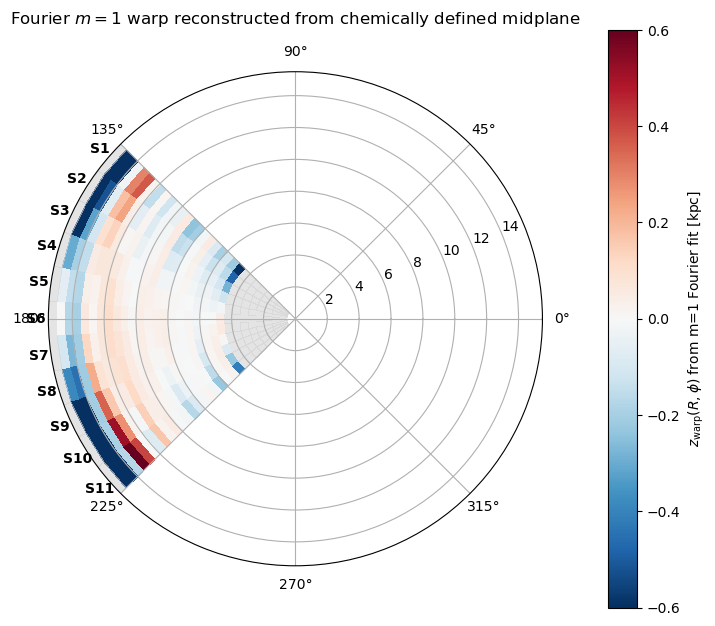

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1) Geometry setup (same as before)
# ============================================================

theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
n_th = len(theta_centers)

R_edges = np.array(
    sorted(set(df_quad["Rmin"].tolist() + df_quad["Rmax"].tolist())),
    float
)
n_r = len(R_edges) - 1

# ============================================================
# 2) Fit m=1 Fourier model in each annulus
# ============================================================

Amap = np.full((n_r, n_th), np.nan)   # reconstructed warp surface
Amp = np.full(n_r, np.nan)            # warp amplitude per annulus
phiLON = np.full(n_r, np.nan)         # line of nodes per annulus

seg_to_idx = {seg: i for i, seg in enumerate(SEG_PLOT_heat)}

for ir in range(n_r):
    Rmin, Rmax = R_edges[ir], R_edges[ir+1]

    rows = df_quad[
        (df_quad["Rmin"] == Rmin) &
        (df_quad["status_quad"] == "ok")
    ]

    if len(rows) < 3:
        continue

    phis = []
    zs   = []

    for _, r in rows.iterrows():
        seg = int(r["seg"])
        if seg not in seg_to_idx:
            continue

        phis.append(theta_centers[seg_to_idx[seg]])
        zs.append(r["z_min_quad"])

    phis = np.array(phis)
    zs   = np.array(zs)

    if len(zs) < 3:
        continue

    # Design matrix: [1, cosφ, sinφ]
    X = np.column_stack([
        np.ones_like(phis),
        np.cos(phis),
        np.sin(phis)
    ])

    coeffs, *_ = np.linalg.lstsq(X, zs, rcond=None)
    a0, a1, b1 = coeffs

    Amp[ir] = np.sqrt(a1**2 + b1**2)
    phiLON[ir] = np.arctan2(b1, a1)

    # Reconstruct warp surface
    Amap[ir, :] = a0 + a1*np.cos(theta_centers) + b1*np.sin(theta_centers)

# ============================================================
# 3) Polar heatmap of reconstructed warp
# ============================================================

fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")

ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges)

pcm = ax.pcolormesh(
    TH, RR, Amap,
    shading="flat",
    cmap=cmap,
    vmin=-0.6,
    vmax=+0.6
)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"$z_{\rm warp}(R,\phi)$ from m=1 Fourier fit [kpc]")

ax.set_title(
    r"Fourier $m=1$ warp reconstructed from chemically defined midplane",
    y=1.08
)

# Segment labels
r_label = R_edges[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
            ha="center", va="center", fontsize=10, weight="bold")

plt.show()

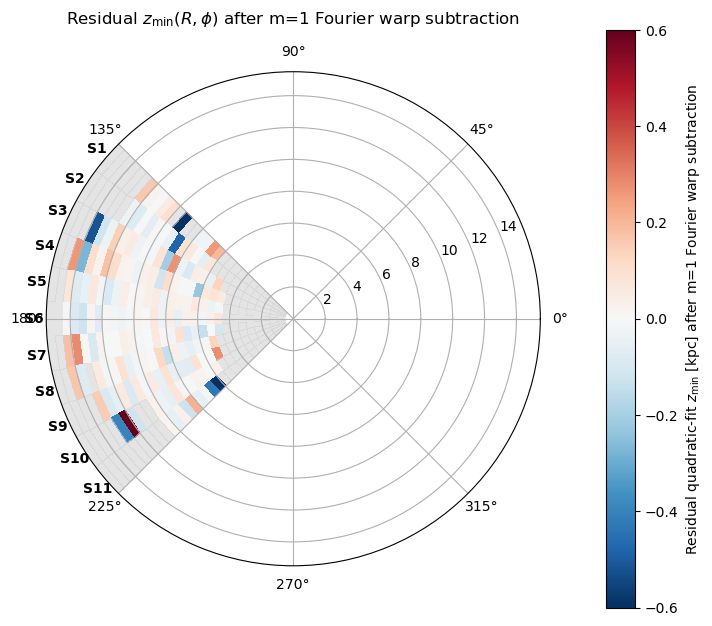

Raw map status counts:
 status_quad
ok                    178
too_few_bins          104
too_few_stars          36
bad_curvature          11
min_outside_window      1
Name: count, dtype: int64

Residual map status counts:
 status_quad
ok                    178
too_few_stars         110
too_few_bins           37
bad_curvature           4
min_outside_window      1
Name: count, dtype: int64


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance


# -------------------------
# Helpers
# -------------------------
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):  # MaskedColumn
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

def binned_mean_and_counts(Zs, Ys, z_edges):
    nb = len(z_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Zs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])

    return mean, cnt

def quad_fit_on_trend(z_centers, trend, cnt,
                      zmin=-1.5, zmax=1.5,
                      min_cnt=5, min_bins=8):
    """
    Fit y = a z^2 + b z + c to trend within [zmin,zmax],
    requiring cnt>=min_cnt and finite trend.
    Return z0 = -b/(2a) if upward-opening and inside window.
    """
    zc  = np.asarray(z_centers)
    tr  = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    m = (zc >= zmin) & (zc <= zmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan

    x = zc[m]
    y = tr[m]
    a, b, c = np.polyfit(x, y, deg=2)

    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan

    z0 = -b/(2*a)
    if not (zmin <= z0 <= zmax):
        return (a, b, c), "min_outside_window", np.nan

    return (a, b, c), "ok", float(z0)

def fit_m1_fourier_per_ring(phi_centers, zvals):
    """
    Fit z(phi) = a0 + a1 cos(phi) + b1 sin(phi)  (m=1 Fourier)
    returns (a0,a1,b1)
    """
    phi_centers = np.asarray(phi_centers, float)
    zvals = np.asarray(zvals, float)
    m = np.isfinite(phi_centers) & np.isfinite(zvals)
    if np.sum(m) < 3:
        return np.nan, np.nan, np.nan

    ph = phi_centers[m]
    zz = zvals[m]
    X = np.column_stack([np.ones_like(ph), np.cos(ph), np.sin(ph)])
    coeffs, *_ = np.linalg.lstsq(X, zz, rcond=None)
    return coeffs[0], coeffs[1], coeffs[2]


# ============================================================
# USER INPUTS (must exist)
#   - t_final
#   - crowd_bounds (radians, len=n_th+1)
# ============================================================
t_final = t_final

# abundance tracer
mgfe_star = col_to_float_array(t_final, "mg_h") - col_to_float_array(t_final, "fe_h")

# quadratic-fit settings (same as your Z-midplane work)
minN_seg_total  = 15
min_bin_count   = 5
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8

# z-binning for the Mg/Fe(Z) trends
z_edges = np.linspace(-3.0, 3.0, 181)
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

# annuli
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)


# ============================================================
# PART 1: Build R_all, phi_all, Z_all for everyone (NO RV needed)
# ============================================================
plx  = col_to_float_array(t_final, "zgr_plx")  # mas
ra   = col_to_float_array(t_final, "ra")
dec  = col_to_float_array(t_final, "dec")

ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

dist = Distance((1000.0 / plx[ok_pos]) * u.pc)
c = SkyCoord(ra=ra[ok_pos]*u.deg, dec=dec[ok_pos]*u.deg, distance=dist, frame="icrs")
gc = c.transform_to(galcen_frame)

X = gc.x.to_value(u.kpc)
Y = gc.y.to_value(u.kpc)
Z = gc.z.to_value(u.kpc)

R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)  # [-pi, pi]

R_all   = np.full(len(t_final), np.nan)
phi_all = np.full(len(t_final), np.nan)
Z_all   = np.full(len(t_final), np.nan)

R_all[ok_pos]   = R
phi_all[ok_pos] = phi
Z_all[ok_pos]   = Z


# ============================================================
# PART 2: Angle-wrap fix and segment masks (aligned to t_final)
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

# segment centers (for Fourier fit)
theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])

# segment masks
segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)


# ============================================================
# PART 3: ORIGINAL z_min map from quadratic fits (uses raw Z)
# ============================================================
def compute_zmin_map(Z_use):
    rows = []
    for ir in range(len(R_edges_kept) - 1):
        Rmin = float(R_edges_kept[ir])
        Rmax = float(R_edges_kept[ir+1])
        mR = (R_all >= Rmin) & (R_all < Rmax) & np.isfinite(R_all)

        if int(np.sum(mR)) == 0:
            for seg_id in SEG_PLOT_heat:
                rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg_id),
                                 z_min_quad=np.nan, status_quad="no_stars_annulus"))
            continue

        for seg_id in SEG_PLOT_heat:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_use) & np.isfinite(mgfe_star)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg_id),
                                 z_min_quad=np.nan, status_quad="too_few_stars"))
                continue

            Zs = Z_use[good]
            Ys = mgfe_star[good]
            mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)
            (_, _, _), st, z0 = quad_fit_on_trend(
                z_centers, mean_line, cnt_line,
                zmin=z_fit_min, zmax=z_fit_max,
                min_cnt=min_bin_count, min_bins=min_bins_for_fit
            )

            rows.append(dict(Rmin=Rmin, Rmax=Rmax, seg=int(seg_id),
                             z_min_quad=z0, status_quad=st))

    return pd.DataFrame(rows)

df_quad_raw = compute_zmin_map(Z_all)


# ============================================================
# PART 4: Fit m=1 Fourier warp per annulus to z_min(phi)
# ============================================================
# Build lookup: for each (Rmin, seg) -> z_min_quad
# We'll fit using only status=="ok"
warp_coeffs = {}  # key: Rmin -> (a0,a1,b1)

seg_to_idx = {seg: i for i, seg in enumerate(SEG_PLOT_heat)}

for ir in range(len(R_edges_kept) - 1):
    Rmin = float(R_edges_kept[ir])
    rows = df_quad_raw[(df_quad_raw["Rmin"] == Rmin) & (df_quad_raw["status_quad"] == "ok")]

    if len(rows) < 3:
        warp_coeffs[Rmin] = (np.nan, np.nan, np.nan)
        continue

    phis = []
    zmins = []
    for _, r in rows.iterrows():
        seg = int(r["seg"])
        if seg not in seg_to_idx:
            continue
        phis.append(theta_centers[seg_to_idx[seg]])
        zmins.append(float(r["z_min_quad"]))

    a0, a1, b1 = fit_m1_fourier_per_ring(phis, zmins)
    warp_coeffs[Rmin] = (a0, a1, b1)


# ============================================================
# PART 5: Evaluate Fourier warp for each star and subtract
# ============================================================
Zwarp = np.full_like(Z_all, np.nan, dtype=float)

# assign each star to an annulus by R
goodR = np.isfinite(R_all) & np.isfinite(phi_u)
ann_idx = np.searchsorted(R_edges_kept, R_all, side="right") - 1
in_range = goodR & (ann_idx >= 0) & (ann_idx < (len(R_edges_kept)-1))

phi_star = phi_u[in_range]
Rmin_star = R_edges_kept[ann_idx[in_range]]  # ring key

# compute Zw = a0 + a1 cos(phi) + b1 sin(phi) for that star's ring
a0 = np.array([warp_coeffs[rm][0] for rm in Rmin_star], float)
a1 = np.array([warp_coeffs[rm][1] for rm in Rmin_star], float)
b1 = np.array([warp_coeffs[rm][2] for rm in Rmin_star], float)

okc = np.isfinite(a0) & np.isfinite(a1) & np.isfinite(b1) & np.isfinite(phi_star)
Zwarp_vals = np.full_like(phi_star, np.nan, dtype=float)
Zwarp_vals[okc] = a0[okc] + a1[okc]*np.cos(phi_star[okc]) + b1[okc]*np.sin(phi_star[okc])

Zwarp[in_range] = Zwarp_vals

Z_corr = Z_all - Zwarp  # <-- Fourier warp-subtracted Z


# ============================================================
# PART 6: Recompute z_min map using Z_corr (this is the residual!)
# ============================================================
df_quad_resid = compute_zmin_map(Z_corr)


# ============================================================
# PART 7: Plot polar heatmap of residual z_min after Fourier subtraction
# ============================================================
# Fill map
R_edges_plot = np.array(
    sorted(set(df_quad_resid["Rmin"].tolist() + df_quad_resid["Rmax"].tolist())),
    float
)
n_r = len(R_edges_plot) - 1
n_th = len(SEG_PLOT_heat)

Zmap = np.full((n_r, n_th), np.nan, float)

for _, row in df_quad_resid.iterrows():
    if row["status_quad"] != "ok":
        continue
    Rmin = float(row["Rmin"])
    seg = int(row["seg"])
    z0 = float(row["z_min_quad"])
    ir = np.searchsorted(R_edges_plot, Rmin, side="right") - 1
    if (0 <= ir < n_r) and (seg in seg_to_idx) and np.isfinite(z0):
        Zmap[ir, seg_to_idx[seg]] = z0

# Plot
zlim = 0.6  # display range (doesn't mask; just colorbar)
fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")

ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_plot)

pcm = ax.pcolormesh(
    TH, RR, Zmap,
    shading="flat",
    cmap=cmap,
    vmin=-zlim,
    vmax=+zlim
)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"Residual quadratic-fit $z_{\min}$ [kpc] after m=1 Fourier warp subtraction")

ax.set_title(r"Residual $z_{\min}(R,\phi)$ after m=1 Fourier warp subtraction", y=1.08)

# Segment labels
theta_centers_plot = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_plot[-1] * 1.05
for j, th in enumerate(theta_centers_plot):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
            ha="center", va="center", fontsize=10, weight="bold")

plt.show()

print("Raw map status counts:\n", df_quad_raw["status_quad"].value_counts(dropna=False))
print("\nResidual map status counts:\n", df_quad_resid["status_quad"].value_counts(dropna=False))

In [28]:
import numpy as np
import pandas as pd

# --------------------------------------------
# INPUT: df_quad must have columns:
#   Rmin, Rmax, seg, z_min_quad, status_quad
# --------------------------------------------
# If your dataframe is named differently, change df_quad below.

# 1) Make a printable cell value:
#    - if status is ok -> show z value formatted
#    - otherwise -> show short status tag
def cell_value(row):
    if row["status_quad"] == "ok" and np.isfinite(row["z_min_quad"]):
        return f"{row['z_min_quad']:+.3f}"   # matches your style like 0.050, -0.250 etc
    # map your internal status names to your preferred short labels
    mapping = {
        "too_few_stars": "too_fe",
        "too_few_bins":  "too_fe",
        "no_stars_annulus": "too_fe",
        "bad_curvature": "no_val",
        "min_outside_window": "no_val",
    }
    return mapping.get(row["status_quad"], str(row["status_quad"])[:6])

df_print = df_quad.copy()
df_print["cell"] = df_print.apply(cell_value, axis=1)

# 2) Pivot to wide table: rows=(Rmin,Rmax), cols=seg
wide = df_print.pivot_table(
    index=["Rmin", "Rmax"],
    columns="seg",
    values="cell",
    aggfunc="first"
).sort_index()

# 3) Rename columns to s01, s02, ...
wide.columns = [f"s{int(c):02d}" for c in wide.columns]

# 4) Make sure all segments appear (optional: if you expect exactly SEG_PLOT)
# for seg in SEG_PLOT:
#     col = f"s{int(seg):02d}"
#     if col not in wide.columns:
#         wide[col] = "----"
# wide = wide[[f"s{int(seg):02d}" for seg in SEG_PLOT]]

# 5) Print in a “terminal-like” aligned way (like your screenshot)
print("Picked minima z_min per annulus")
print(wide.to_string())

# Optional: save exactly this view
# wide.to_csv("zmin_by_annulus_segment.csv")


Picked minima z_min per annulus
              s01     s02     s03     s04     s05     s06     s07     s08     s09     s10     s11
Rmin Rmax                                                                                        
0.5  1.0   too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe
1.0  1.5   too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe
1.5  2.0   too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe
2.0  2.5   too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe
2.5  3.0   too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe
3.0  3.5   too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe  too_fe
3.5  4.0   too_fe  too_fe  too_fe  too_fe  too_fe  no_val  too_fe  too_fe  too_fe  too_fe  too_fe
4.0  4.5   too_fe  too_fe  too_fe  -0.041  too_fe  +0.010  too_fe  too_fe  too_fe  too

In [29]:
import numpy as np
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# ----------------------------
# Helpers
# ----------------------------
def angdiff(a, b):
    """Smallest signed difference a-b, result in [-pi, +pi]."""
    return (a - b + np.pi) % (2*np.pi) - np.pi

def wrap_to_0_2pi(phi):
    return phi % (2*np.pi)

def assign_segment(phi, edges):
    """
    phi in [0,2pi); edges length nseg+1, strictly increasing (unwrap/monotonic).
    returns seg index 0..nseg-1, or -1 if out of range
    """
    # edges may exceed 2pi after unwrap; bring phi into comparable range by also unwrapping edges once
    j = np.searchsorted(edges, phi, side="right") - 1
    if (j < 0) or (j >= len(edges)-1):
        return -1
    return j

# ----------------------------
# 0) Pull needed columns from t_final
# ----------------------------
ra   = np.asarray(t_final["ra"], float)
dec  = np.asarray(t_final["dec"], float)

plx   = np.asarray(t_final["zgr_plx"], float)     # mas
e_plx = np.asarray(t_final["zgr_e_plx"], float)   # mas

# valid for inversion + error propagation
ok = np.isfinite(ra) & np.isfinite(dec) & np.isfinite(plx) & np.isfinite(e_plx) & (plx > 0) & (e_plx >= 0)

# Nominal distance in kpc: D = 1/plx (mas -> kpc)
D_kpc = np.full(plx.shape, np.nan, float)
D_kpc[ok] = 1.0 / plx[ok]

# Gaussian propagation: sigma_D = e_plx / plx^2  (kpc)
sigD_kpc = np.full(plx.shape, np.nan, float)
sigD_kpc[ok] = e_plx[ok] / (plx[ok]**2)

# Keep D-sigma positive
ok &= np.isfinite(sigD_kpc) & (D_kpc - sigD_kpc > 0)

# ----------------------------
# 1) Compute phi(D), phi(D+sigD), phi(D-sigD)
# ----------------------------
galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

def compute_phi_for_distance(dist_kpc, ra_deg, dec_deg):
    c = SkyCoord(
        ra=ra_deg * u.deg,
        dec=dec_deg * u.deg,
        distance=Distance(dist_kpc * u.kpc),
        frame="icrs",
    )
    gc = c.transform_to(galcen_frame)
    X = gc.x.to_value(u.kpc)
    Y = gc.y.to_value(u.kpc)
    phi = np.arctan2(Y, X)              # [-pi, pi]
    return wrap_to_0_2pi(phi), X, Y

phi0, X0, Y0 = compute_phi_for_distance(D_kpc[ok], ra[ok], dec[ok])
phi_p, _, _  = compute_phi_for_distance(D_kpc[ok] + sigD_kpc[ok], ra[ok], dec[ok])
phi_m, _, _  = compute_phi_for_distance(D_kpc[ok] - sigD_kpc[ok], ra[ok], dec[ok])

# 1-sigma phi uncertainty via symmetric finite difference (handle wrapping!)
dphi_pm = np.abs(angdiff(phi_p, phi_m))     # in [0, pi]
sigphi  = 0.5 * dphi_pm                    # radians

# ----------------------------
# 2) Define "pixel" as wedge width for each star
# ----------------------------
theta_edges = np.array(crowd_bounds, float)

# IMPORTANT: edges must be strictly increasing in the SAME domain as phi0.
# If you already unwrapped + enforced monotonic earlier, reuse that version.
# Otherwise do a safe monotonic enforcement:
theta_edges = np.unwrap(theta_edges)
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

# For each star, find its segment index and that segment's width
seg_idx = np.array([assign_segment(p, theta_edges) for p in phi0], int)

seg_width = np.full_like(sigphi, np.nan, float)
good_seg = seg_idx >= 0
seg_width[good_seg] = theta_edges[seg_idx[good_seg] + 1] - theta_edges[seg_idx[good_seg]]

# ----------------------------
# 3) Classify "bigger than a pixel"
# ----------------------------
# option A (boundary-crossing criterion): sigma_phi > 0.5 * seg_width
big_err = good_seg & (sigphi > 0.5 * seg_width)

print("N(t_final):", len(t_final))
print("N usable for phi-error test:", int(np.sum(ok)))
print("N with segment assigned:", int(np.sum(good_seg)))
print("N sigma_phi > 0.5*seg_width:", int(np.sum(big_err)))


N(t_final): 391560
N usable for phi-error test: 391560
N with segment assigned: 385618
N sigma_phi > 0.5*seg_width: 3376


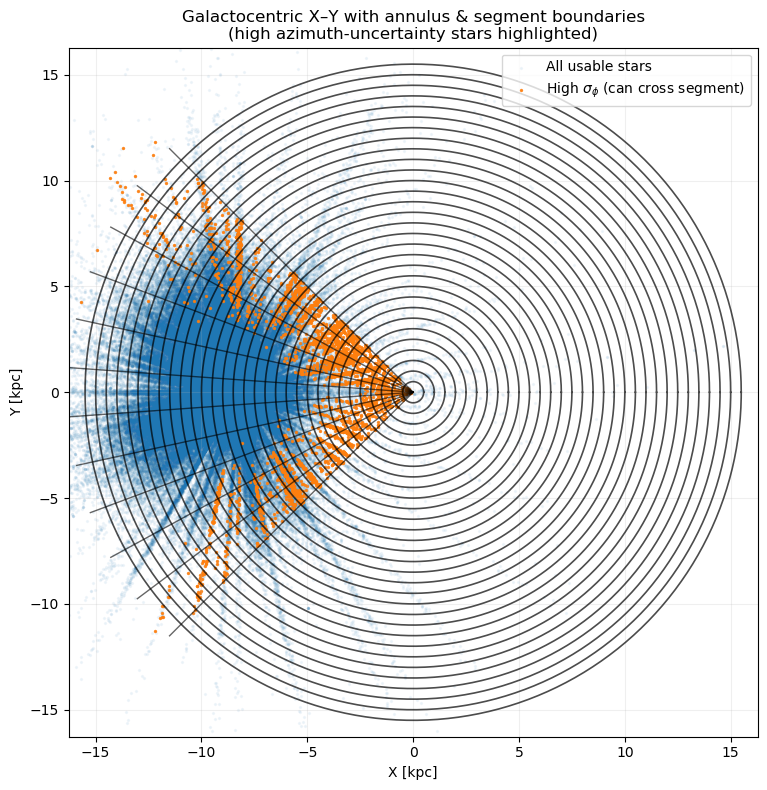

N usable stars: 391560
N high-sigma stars: 3376


In [30]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
assert len(X0) == len(Y0) == len(big_err)

# Plot extent
Rmax_plot = np.nanmax(R_edges_kept) * 1.05
theta_plot = np.linspace(0, 2*np.pi, 400)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure(figsize=(8, 8))

# --- background: all usable stars ---
plt.scatter(X0, Y0, s=2, alpha=0.05, label="All usable stars")

# --- highlight: high azimuth-uncertainty stars ---
plt.scatter(
    X0[big_err], Y0[big_err],
    s=2, alpha=0.85,
    label=r"High $\sigma_\phi$ (can cross segment)"
)

# --- annulus boundaries ---
for R in R_edges_kept:
    plt.plot(
        R*np.cos(theta_plot),
        R*np.sin(theta_plot),
        color="black", lw=1.2, alpha=0.7
    )

# --- segment (wedge) boundaries ---
for th in theta_edges:
    plt.plot(
        [0, Rmax_plot*np.cos(th)],
        [0, Rmax_plot*np.sin(th)],
        color="black", lw=1.0, alpha=0.6
    )

# ------------------------------------------------------------
# Cosmetics
# ------------------------------------------------------------
plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.title("Galactocentric X–Y with annulus & segment boundaries\n(high azimuth-uncertainty stars highlighted)")
plt.grid(alpha=0.2)
plt.legend(loc="upper right")
plt.xlim(-Rmax_plot, Rmax_plot)
plt.ylim(-Rmax_plot, Rmax_plot)
plt.tight_layout()
plt.show()

print("N usable stars:", len(X0))
print("N high-sigma stars:", int(np.sum(big_err)))


In [31]:
from astropy.coordinates import SkyCoord, Distance
import astropy.coordinates as coord
import astropy.units as u
import numpy as np

def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

t_final = t_final

plx  = col_to_float_array(t_final, "zgr_plx")  # mas
ra   = col_to_float_array(t_final, "ra")
dec  = col_to_float_array(t_final, "dec")
pmra = col_to_float_array(t_final, "pmra")
pmde = col_to_float_array(t_final, "pmde")

vrad = col_to_float_array(t_final, "v_rad") if "v_rad" in t_final.colnames else np.full(len(t_final), np.nan)
vhel = col_to_float_array(t_final, "VHELIO_AVG") if "VHELIO_AVG" in t_final.colnames else np.full(len(t_final), np.nan)
v = np.where(np.isfinite(vrad), vrad, vhel)
has_rv = np.isfinite(v)

# positions require only parallax + ra/dec
ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

# -------------------------
# 1) POSITIONS for everyone (no PM, no RV)  ✅ robust
# -------------------------
dist_pos = Distance((1000.0 / plx[ok_pos]) * u.pc)

c_pos = SkyCoord(
    ra=ra[ok_pos] * u.deg,
    dec=dec[ok_pos] * u.deg,
    distance=dist_pos,
    frame="icrs",
)

gc_pos = c_pos.transform_to(galcen_frame)

X = gc_pos.x.to_value(u.kpc)
Y = gc_pos.y.to_value(u.kpc)
Z = gc_pos.z.to_value(u.kpc)

R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)

R_all   = np.full(len(t_final), np.nan)
Z_all   = np.full(len(t_final), np.nan)
phi_all = np.full(len(t_final), np.nan)

R_all[ok_pos]   = R
Z_all[ok_pos]   = Z
phi_all[ok_pos] = phi

# -------------------------
# 2) v_z only where RV exists (full 6D) ✅
# -------------------------
ok_vz = ok_pos & np.isfinite(pmra) & np.isfinite(pmde) & has_rv

dist_vz = Distance((1000.0 / plx[ok_vz]) * u.pc)

c_vz = SkyCoord(
    ra=ra[ok_vz] * u.deg,
    dec=dec[ok_vz] * u.deg,
    distance=dist_vz,
    pm_ra_cosdec=pmra[ok_vz] * u.mas/u.yr,
    pm_dec=pmde[ok_vz] * u.mas/u.yr,
    radial_velocity=v[ok_vz] * u.km/u.s,
    frame="icrs",
)

gc_vz = c_vz.transform_to(galcen_frame)

vz_all = np.full(len(t_final), np.nan)
vz_all[ok_vz] = gc_vz.v_z.to_value(u.km/u.s)

print("N total:", len(t_final))
print("Position-valid:", int(np.sum(ok_pos)))
print("vz-computable:", int(np.sum(ok_vz)))


N total: 391560
Position-valid: 391560
vz-computable: 353522


N used for VZ annuli plot (finite R,vz,mgfe): 353522
vz range: -349.41814341409463 to 386.67279669364365
Stopping: 2 consecutive annuli with N < 100 at R~[19.5,20.0)
Plotted 37 annuli (dR=0.5) with minN=100.


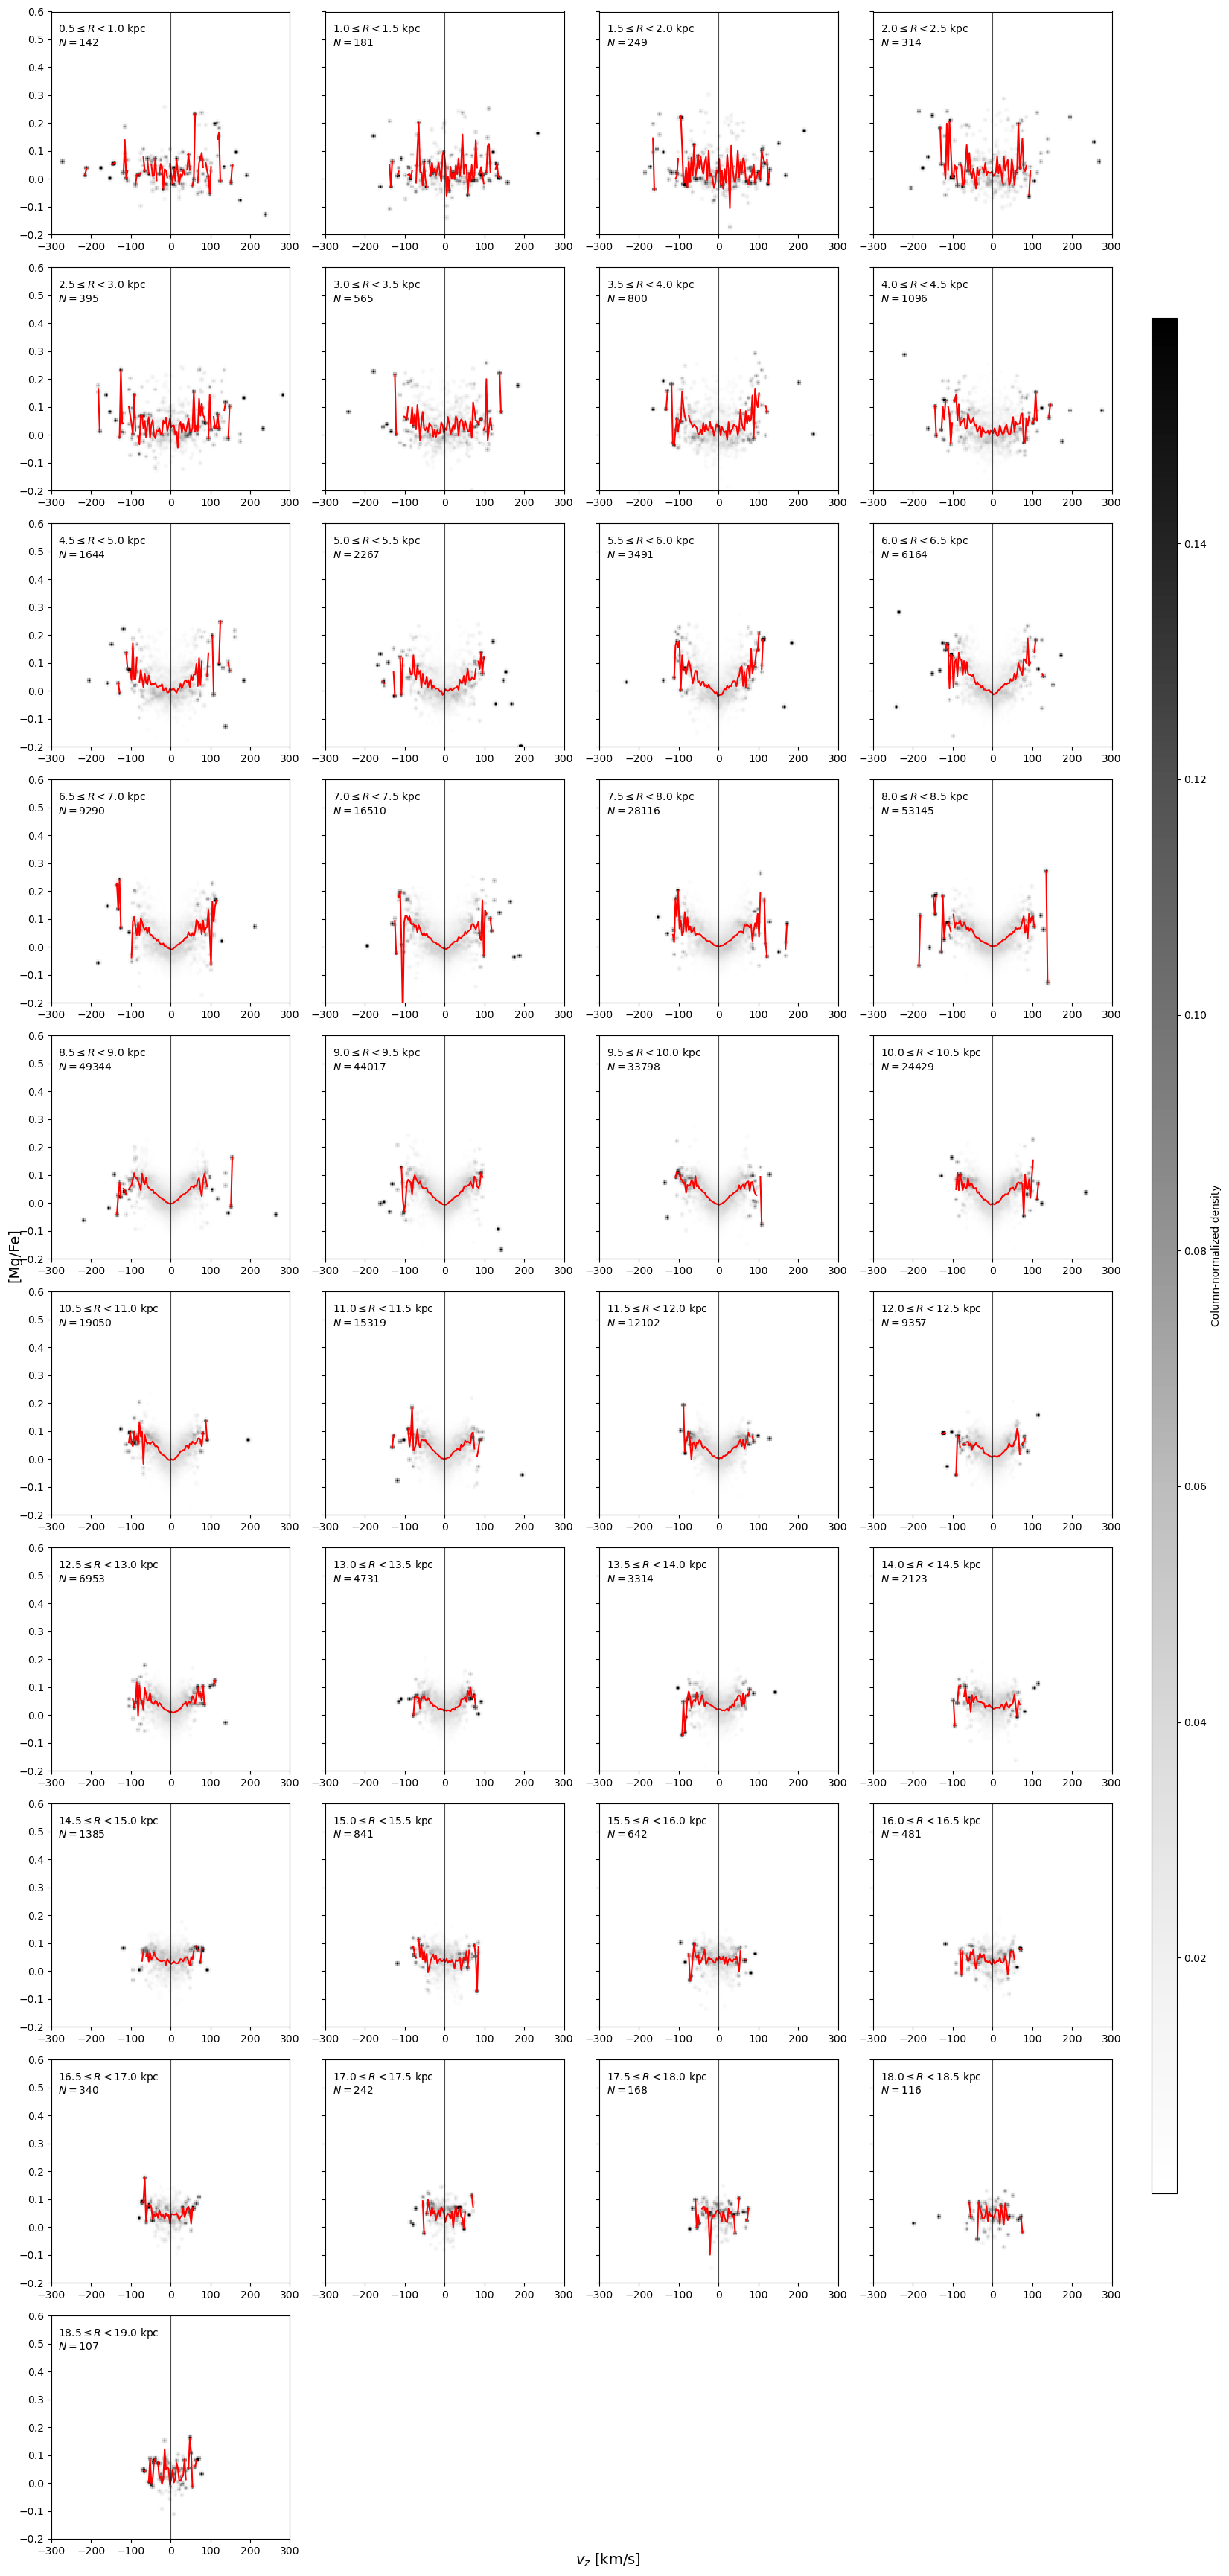

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# --- abundance (aligned with t_final) ---
mgfe_all = np.asarray(t_final["mg_h"], float) - np.asarray(t_final["fe_h"], float)
# if you have it directly:
# mgfe_all = np.asarray(t_final["MG_FE"], float)

# ============================================================
# SETTINGS
# ============================================================
dR = 0.5
minN = 100
stop_after_k_consecutive_lowN = 2
R_max_plot = None

cmap_name = "Greys"

vz_edges   = np.linspace(-300, 300, 181)   # adjust if needed
mgfe_edges = np.linspace(-0.2, 0.6, 161)
vz_centers = 0.5 * (vz_edges[:-1] + vz_edges[1:])

smooth_sigma = (1.0, 1.0)
vmin_pct, vmax_pct = 2.0, 99.7

# ============================================================
# 1) Finite mask for *this plot* (needs R, vz, mgfe)
# ============================================================
finite_all = np.isfinite(R_all) & np.isfinite(vz_all) & np.isfinite(mgfe_all)
R_use   = R_all[finite_all]
vz_use  = vz_all[finite_all]
mgfe_use = mgfe_all[finite_all]

print("N used for VZ annuli plot (finite R,vz,mgfe):", len(R_use))
print("vz range:", np.nanmin(vz_use), "to", np.nanmax(vz_use))

# ============================================================
# 2) Annuli loop with robust stop rule
# ============================================================
Rmin_data = np.nanmin(R_use)
Rmax_data = np.nanmax(R_use)

Rstart = np.floor(Rmin_data / dR) * dR
Rstop  = np.ceil(Rmax_data / dR) * dR
if R_max_plot is not None:
    Rstop = min(Rstop, R_max_plot)

annuli = []
imgs = []
mean_trends = []
Ns = []

lowN_streak = 0
seen_good = False

for Rmin in np.arange(Rstart, Rstop, dR):
    Rmax = Rmin + dR
    m = (R_use >= Rmin) & (R_use < Rmax)
    N = int(np.sum(m))

    if N < minN:
        if seen_good:
            lowN_streak += 1
            if lowN_streak >= stop_after_k_consecutive_lowN:
                print(f"Stopping: {lowN_streak} consecutive annuli with N < {minN} at R~[{Rmin:.1f},{Rmax:.1f})")
                break
        continue
    else:
        seen_good = True
        lowN_streak = 0

    vv = vz_use[m]
    aa = mgfe_use[m]

    # Column-normalized histogram P([Mg/Fe] | vz)
    H, _, _ = np.histogram2d(vv, aa, bins=[vz_edges, mgfe_edges])
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm  = np.divide(H, colsum, out=np.zeros_like(H), where=(colsum > 0))
    img = gaussian_filter(Hnorm, sigma=smooth_sigma).T

    # Mean trend in each vz bin (NO fit)
    trend = np.full_like(vz_centers, np.nan, dtype=float)
    for i in range(len(vz_edges) - 1):
        mm = (vv >= vz_edges[i]) & (vv < vz_edges[i+1])
        if np.any(mm):
            trend[i] = np.nanmean(aa[mm])

    annuli.append((Rmin, Rmax))
    imgs.append(img)
    mean_trends.append(trend)
    Ns.append(int(np.sum(m)))

print(f"Plotted {len(annuli)} annuli (dR={dR}) with minN={minN}.")
if len(annuli) == 0:
    raise RuntimeError("No annuli met minN. Lower minN or widen vz_edges.")

# ============================================================
# 3) Shared color scale across panels
# ============================================================
vals = np.concatenate([img[(img > 0) & np.isfinite(img)] for img in imgs])
if len(vals) > 0:
    vmin, vmax = np.percentile(vals, [vmin_pct, vmax_pct])
else:
    vmin, vmax = 0.0, 1.0

# ============================================================
# 4) Plot grid
# ============================================================
n_panels = len(annuli)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2 * ncols, 3.6 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

pcm = None
for i, ax in enumerate(axes.flat):
    if i >= n_panels:
        ax.axis("off")
        continue

    Rmin, Rmax = annuli[i]
    img = imgs[i]
    trend = mean_trends[i]
    N = Ns[i]

    pcm = ax.pcolormesh(
        vz_edges, mgfe_edges, img,
        shading="auto",
        vmin=vmin, vmax=vmax,
        cmap=cmap_name
    )

    ax.plot(vz_centers, trend, color="red", lw=1.5)
    ax.axvline(0, color="k", lw=0.8, alpha=0.7)

    ax.text(
        0.03, 0.95,
        rf"${Rmin:.1f}\leq R<{Rmax:.1f}$ kpc" + "\n" + rf"$N={N}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(vz_edges[0], vz_edges[-1])
    ax.set_ylim(mgfe_edges[0], mgfe_edges[-1])
    ax.tick_params(axis="x", which="both", labelbottom=True)

fig.supxlabel(r"$v_z$ [km/s]", fontsize=14)
fig.supylabel(r"[Mg/Fe]", fontsize=14)

fig.tight_layout(rect=[0.0, 0.0, 0.92, 0.97])
cax = fig.add_axes([0.935, 0.15, 0.02, 0.70])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Column-normalized density")

plt.show()

N total: 391560
Position-valid: 391560
vz-computable: 353522
Segment populations (first few):
  S1: 3333
  S2: 8911
  S3: 17866
  S4: 36843
  S5: 80319
  S6: 119901

Status counts:
 status_quad
ok               197
too_few_bins      84
too_few_stars     38
bad_curvature     11
Name: count, dtype: int64


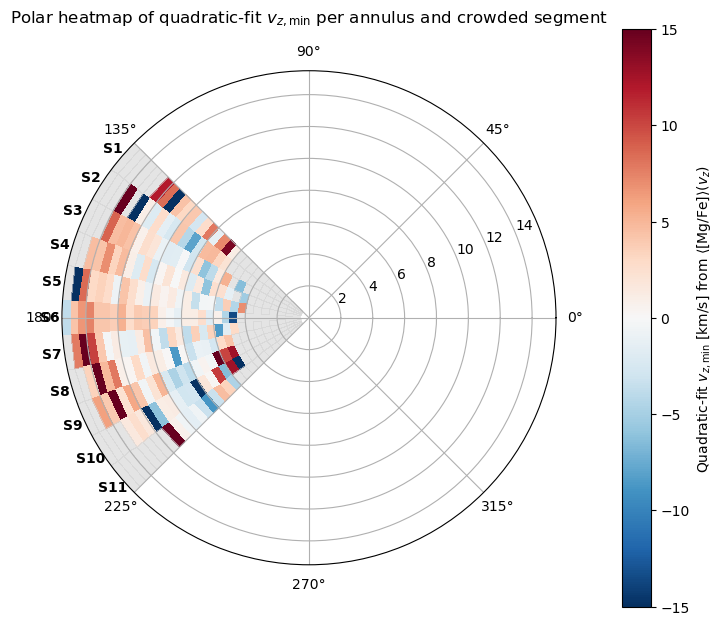

In [33]:
# ============================================================
# FULL PIPELINE (WITH ANGLE-WRAP FIX) — QUADRATIC FIT VERSION:
#   1) Build R_all, phi_all for everyone (no RV required)
#   2) Build vz_all only where RV exists (vz_all=NaN otherwise)
#   3) Build segm masks ALIGNED to t_final using *phi_unwrapped*
#   4) For each (annulus, segment), bin in vz and compute mean Mg/Fe(vz)
#   5) Fit quadratic to mean trend inside a window; take fitted minimum v_z,min
#   6) Plot polar heatmap of v_z,min
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance


# -------------------------
# Helpers
# -------------------------
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):  # MaskedColumn
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

def binned_mean_and_counts(Xs, Ys, x_edges):
    nb = len(x_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(x_edges, Xs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Xs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])

    return mean, cnt

def quad_fit_min_location(x_centers, trend, cnt,
                          xmin=-150.0, xmax=150.0,
                          min_cnt=5, min_bins=8):
    """
    Fit y = a x^2 + b x + c to (x_centers, trend) within [xmin,xmax]
    requiring cnt>=min_cnt and finite trend. Return x0 = -b/(2a) if valid.
    """
    xc  = np.asarray(x_centers)
    tr  = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    m = (xc >= xmin) & (xc <= xmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan

    x = xc[m]
    y = tr[m]

    a, b, c = np.polyfit(x, y, deg=2)

    # Need upward-opening parabola to have a minimum
    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan

    x0 = -b/(2*a)
    if not (xmin <= x0 <= xmax):
        return (a, b, c), "min_outside_window", np.nan

    return (a, b, c), "ok", float(x0)


# ============================================================
# USER INPUTS
# ============================================================
t_final = t_final   # <-- your final sample

# abundance tracer
mgfe_star = np.asarray(t_final["mg_h"], float) - np.asarray(t_final["fe_h"], float)

# crowd_bounds must exist in your session (radians, length n_th+1)
# ============================================================


# ============================================================
# PART 1: Build R_all, phi_all for everyone; vz_all for RV subset
# ============================================================
plx  = col_to_float_array(t_final, "zgr_plx")  # mas
ra   = col_to_float_array(t_final, "ra")
dec  = col_to_float_array(t_final, "dec")
pmra = col_to_float_array(t_final, "pmra")
pmde = col_to_float_array(t_final, "pmde")

vrad = col_to_float_array(t_final, "v_rad") if "v_rad" in t_final.colnames else np.full(len(t_final), np.nan)
vhel = col_to_float_array(t_final, "VHELIO_AVG") if "VHELIO_AVG" in t_final.colnames else np.full(len(t_final), np.nan)
v = np.where(np.isfinite(vrad), vrad, vhel)
has_rv = np.isfinite(v)

# position-valid (no RV required)
ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

# --- POSITIONS ONLY ---
dist_pos = Distance((1000.0 / plx[ok_pos]) * u.pc)
c_pos = SkyCoord(
    ra=ra[ok_pos] * u.deg,
    dec=dec[ok_pos] * u.deg,
    distance=dist_pos,
    frame="icrs",
)
gc_pos = c_pos.transform_to(galcen_frame)

X = gc_pos.x.to_value(u.kpc)
Y = gc_pos.y.to_value(u.kpc)
Z = gc_pos.z.to_value(u.kpc)

R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)  # [-pi, +pi]

R_all   = np.full(len(t_final), np.nan)
phi_all = np.full(len(t_final), np.nan)

R_all[ok_pos]   = R
phi_all[ok_pos] = phi

# --- v_z only where RV exists (needs PM + RV) ---
ok_vz = ok_pos & np.isfinite(pmra) & np.isfinite(pmde) & has_rv

dist_vz = Distance((1000.0 / plx[ok_vz]) * u.pc)
c_vz = SkyCoord(
    ra=ra[ok_vz] * u.deg,
    dec=dec[ok_vz] * u.deg,
    distance=dist_vz,
    pm_ra_cosdec=pmra[ok_vz] * u.mas/u.yr,
    pm_dec=pmde[ok_vz] * u.mas/u.yr,
    radial_velocity=v[ok_vz] * u.km/u.s,
    frame="icrs",
)
gc_vz = c_vz.transform_to(galcen_frame)

vz_all = np.full(len(t_final), np.nan)
vz_all[ok_vz] = gc_vz.v_z.to_value(u.km/u.s)

print("N total:", len(t_final))
print("Position-valid:", int(np.sum(ok_pos)))
print("vz-computable:", int(np.sum(ok_vz)))


# ============================================================
# PART 2: ANGLE-WRAP FIX + build segm aligned to t_final
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)

print("Segment populations (first few):")
for k in range(1, min(n_th, 6) + 1):
    print(f"  S{k}: {int(np.sum(segm[k]))}")


# ============================================================
# PART 3: Quadratic-fit v_z,min per (annulus, segment)
# ============================================================
minN_seg_total = 15      # minimum stars per (annulus, segment) to attempt
min_bin_count  = 5       # minimum stars per vz-bin to use that bin
min_bins_for_fit = 8     # minimum number of usable vz-bins for the fit

vz_win_min, vz_win_max = -150.0, 150.0
vz_edges = np.linspace(-300.0, 300.0, 181)   # adjust if you want coarser
vz_centers = 0.5 * (vz_edges[:-1] + vz_edges[1:])

R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)

R_star  = np.asarray(R_all, float)
Vz_star = np.asarray(vz_all, float)

rows = []
for ir in range(len(R_edges_kept) - 1):
    Rmin_focus = float(R_edges_kept[ir])
    Rmax_focus = float(R_edges_kept[ir + 1])

    mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

    if int(np.sum(mR)) == 0:
        for seg_id in SEG_PLOT_heat:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             vz_min_quad=np.nan, status_quad="no_stars_annulus"))
        continue

    for seg_id in SEG_PLOT_heat:
        mseg = mR & segm[seg_id]

        # must have finite Vz and finite abundance
        good = mseg & np.isfinite(Vz_star) & np.isfinite(mgfe_star)
        Nseg = int(np.sum(good))

        if Nseg < minN_seg_total:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             vz_min_quad=np.nan, status_quad="too_few_stars"))
            continue

        Vzs = Vz_star[good]
        Ys  = mgfe_star[good]

        mean_line, cnt_line = binned_mean_and_counts(Vzs, Ys, vz_edges)
        (_, _, _), st, v0 = quad_fit_min_location(
            vz_centers, mean_line, cnt_line,
            xmin=vz_win_min, xmax=vz_win_max,
            min_cnt=min_bin_count,
            min_bins=min_bins_for_fit
        )

        rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                         vz_min_quad=v0, status_quad=st))

df_quad = pd.DataFrame(rows)
print("\nStatus counts:\n", df_quad["status_quad"].value_counts(dropna=False))


# ============================================================
# PART 4: Polar heatmap of quadratic-fit v_z,min
# ============================================================
# Radial edges
R_edges_kept = np.array(
    sorted(set(df_quad["Rmin"].tolist() + df_quad["Rmax"].tolist())),
    float
)
n_r = len(R_edges_kept) - 1
n_th = len(SEG_PLOT_heat)

VZmap_raw = np.full((n_r, n_th), np.nan, float)
seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

for _, row in df_quad.iterrows():
    if row["status_quad"] != "ok":
        continue

    seg = int(row["seg"])
    if seg not in seg_to_col:
        continue

    v0 = float(row["vz_min_quad"])
    if not np.isfinite(v0):
        continue

    Rmin = float(row["Rmin"])
    ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
    if not (0 <= ir < n_r):
        continue

    VZmap_raw[ir, seg_to_col[seg]] = v0

VZmap = np.where(np.isfinite(VZmap_raw), VZmap_raw, np.nan)

# Choose a color range (this is just display)
vlim = 15.0   # try 7, 10, 15, 25 etc.

fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_kept)

pcm = ax.pcolormesh(
    TH, RR, VZmap,
    shading="flat",
    cmap=cmap,
    vmin=-vlim,
    vmax=+vlim
)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"Quadratic-fit $v_{z,\min}$ [km/s] from $\langle$[Mg/Fe]$\rangle(v_z)$")

ax.set_title(r"Polar heatmap of quadratic-fit $v_{z,\min}$ per annulus and crowded segment", y=1.08)

# Segment labels
theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_kept[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
            ha="center", va="center", fontsize=10, weight="bold")

plt.show()

N total: 391560
Position-valid: 391560
vz-computable: 353522
Segment populations (first few):
  S1: 3333
  S2: 8911
  S3: 17866
  S4: 36843
  S5: 80319
  S6: 119901
Warp-subtracted vz available for: 353522 stars

Status counts:
 status_quad
ok                    196
too_few_bins           82
too_few_stars          38
bad_curvature          13
min_outside_window      1
Name: count, dtype: int64


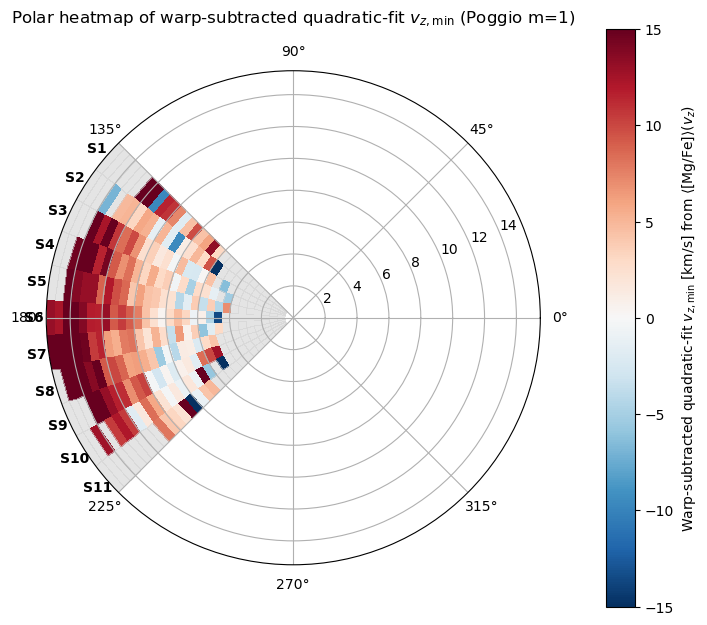

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance


# -------------------------
# Helpers
# -------------------------
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):  # MaskedColumn
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

def binned_mean_and_counts(Xs, Ys, x_edges):
    nb = len(x_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(x_edges, Xs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Xs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])

    return mean, cnt

def quad_fit_min_location(x_centers, trend, cnt,
                          xmin=-150.0, xmax=150.0,
                          min_cnt=5, min_bins=8):
    xc  = np.asarray(x_centers)
    tr  = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    m = (xc >= xmin) & (xc <= xmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < min_bins:
        return (np.nan, np.nan, np.nan), "too_few_bins", np.nan

    x = xc[m]
    y = tr[m]

    a, b, c = np.polyfit(x, y, deg=2)

    if (not np.isfinite(a)) or a <= 0:
        return (a, b, c), "bad_curvature", np.nan

    x0 = -b/(2*a)
    if not (xmin <= x0 <= xmax):
        return (a, b, c), "min_outside_window", np.nan

    return (a, b, c), "ok", float(x0)


# ============================================================
# Poggio m=1 global warp (Young Giants parameters)
#   Zw(R,phi) = hw(R) * sin(phi - phiLON(R))
#   vz_warp ~ Omega(R) * dZw/dphi = Omega(R) * hw(R)*cos(phi-phiLON)
# ============================================================
def poggio_hw_phiLON(R_kpc,
                     Rw=5.5,
                     hw0=0.012,
                     alpha_w=1.9,
                     phiLON0_deg=0.1,
                     RT=12.1,
                     beta_deg_per_kpc=9.9):
    R = np.asarray(R_kpc, float)

    hw = np.zeros_like(R, dtype=float)
    m = np.isfinite(R) & (R > Rw)
    hw[m] = hw0 * (R[m] - Rw)**alpha_w

    phiLON0 = np.deg2rad(phiLON0_deg)
    beta = np.deg2rad(beta_deg_per_kpc)  # rad/kpc

    phiLON = np.full_like(R, phiLON0, dtype=float)
    mt = np.isfinite(R) & (R > RT)
    phiLON[mt] = phiLON0 + beta * (R[mt] - RT)

    return hw, phiLON

def poggio_vz_warp(R_kpc, phi_rad, v_c_kms=238.0):
    """
    vzw = Omega(R) * hw(R) * cos(phi - phiLON(R))
    Omega(R) = v_c / R   [km/s/kpc]
    Multiply by kpc -> km/s, so units work out.
    """
    R = np.asarray(R_kpc, float)
    phi = np.asarray(phi_rad, float)

    hw, phiLON = poggio_hw_phiLON(R)

    Omega = np.full_like(R, np.nan, dtype=float)
    good = np.isfinite(R) & (R > 0)
    Omega[good] = v_c_kms / R[good]  # (km/s)/kpc

    return Omega * hw * np.cos(phi - phiLON)  # km/s


# ============================================================
# USER INPUTS
# ============================================================
t_final = t_final   # your final sample
mgfe_star = np.asarray(t_final["mg_h"], float) - np.asarray(t_final["fe_h"], float)

# crowd_bounds must exist (radians)
# ============================================================


# ============================================================
# PART 1: Build R_all, phi_all for everyone; vz_all for RV subset
# ============================================================
plx  = col_to_float_array(t_final, "zgr_plx")  # mas
ra   = col_to_float_array(t_final, "ra")
dec  = col_to_float_array(t_final, "dec")
pmra = col_to_float_array(t_final, "pmra")
pmde = col_to_float_array(t_final, "pmde")

vrad = col_to_float_array(t_final, "v_rad") if "v_rad" in t_final.colnames else np.full(len(t_final), np.nan)
vhel = col_to_float_array(t_final, "VHELIO_AVG") if "VHELIO_AVG" in t_final.colnames else np.full(len(t_final), np.nan)
v = np.where(np.isfinite(vrad), vrad, vhel)
has_rv = np.isfinite(v)

ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

# positions only
dist_pos = Distance((1000.0 / plx[ok_pos]) * u.pc)
c_pos = SkyCoord(ra=ra[ok_pos]*u.deg, dec=dec[ok_pos]*u.deg, distance=dist_pos, frame="icrs")
gc_pos = c_pos.transform_to(galcen_frame)

X = gc_pos.x.to_value(u.kpc)
Y = gc_pos.y.to_value(u.kpc)
R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)

R_all   = np.full(len(t_final), np.nan)
phi_all = np.full(len(t_final), np.nan)
R_all[ok_pos]   = R
phi_all[ok_pos] = phi

# vz only where RV exists
ok_vz = ok_pos & np.isfinite(pmra) & np.isfinite(pmde) & has_rv
dist_vz = Distance((1000.0 / plx[ok_vz]) * u.pc)

c_vz = SkyCoord(
    ra=ra[ok_vz] * u.deg,
    dec=dec[ok_vz] * u.deg,
    distance=dist_vz,
    pm_ra_cosdec=pmra[ok_vz] * u.mas/u.yr,
    pm_dec=pmde[ok_vz] * u.mas/u.yr,
    radial_velocity=v[ok_vz] * u.km/u.s,
    frame="icrs",
)
gc_vz = c_vz.transform_to(galcen_frame)

vz_all = np.full(len(t_final), np.nan)
vz_all[ok_vz] = gc_vz.v_z.to_value(u.km/u.s)

print("N total:", len(t_final))
print("Position-valid:", int(np.sum(ok_pos)))
print("vz-computable:", int(np.sum(ok_vz)))


# ============================================================
# PART 2: ANGLE-WRAP FIX + segm aligned to t_final
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)

print("Segment populations (first few):")
for k in range(1, min(n_th, 6) + 1):
    print(f"  S{k}: {int(np.sum(segm[k]))}")


# ============================================================
# PART 2.5: Warp-subtract vz: vz_corr = vz - vz_warp(R,phi)
# ============================================================
v_c_kms = 238.0  # tune if you want
vz_warp = np.full_like(vz_all, np.nan, dtype=float)

ok_w = np.isfinite(R_all) & np.isfinite(phi_u) & np.isfinite(vz_all)
vz_warp[ok_w] = poggio_vz_warp(R_all[ok_w], phi_u[ok_w], v_c_kms=v_c_kms)

vz_corr = np.full_like(vz_all, np.nan, dtype=float)
vz_corr[ok_w] = vz_all[ok_w] - vz_warp[ok_w]

print("Warp-subtracted vz available for:", int(np.sum(np.isfinite(vz_corr))), "stars")


# ============================================================
# PART 3: Quadratic-fit v_z,min per (annulus, segment) using vz_corr
# ============================================================
minN_seg_total = 15
min_bin_count  = 5
min_bins_for_fit = 8

vz_win_min, vz_win_max = -150.0, 150.0
vz_edges = np.linspace(-300.0, 300.0, 181)
vz_centers = 0.5 * (vz_edges[:-1] + vz_edges[1:])

R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)

R_star  = np.asarray(R_all, float)
Vz_star = np.asarray(vz_corr, float)   # <-- USE WARP-SUBTRACTED HERE

rows = []
for ir in range(len(R_edges_kept) - 1):
    Rmin_focus = float(R_edges_kept[ir])
    Rmax_focus = float(R_edges_kept[ir + 1])

    mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

    if int(np.sum(mR)) == 0:
        for seg_id in SEG_PLOT_heat:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             vz_min_quad=np.nan, status_quad="no_stars_annulus"))
        continue

    for seg_id in SEG_PLOT_heat:
        mseg = mR & segm[seg_id]
        good = mseg & np.isfinite(Vz_star) & np.isfinite(mgfe_star)
        Nseg = int(np.sum(good))

        if Nseg < minN_seg_total:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             vz_min_quad=np.nan, status_quad="too_few_stars"))
            continue

        Vzs = Vz_star[good]
        Ys  = mgfe_star[good]

        mean_line, cnt_line = binned_mean_and_counts(Vzs, Ys, vz_edges)
        (_, _, _), st, v0 = quad_fit_min_location(
            vz_centers, mean_line, cnt_line,
            xmin=vz_win_min, xmax=vz_win_max,
            min_cnt=min_bin_count,
            min_bins=min_bins_for_fit
        )

        rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                         vz_min_quad=v0, status_quad=st))

df_quad = pd.DataFrame(rows)
print("\nStatus counts:\n", df_quad["status_quad"].value_counts(dropna=False))


# ============================================================
# PART 4: Polar heatmap
# ============================================================
R_edges_plot = np.array(sorted(set(df_quad["Rmin"].tolist() + df_quad["Rmax"].tolist())), float)
n_r = len(R_edges_plot) - 1
n_th = len(SEG_PLOT_heat)

VZmap_raw = np.full((n_r, n_th), np.nan, float)
seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

for _, row in df_quad.iterrows():
    if row["status_quad"] != "ok":
        continue
    seg = int(row["seg"])
    if seg not in seg_to_col:
        continue
    v0 = float(row["vz_min_quad"])
    if not np.isfinite(v0):
        continue
    Rmin = float(row["Rmin"])
    ir = np.searchsorted(R_edges_plot, Rmin, side="right") - 1
    if 0 <= ir < n_r:
        VZmap_raw[ir, seg_to_col[seg]] = v0

VZmap = np.where(np.isfinite(VZmap_raw), VZmap_raw, np.nan)

vlim = 15.0  # display range
fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_plot)

pcm = ax.pcolormesh(TH, RR, VZmap, shading="flat", cmap=cmap, vmin=-vlim, vmax=+vlim)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"Warp-subtracted quadratic-fit $v_{z,\min}$ [km/s] from $\langle$[Mg/Fe]$\rangle(v_z)$")

ax.set_title(r"Polar heatmap of warp-subtracted quadratic-fit $v_{z,\min}$ (Poggio m=1)", y=1.08)

theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_plot[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}", ha="center", va="center",
            fontsize=10, weight="bold")

plt.show()

N total: 391560
Position-valid: 391560
6D (vz,vphi) computable: 353522
vz_sub available for: 353522 stars

Status counts:
 status_bin
ok               233
too_few_bins      59
too_few_stars     38
Name: count, dtype: int64


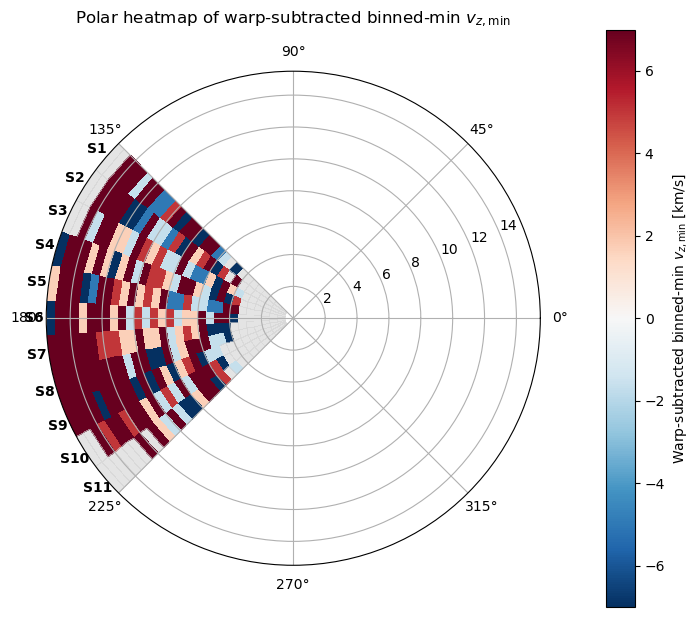

In [35]:
# ============================================================
# FULL PIPELINE: Vz WARP-SUBTRACTED heatmap using Poggio-style m=1 model
#
# Key idea:
#   Z_w(R,phi) = h_w(R) * sin(phi - phi_LON(R))
#   dZ_w/dphi  = h_w(R) * cos(phi - phi_LON(R))
#   v_z,warp ~ (Omega - Omega_p) * dZ_w/dphi
#            ~ (vphi/R - Omega_p) * h_w(R) * cos(phase)
#
# IMPORTANT:
# - This produces a MODEL-DEPENDENT warp-subtracted vz field.
# - Requires vphi, so only applies to the same RV+PM subset where vz exists.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance


# -------------------------
# Helpers
# -------------------------
def col_to_float_array(table, name):
    col = table[name]
    if hasattr(col, "filled"):  # MaskedColumn
        return np.asarray(col.filled(np.nan), float)
    return np.asarray(col, float)

def binned_mean_and_counts(Xs, Ys, x_edges):
    nb = len(x_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    inds = np.searchsorted(x_edges, Xs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Xs) & np.isfinite(Ys)
    inds = inds[ok]
    Ys   = Ys[ok]

    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])

    return mean, cnt

def binned_min_location(x_centers, trend, cnt,
                        xmin=-150.0, xmax=150.0,
                        min_cnt=5):
    xc  = np.asarray(x_centers)
    tr  = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    m = (xc >= xmin) & (xc <= xmax) & np.isfinite(tr) & (cnt >= min_cnt)
    if np.sum(m) < 3:
        return "too_few_bins", np.nan

    i0 = np.nanargmin(tr[m])
    return "ok", float(xc[m][i0])

def poggio_m1_hw_phiLON(R_kpc,
                        Rw=5.5,
                        hw0=0.012,
                        alpha_w=1.9,
                        phiLON0_deg=0.1,
                        RT=12.1,
                        beta_deg_per_kpc=9.9):
    """
    Return h_w(R) and phi_LON(R) for a Poggio-style m=1 warp with twist.
    """
    R = np.asarray(R_kpc, float)

    # amplitude h_w(R)
    hw = np.zeros_like(R, dtype=float)
    m = np.isfinite(R) & (R > Rw)
    hw[m] = hw0 * (R[m] - Rw)**alpha_w

    # line of nodes phi_LON(R)
    phiLON0 = np.deg2rad(phiLON0_deg)
    beta = np.deg2rad(beta_deg_per_kpc)  # rad/kpc

    phiLON = np.full_like(R, phiLON0, dtype=float)
    mt = np.isfinite(R) & (R > RT)
    phiLON[mt] = phiLON0 + beta * (R[mt] - RT)

    return hw, phiLON


# ============================================================
# USER INPUTS
# ============================================================
# Must exist in your session:
#   t_final (final sample table)
#   crowd_bounds (radians, edges length n_th+1)
# ============================================================

# Abundance tracer used in your "vz_min of mgfe(vz)" statistic
mgfe_star = np.asarray(t_final["mg_h"], float) - np.asarray(t_final["fe_h"], float)

# --- Warp model parameters (edit if you want a different Poggio fit) ---
warp_params = dict(
    Rw=5.5,
    hw0=0.012,
    alpha_w=1.9,
    phiLON0_deg=0.1,
    RT=12.1,
    beta_deg_per_kpc=9.9
)

# Warp pattern speed Omega_p in (km/s)/kpc
# - If you don't want to assume a rotating warp, set Omega_p_kmskpc = 0.0
Omega_p_kmskpc = 0.0


# ============================================================
# PART 1: Build R_all, phi_all, Z_all for everyone; vz_all + vphi_all for RV subset
# ============================================================
plx  = col_to_float_array(t_final, "zgr_plx")  # mas
ra   = col_to_float_array(t_final, "ra")
dec  = col_to_float_array(t_final, "dec")
pmra = col_to_float_array(t_final, "pmra")
pmde = col_to_float_array(t_final, "pmde")

vrad = col_to_float_array(t_final, "v_rad") if "v_rad" in t_final.colnames else np.full(len(t_final), np.nan)
vhel = col_to_float_array(t_final, "VHELIO_AVG") if "VHELIO_AVG" in t_final.colnames else np.full(len(t_final), np.nan)
v = np.where(np.isfinite(vrad), vrad, vhel)
has_rv = np.isfinite(v)

ok_pos = np.isfinite(plx) & (plx > 0) & np.isfinite(ra) & np.isfinite(dec)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

# Positions only
dist_pos = Distance((1000.0 / plx[ok_pos]) * u.pc)
c_pos = SkyCoord(
    ra=ra[ok_pos] * u.deg,
    dec=dec[ok_pos] * u.deg,
    distance=dist_pos,
    frame="icrs",
)
gc_pos = c_pos.transform_to(galcen_frame)

X = gc_pos.x.to_value(u.kpc)
Y = gc_pos.y.to_value(u.kpc)
Z = gc_pos.z.to_value(u.kpc)

R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)  # [-pi,pi]

R_all   = np.full(len(t_final), np.nan)
phi_all = np.full(len(t_final), np.nan)
Z_all   = np.full(len(t_final), np.nan)

R_all[ok_pos]   = R
phi_all[ok_pos] = phi
Z_all[ok_pos]   = Z

# 6D subset for vz + vphi
ok_6d = ok_pos & np.isfinite(pmra) & np.isfinite(pmde) & has_rv

dist_6d = Distance((1000.0 / plx[ok_6d]) * u.pc)
c_6d = SkyCoord(
    ra=ra[ok_6d] * u.deg,
    dec=dec[ok_6d] * u.deg,
    distance=dist_6d,
    pm_ra_cosdec=pmra[ok_6d] * u.mas/u.yr,
    pm_dec=pmde[ok_6d] * u.mas/u.yr,
    radial_velocity=v[ok_6d] * u.km/u.s,
    frame="icrs",
)
gc_6d = c_6d.transform_to(galcen_frame)

vz_all   = np.full(len(t_final), np.nan)
vphi_all = np.full(len(t_final), np.nan)

VZ = gc_6d.v_z.to_value(u.km/u.s)
VX = gc_6d.v_x.to_value(u.km/u.s)
VY = gc_6d.v_y.to_value(u.km/u.s)

# Need X,Y for the 6D subset too to compute vphi
X6 = gc_6d.x.to_value(u.kpc)
Y6 = gc_6d.y.to_value(u.kpc)
R6 = np.sqrt(X6**2 + Y6**2)

goodR = np.isfinite(R6) & (R6 > 1e-6)
vphi6 = np.full_like(VZ, np.nan, dtype=float)
vphi6[goodR] = (-X6[goodR]*VY[goodR] + Y6[goodR]*VX[goodR]) / R6[goodR]

vz_all[ok_6d] = VZ
vphi_all[ok_6d] = vphi6

print("N total:", len(t_final))
print("Position-valid:", int(np.sum(ok_pos)))
print("6D (vz,vphi) computable:", int(np.sum(ok_6d)))


# ============================================================
# PART 2: ANGLE-WRAP FIX + build segm aligned to t_final
# ============================================================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)


# ============================================================
# PART 3: Compute warp-induced vz and subtract it
# ============================================================
vz_sub = np.full(len(t_final), np.nan, dtype=float)

# Only where we have vz, vphi, R, phi_u
ok_wv = np.isfinite(vz_all) & np.isfinite(vphi_all) & np.isfinite(R_all) & np.isfinite(phi_u)

hw, phiLON = poggio_m1_hw_phiLON(R_all[ok_wv], **warp_params)
phase = phi_u[ok_wv] - phiLON

# Omega = vphi/R in (km/s)/kpc
Omega_kmskpc = vphi_all[ok_wv] / R_all[ok_wv]

# vz_warp ~ (Omega - Omega_p) * hw * cos(phase)
vz_warp = (Omega_kmskpc - Omega_p_kmskpc) * hw * np.cos(phase)

vz_sub[ok_wv] = vz_all[ok_wv] - vz_warp

print("vz_sub available for:", int(np.sum(np.isfinite(vz_sub))), "stars")


# ============================================================
# PART 4: Compute NO-FIT binned-min vz_min per (annulus, segment) using vz_sub
# ============================================================
minN_seg_total = 15
min_bin_count  = 5

vz_win_min, vz_win_max = -150.0, 150.0
vz_edges = np.linspace(-300.0, 300.0, 181)
vz_centers = 0.5 * (vz_edges[:-1] + vz_edges[1:])

R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)

R_star  = np.asarray(R_all, float)
Vz_star = np.asarray(vz_sub, float)   # <-- WARP-SUBTRACTED vz used here

rows = []
for ir in range(len(R_edges_kept) - 1):
    Rmin_focus = float(R_edges_kept[ir])
    Rmax_focus = float(R_edges_kept[ir + 1])

    mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

    if int(np.sum(mR)) == 0:
        for seg_id in SEG_PLOT_heat:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             vz_min_bin=np.nan, status_bin="no_stars_annulus"))
        continue

    for seg_id in SEG_PLOT_heat:
        mseg = mR & segm[seg_id]

        good = mseg & np.isfinite(Vz_star) & np.isfinite(mgfe_star)
        Nseg = int(np.sum(good))

        if Nseg < minN_seg_total:
            rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                             vz_min_bin=np.nan, status_bin="too_few_stars"))
            continue

        Vzs = Vz_star[good]
        Ys  = mgfe_star[good]

        mean_line, cnt_line = binned_mean_and_counts(Vzs, Ys, vz_edges)
        st, v0 = binned_min_location(
            vz_centers, mean_line, cnt_line,
            xmin=vz_win_min, xmax=vz_win_max,
            min_cnt=min_bin_count
        )

        rows.append(dict(Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                         vz_min_bin=v0, status_bin=st))

df_bin = pd.DataFrame(rows)
print("\nStatus counts:\n", df_bin["status_bin"].value_counts(dropna=False))


# ============================================================
# PART 5: Polar heatmap (warp-subtracted vz_min)
# ============================================================
R_edges_kept = np.array(
    sorted(set(df_bin["Rmin"].tolist() + df_bin["Rmax"].tolist())),
    float
)
n_r = len(R_edges_kept) - 1
n_th = len(SEG_PLOT_heat)

VZmap_raw = np.full((n_r, n_th), np.nan, float)
seg_to_col = {seg: j for j, seg in enumerate(SEG_PLOT_heat)}

for _, row in df_bin.iterrows():
    if row["status_bin"] != "ok":
        continue
    seg = int(row["seg"])
    if seg not in seg_to_col:
        continue
    vmin0 = float(row["vz_min_bin"])
    if not np.isfinite(vmin0):
        continue
    Rmin = float(row["Rmin"])
    ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
    if not (0 <= ir < n_r):
        continue
    it = seg_to_col[seg]
    VZmap_raw[ir, it] = vmin0

VZmap = np.where(np.isfinite(VZmap_raw), VZmap_raw, np.nan)

fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_kept)

pcm = ax.pcolormesh(
    TH, RR, VZmap,
    shading="flat",
    cmap=cmap,
    vmin=-7,
    vmax=+7
)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label(r"Warp-subtracted binned-min $v_{z,\min}$ [km/s]")

ax.set_title(r"Polar heatmap of warp-subtracted binned-min $v_{z,\min}$", y=1.08)

theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_kept[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
            ha="center", va="center", fontsize=10, weight="bold")

plt.show()

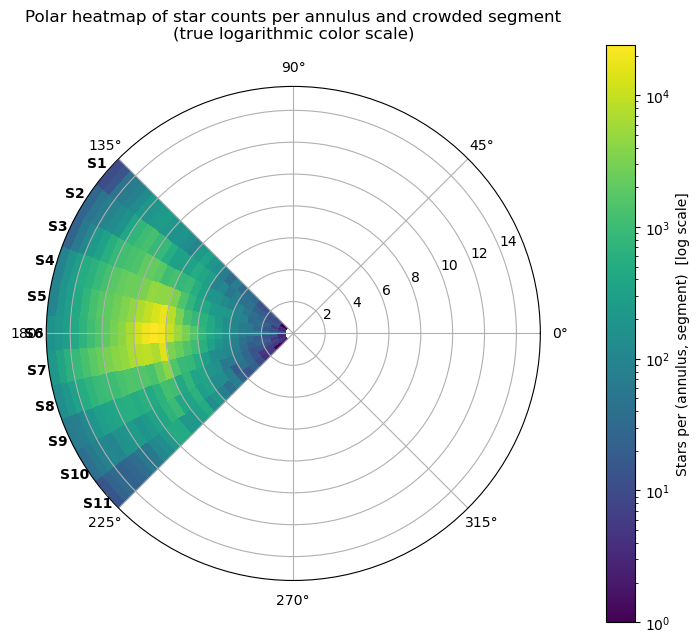

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ============================================================
# POLAR HEATMAP: star COUNTS per (annulus, crowded segment)
# TRUE logarithmic color scale (LogNorm)
# ============================================================

# ----------------------------
# SETTINGS
# ----------------------------
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

min_count_for_log = 1     # smallest nonzero value shown
vmax_count = None         # set to e.g. 5e4 if you want to clip the top

# ----------------------------
# INPUT ARRAYS (aligned to t_final)
# ----------------------------
R_star  = np.asarray(R_all, float)
phi_all = np.asarray(phi_all, float)

# ----------------------------
# theta_edges (monotonic)
# ----------------------------
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

# ----------------------------
# angle-wrap fix (CRITICAL)
# ----------------------------
theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

# ----------------------------
# segment masks
# ----------------------------
segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)

# ----------------------------
# build count map
# ----------------------------
R_edges_kept = np.asarray(R_edges, float)
n_r = len(R_edges_kept) - 1

Nmap = np.full((n_r, n_th), np.nan)

for ir in range(n_r):
    Rmin = R_edges_kept[ir]
    Rmax = R_edges_kept[ir+1]

    mR = np.isfinite(R_star) & (R_star >= Rmin) & (R_star < Rmax)

    for j, seg_id in enumerate(SEG_PLOT_heat):
        mseg = mR & segm[seg_id]
        N = np.sum(mseg)
        if N > 0:
            Nmap[ir, j] = N   # keep zeros as NaN so LogNorm works

# ----------------------------
# Plot (TRUE log scale)
# ----------------------------
fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")

ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

cmap = plt.cm.viridis.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_kept)

pcm = ax.pcolormesh(
    TH, RR, Nmap,
    shading="flat",
    cmap=cmap,
    norm=LogNorm(vmin=min_count_for_log, vmax=vmax_count)
)

cb = fig.colorbar(pcm, ax=ax, pad=0.10)
cb.set_label("Stars per (annulus, segment)  [log scale]")

ax.set_title(
    "Polar heatmap of star counts per annulus and crowded segment\n"
    "(true logarithmic color scale)",
    y=1.08
)

# segment labels
theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_kept[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
            ha="center", va="center", fontsize=10, weight="bold")

plt.show()

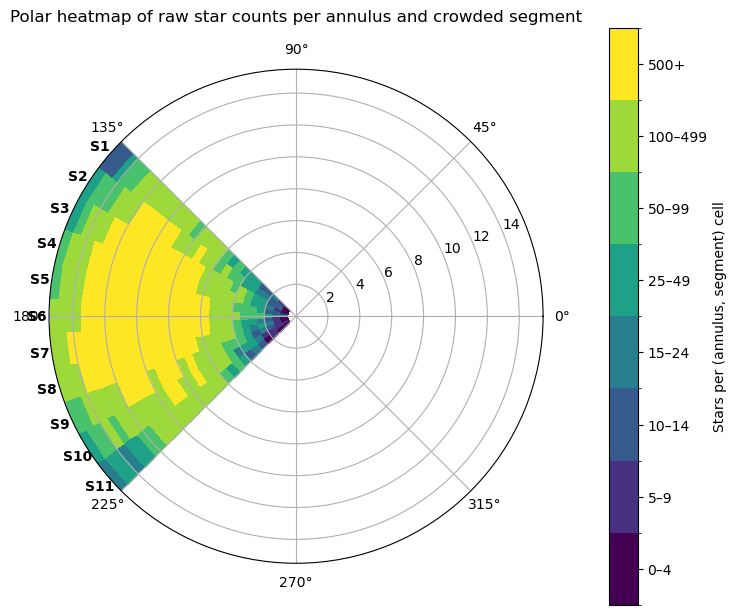

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

# ============================
# SETTINGS
# ============================
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

# count buckets you care about (edit freely)
# This makes categories: [0-4], [5-9], [10-14], [15-24], [25-49], [50-99], [100+]
count_bins = np.array([0, 5, 10, 15, 25, 50, 100, 500, 100000000], dtype=float)

# ============================
# INPUT ARRAYS (aligned to t_final)
# ============================
R_star  = np.asarray(R_all, float)
phi_all = np.asarray(phi_all, float)

# ============================
# theta_edges (monotonic)
# ============================
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i-1]:
        theta_edges[i] += 2*np.pi

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

# ============================
# angle-wrap fix
# ============================
theta0 = theta_edges[0]
phi_u = np.full_like(phi_all, np.nan, dtype=float)
mphi = np.isfinite(phi_all)
phi_u[mphi] = ((phi_all[mphi] - theta0) % (2*np.pi)) + theta0

# ============================
# segment masks
# ============================
segm = {}
for j in range(n_th):
    segm[j+1] = (phi_u >= theta_edges[j]) & (phi_u < theta_edges[j+1]) & np.isfinite(phi_u)

# ============================
# build raw count map
# ============================
R_edges_kept = np.asarray(R_edges, float)
n_r = len(R_edges_kept) - 1

Nmap = np.full((n_r, n_th), np.nan, float)

for ir in range(n_r):
    Rmin = float(R_edges_kept[ir])
    Rmax = float(R_edges_kept[ir+1])

    mR = np.isfinite(R_star) & (R_star >= Rmin) & (R_star < Rmax)

    for j, seg_id in enumerate(SEG_PLOT_heat):
        mseg = mR & segm[seg_id]
        Nmap[ir, j] = int(np.sum(mseg))

# ============================
# DISCRETE plotting
# ============================
fig = plt.figure(figsize=(8.5, 7.5))
ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)

# discrete normalization
cmap = plt.cm.viridis.copy()
cmap.set_bad(color="lightgray", alpha=0.6)
norm = BoundaryNorm(count_bins, ncolors=cmap.N, clip=True)

TH, RR = np.meshgrid(theta_edges, R_edges_kept)

pcm = ax.pcolormesh(
    TH, RR, Nmap,
    shading="flat",
    cmap=cmap,
    norm=norm
)

# Colorbar with category labels
cb = fig.colorbar(pcm, ax=ax, pad=0.10)
# put ticks at bin centers for nicer labels
tick_locs = 0.5 * (count_bins[:-1] + count_bins[1:])
cb.set_ticks(tick_locs)

labels = []
for a, b in zip(count_bins[:-1], count_bins[1:]):
    if b >= 1_000_000:
        labels.append(f"{int(a)}+")
    else:
        labels.append(f"{int(a)}–{int(b-1)}")
cb.set_ticklabels(labels)
cb.set_label("Stars per (annulus, segment) cell")

ax.set_title("Polar heatmap of raw star counts per annulus and crowded segment", y=1.08)

# segment labels
theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_kept[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax.text(th, r_label, f"S{SEG_PLOT_heat[j]}",
            ha="center", va="center", fontsize=10, weight="bold")

plt.show()


## Poggio Data

In [135]:
import tarfile

tar_path = "J_A+A_699_A199.tar.gz"   # adjust path if needed
extract_dir = "A199_data"            # folder name you want

with tarfile.open(tar_path, "r:gz") as tar:
    tar.extractall(path=extract_dir)

print("Extracted to:", extract_dir)

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_18321/3104753954.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


PermissionError: [Errno 13] Permission denied: 'A199_data/./ReadMe'

In [136]:
import os, glob

extract_dir = "A199_data"

print("Top-level contents:")
print(os.listdir(extract_dir))

print("\nA few files (recursive):")
print(glob.glob(extract_dir + "/**/*", recursive=True)[:30])

Top-level contents:
['catalog.dat.gz', 'ReadMe']

A few files (recursive):
['A199_data/catalog.dat.gz', 'A199_data/ReadMe']


In [137]:
with open("A199_data/ReadMe", "r") as f:
    print(f.read())

J/A+A/699/A199      The Great Wave - Young giant sample          (Poggio+, 2025)
The Great Wave. Evidence of a large-scale vertical corrugation propagating
outwards in the Galactic disc.
    Poggio E., Khanna S., Drimmel R., Zari E., D'Onghia E., Lattanzi M.G.,
    Palicio P.A., Recio-Blanco A., Thulasidharan L.
    <Astron. Astrophys. 699, A199 (2025)>
    =2025A&A...699A.199P        (SIMBAD/NED BibCode)
ADC_Keywords: Milky Way ; Stars, luminous ; Stars, giant ; Stars, distances ;
              Proper motions ; Optical
Keywords: Galaxy: disk - Galaxy: evolution - Galaxy: kinematics and dynamics -
          Galaxy: stellar content - Galaxy: structure

Abstract:
    We analyse the three-dimensional structure and kinematics of two
    samples of young stars in the Galactic disc, containing respectively
    young giants (~17000 stars out to heliocentric distances of ~7kpc) and
    classical Cepheids (~3400 stars out to heliocentric distances of
    ~15kpc). The vertical structure of the t

In [138]:
import gzip

with gzip.open("A199_data/catalog.dat.gz", "rt") as f:
    for i in range(20):
        print(f.readline().rstrip())

 143146797507004160 148.49737684523 -18.13581459873  7.14 1.10142  0.06780   2.6731 14.627686
 143482732668828672 147.29131298199 -17.88763326818  4.54 0.44969  0.20103   9.3141 10.957425
 143483076266215424 147.24184070502 -17.91973647590  7.16 0.82773  0.06377   2.4476 14.570291
 143671505071363968 148.23519784415 -16.62056618291  5.25 0.73480  0.14769   5.2335 14.790254
 144695562712901248 177.16638626524 -17.26908869623  7.08 1.01734  0.08461   3.6728 14.237720
 145128834718188672 176.02406819990 -16.54324870624  5.27 0.42752  0.17532  10.7411 13.005468
 145153303147210624 176.09175984553 -16.36071082468  6.59 1.14285 -0.07103  -1.4082 14.624819
 145642959483296640 173.95376203706 -19.03616086498  6.31 0.85677  0.09148   3.3562 14.571665
 146598984843034624 176.36629293182 -14.89147220915  3.06 0.48892  0.27530   4.6406 14.300807
 146828580910862080 176.02459383677 -14.39354144255  1.51 0.06831  0.65966  16.8706  9.079337
 147712794418077824 174.75791683220 -14.91618477803  2.65 0.

Stars used (finite l,b,d): 17030
Bins with >= 2 stars: 2884


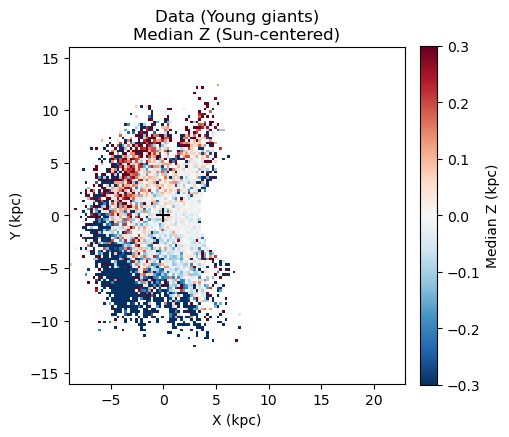

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1) Load Poggio catalog columns
#    Based on your ReadMe: GaiaDR3, GLON, GLAT, Dist, e_Dist, PlxCor, q_Dist, Gmag
#    Your file has 8 columns in the preview.
# ============================================================

path = "A199_data/catalog.dat.gz"

colnames = ["source_id", "glon_deg", "glat_deg", "dist_kpc", "edist_kpc", "plxcor_mas", "q_dist", "gmag"]
df = pd.read_csv(path, sep=r"\s+", header=None, names=colnames, comment="#")

# Keep only finite + positive distances
m = np.isfinite(df["glon_deg"]) & np.isfinite(df["glat_deg"]) & np.isfinite(df["dist_kpc"]) & (df["dist_kpc"] > 0)
df = df.loc[m].copy()

l = np.deg2rad(df["glon_deg"].to_numpy())
b = np.deg2rad(df["glat_deg"].to_numpy())
d = df["dist_kpc"].to_numpy()

# ============================================================
# 2) Convert (l,b,d) -> Sun-centered Cartesian (kpc)
#    This matches their caption: Sun at (0,0)
# ============================================================
X = d * np.cos(b) * np.cos(l)
Y = d * np.cos(b) * np.sin(l)
Z = d * np.sin(b)

# ============================================================
# 3) Bin in X-Y and compute median Z per bin
# ============================================================
def binned_median_xy(x, y, z, xedges, yedges, min_count=5):
    x = np.asarray(x); y = np.asarray(y); z = np.asarray(z)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(z)
    x = x[ok]; y = y[ok]; z = z[ok]

    nx = len(xedges) - 1
    ny = len(yedges) - 1

    ix = np.searchsorted(xedges, x, side="right") - 1
    iy = np.searchsorted(yedges, y, side="right") - 1
    inside = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)

    ix = ix[inside]; iy = iy[inside]; z = z[inside]

    N = np.zeros((ny, nx), dtype=int)
    np.add.at(N, (iy, ix), 1)

    Zmed = np.full((ny, nx), np.nan, float)
    bins = [[[] for _ in range(nx)] for __ in range(ny)]
    for j, i, val in zip(iy, ix, z):
        bins[j][i].append(val)

    for j in range(ny):
        for i in range(nx):
            if N[j, i] >= min_count:
                Zmed[j, i] = np.median(bins[j][i])

    return Zmed, N

# Match the paper-ish panel size (tweak if needed)
bin_kpc     = 0.25
min_per_bin = 2     # paper is smoother than min=5
xy_lim      = 16.0
vlim        = 0.30   # they show ~ +/-0.3 in the young-giant panel

xedges = np.arange(-xy_lim, xy_lim + bin_kpc, bin_kpc)
yedges = np.arange(-xy_lim, xy_lim + bin_kpc, bin_kpc)

Zmed, Nbin = binned_median_xy(X, Y, Z, xedges, yedges, min_count=min_per_bin)

# ============================================================
# 4) Plot: this should now look like their "Data" panel style
# ============================================================
fig, ax = plt.subplots(figsize=(5.2, 5.2))

im = ax.imshow(
    Zmed,
    origin="lower",cmap=plt.cm.RdBu_r,
    extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
    vmin=-vlim, vmax=+vlim,
    interpolation="nearest",
    aspect="equal"
)

# Sun at (0,0) cross
ax.plot(0, 0, marker="+", color="black", markersize=10, mew=1.5)

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_title("Data (Young giants)\nMedian Z (Sun-centered)")
ax.set_xlim(-9, 23)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Median Z (kpc)")

print("Stars used (finite l,b,d):", len(df))
print(f"Bins with >= {min_per_bin} stars:", int(np.sum(np.isfinite(Zmed))))

plt.tight_layout()
plt.show()


Their stars used (finite l,b,d): 17030


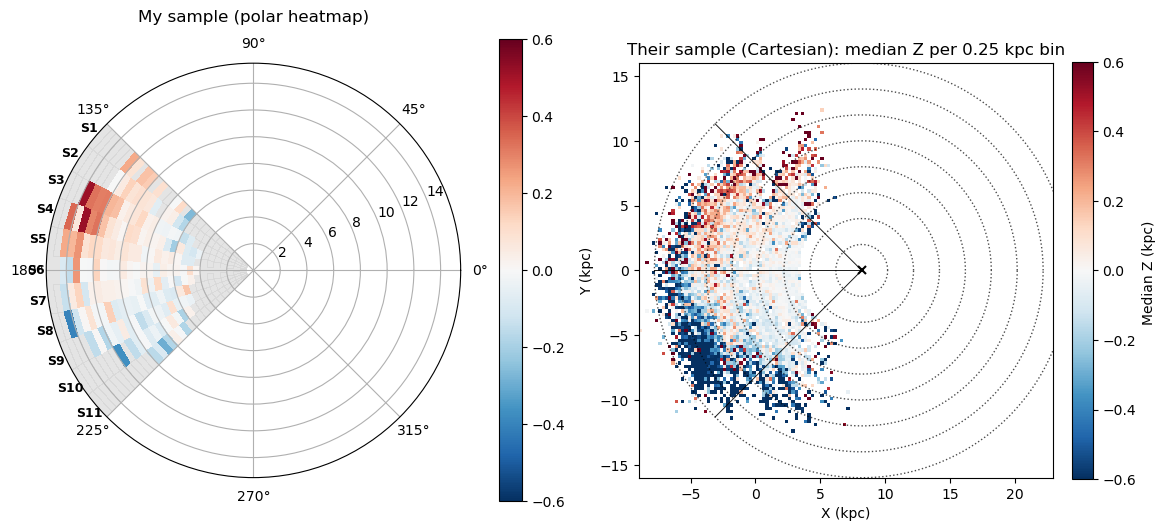

In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ASSUMES you ALREADY ran your polar heatmap code and have:
#   theta_edges   (len = n_th+1)
#   R_edges_kept  (len = n_r+1)
#   Zmap          (shape = (n_r, n_th))   <-- your polar value map
#   zlim          (float)                 <-- your polar color limits
#
# If your array names differ, change them in the "MY POLAR" block.
# ============================================================

# ============================================================
# THEIR DATA: load Poggio catalog + make median Z in XY bins
# ============================================================
path = "A199_data/catalog.dat.gz"
colnames = ["source_id", "glon_deg", "glat_deg", "dist_kpc", "edist_kpc", "plxcor_mas", "q_dist", "gmag"]
df = pd.read_csv(path, sep=r"\s+", header=None, names=colnames, comment="#")

m = (
    np.isfinite(df["glon_deg"]) &
    np.isfinite(df["glat_deg"]) &
    np.isfinite(df["dist_kpc"]) &
    (df["dist_kpc"] > 0)
)
df = df.loc[m].copy()

l = np.deg2rad(df["glon_deg"].to_numpy())
b = np.deg2rad(df["glat_deg"].to_numpy())
d = df["dist_kpc"].to_numpy()

# Sun-centered Cartesian (kpc)
X = d * np.cos(b) * np.cos(l)
Y = d * np.cos(b) * np.sin(l)
Z = d * np.sin(b)

def binned_median_xy(x, y, z, xedges, yedges, min_count=5):
    x = np.asarray(x); y = np.asarray(y); z = np.asarray(z)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(z)
    x = x[ok]; y = y[ok]; z = z[ok]

    nx = len(xedges) - 1
    ny = len(yedges) - 1

    ix = np.searchsorted(xedges, x, side="right") - 1
    iy = np.searchsorted(yedges, y, side="right") - 1
    inside = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)

    ix = ix[inside]; iy = iy[inside]; z = z[inside]

    N = np.zeros((ny, nx), dtype=int)
    np.add.at(N, (iy, ix), 1)

    Zmed = np.full((ny, nx), np.nan, float)
    bins = [[[] for _ in range(nx)] for __ in range(ny)]
    for j, i, val in zip(iy, ix, z):
        bins[j][i].append(val)

    for j in range(ny):
        for i in range(nx):
            if N[j, i] >= min_count:
                Zmed[j, i] = np.median(bins[j][i])

    return Zmed, N

# Settings for THEIR panel (tweak as desired)
bin_kpc     = 0.25
min_per_bin = 2
xy_lim      = 16.0
vlim_their  = 0.30

xedges = np.arange(-xy_lim, xy_lim + bin_kpc, bin_kpc)
yedges = np.arange(-xy_lim, xy_lim + bin_kpc, bin_kpc)
Zmed, Nbin = binned_median_xy(X, Y, Z, xedges, yedges, min_count=min_per_bin)

print("Their stars used (finite l,b,d):", len(df))
# ============================================================
# PLOT BOTH: My polar heatmap (left) + Their Cartesian (right)
# ============================================================
fig = plt.figure(figsize=(13.5, 6.0))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.0], wspace=0.25)

# --------------------------
# LEFT: YOUR POLAR HEATMAP
# --------------------------
ax0 = fig.add_subplot(gs[0, 0], projection="polar")

ax0.set_theta_zero_location("E")
ax0.set_theta_direction(1)

cmap0 = plt.cm.RdBu_r.copy()
cmap0.set_bad(color="lightgray", alpha=0.6)

TH, RR = np.meshgrid(theta_edges, R_edges_kept)  # (n_r+1, n_th+1)
#---
pcm0 = ax0.pcolormesh(
    TH, RR, Zmap,
    shading="flat",
    cmap=cmap0,
    vmin=-zlim,
    vmax=+zlim
)
pcm_my = ax0.pcolormesh(
    TH, RR, Zmap,
    cmap=plt.cm.RdBu_r,
    vmin=-0.6,          # YOUR limits
    vmax=+0.6,
    shading="auto"
)

cbar_my = fig.colorbar(
    pcm_my,
    ax=ax0,
    fraction=0.05,
    pad=0.08
)
ax0.set_title("My sample (polar heatmap)", y=1.08)

# segment labels (optional; comment out if you don’t want)
theta_centers = 0.5 * (theta_edges[:-1] + theta_edges[1:])
r_label = R_edges_kept[-1] * 1.05
for j, th in enumerate(theta_centers):
    ax0.text(th, r_label, f"S{j+1}", ha="center", va="center", fontsize=9, weight="bold")

# --------------------------
# RIGHT: THEIR CARTESIAN MAP
# --------------------------
ax1 = fig.add_subplot(gs[0, 1])

cmap_match = plt.cm.RdBu_r  # SAME as your polar plot

im1 = ax1.imshow(
    Zmed,
    origin="lower",
    extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
    cmap=cmap_match,
    vmin=-vlim_their,
    vmax=+vlim_their,
    interpolation="nearest",
    aspect="equal"
)


ax1.set_xlim(-9, 23)
ax1.set_ylim(-xy_lim, xy_lim)
# -----------------------------
# Galactocentric circles
# -----------------------------
R0 = 8.2        # Sun–GC distance [kpc]
X_gc, Y_gc = +R0, 0.0

radii = [2,4,6,8,10, 12, 14, 16]  # same as Poggio et al.
theta = np.linspace(0, 2*np.pi, 600)

for R in radii:
    ax1.plot(
        X_gc + R * np.cos(theta),
        Y_gc + R * np.sin(theta),
        linestyle=":",
        color="black",
        lw=1.0,
        alpha=0.7
    )
ax1.plot(X_gc, Y_gc, marker="x", color="black", ms=6, mew=1.5)

# --- ONLY 3 radial lines: left edge, middle, right edge ---
phi_edges = np.array(theta_edges, float)   # (n_th+1,) in radians, same as your polar plot
phi0 = phi_edges[0]                        # first boundary
phi1 = phi_edges[-1]                       # last boundary
phi_mid = 0.5 * (phi0 + phi1)              # middle of the whole wedge

phi_draw = [phi0, phi_mid, phi1]

r_max = 16.0  # make this big enough to reach beyond your plot
for phi in phi_draw:
    x_line = X_gc + np.array([0.0, r_max]) * np.cos(phi)
    y_line = Y_gc + np.array([0.0, r_max]) * np.sin(phi)
    ax1.plot(x_line, y_line, color="k", lw=.7, alpha=0.9, zorder=1)


ax1.set_xlabel("X (kpc)")
ax1.set_ylabel("Y (kpc)")
ax1.set_title(f"Their sample (Cartesian): median Z per {bin_kpc:.2f} kpc bin")

# --------------------------
# One shared colorbar on the right
# (Note: polar is z_min, Cartesian is median Z, so label accordingly)
# If you want separate colorbars, tell me and I’ll split them.
# --------------------------

#cbar = fig.colorbar(im1, ax=[ax0, ax1], fraction=0.046, pad=0.04)
#cbar.set_label("Median Z (kpc)")
####
im_their = ax1.imshow(
    Zmed,
    origin="lower",
    extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
    cmap=plt.cm.RdBu_r,
    vmin=-0.60,          
    vmax=+0.60,
    interpolation="nearest",
    aspect="equal"
)

cbar_their = fig.colorbar(
    im_their,
    ax=ax1,
    fraction=0.046,
    pad=0.04
)
cbar_their.set_label("Median Z (kpc) ")

plt.subplots_adjust(wspace=.35)
plt.show()

Poggio stars used (finite l,b,d): 17030
Poggio polar bins with >= 5 stars: 237


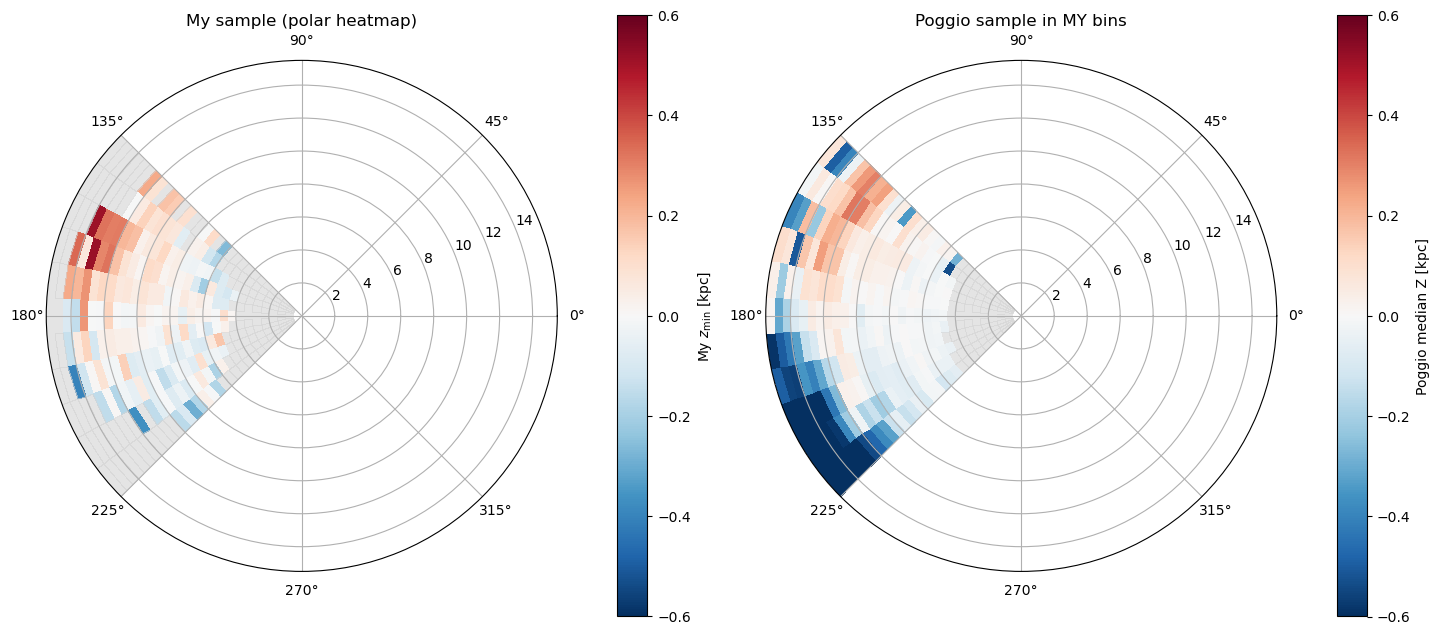

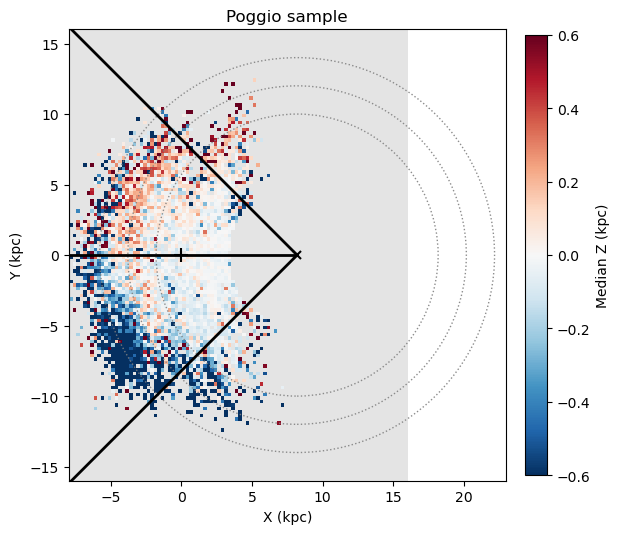

In [148]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# ============================================================
# SETTINGS
# ============================================================
poggio_path = "A199_data/catalog.dat.gz"

# Galactocentric distance of the Sun (kpc) for drawing GC-centered circles/rays
R0 = 8.2  # tweak if you want 8.122 etc.

# For the Poggio polar map color scaling (can be different from yours)
vlim_pog = 0.60          # e.g. paper-ish
min_per_bin_pog = 5      # tune: higher -> smoother, lower -> noisier

# Right-panel cartesian limits (tune)
xlimR = (-8, 23)
ylimR = (-16, 16)

# Galactocentric ring guides to draw on the right panel (kpc)
ring_radii = [10, 12, 14]

# Only THREE radial lines (example: middle + two edges of your wedge)
# We'll take: left edge, mid, right edge from theta_edges
# (This uses the same azimuth convention as your polar plot.)
theta_left  = float(theta_edges[0])
theta_right = float(theta_edges[-1])
theta_mid   = 0.5 * (theta_left + theta_right)
theta_lines = [theta_left, theta_mid, theta_right]

# ============================================================
# LOAD POGGIO CATALOG: (l,b,d) -> Sun-centered Cartesian X,Y,Z
# ============================================================
colnames = ["source_id", "glon_deg", "glat_deg", "dist_kpc", "edist_kpc", "plxcor_mas", "q_dist", "gmag"]
dfp = pd.read_csv(poggio_path, sep=r"\s+", header=None, names=colnames, comment="#")

m = np.isfinite(dfp["glon_deg"]) & np.isfinite(dfp["glat_deg"]) & np.isfinite(dfp["dist_kpc"]) & (dfp["dist_kpc"] > 0)
dfp = dfp.loc[m].copy()

l = np.deg2rad(dfp["glon_deg"].to_numpy())
b = np.deg2rad(dfp["glat_deg"].to_numpy())
d = dfp["dist_kpc"].to_numpy()

# Sun-centered Cartesian (kpc); with l=0 toward GC => GC near (R0, 0)
X = d * np.cos(b) * np.cos(l)
Y = d * np.cos(b) * np.sin(l)
Z = d * np.sin(b)

print("Poggio stars used (finite l,b,d):", len(dfp))

# ============================================================
# CONVERT TO GALACTOCENTRIC POLAR (R,phi) IN YOUR ANGLE CONVENTION
#   - Center at GC = (R0,0) in Sun-centered XY
#   - x_gc points from GC toward +X direction of your plot
# ============================================================
Xgc = X - R0
Ygc = Y

R = np.sqrt(Xgc**2 + Ygc**2)
phi = np.mod(np.arctan2(Ygc, Xgc), 2*np.pi)   # radians in [0,2pi)

# ============================================================
# BINNED MEDIAN IN (R,phi) USING YOUR (r_edges, theta_edges)
# ============================================================
def binned_median_polar(r, th, val, r_edges, th_edges, min_count=5):
    r = np.asarray(r); th = np.asarray(th); val = np.asarray(val)
    ok = np.isfinite(r) & np.isfinite(th) & np.isfinite(val)
    r = r[ok]; th = th[ok]; val = val[ok]

    nr = len(r_edges) - 1
    nth = len(th_edges) - 1

    ir = np.searchsorted(r_edges, r, side="right") - 1
    it = np.searchsorted(th_edges, th, side="right") - 1

    inside = (ir >= 0) & (ir < nr) & (it >= 0) & (it < nth)
    ir = ir[inside]; it = it[inside]; val = val[inside]

    N = np.zeros((nr, nth), dtype=int)
    np.add.at(N, (ir, it), 1)

    # collect values per bin for robust medians
    bins = [[[] for _ in range(nth)] for __ in range(nr)]
    for rr, tt, vv in zip(ir, it, val):
        bins[rr][tt].append(vv)

    Vmed = np.full((nr, nth), np.nan, float)
    for rr in range(nr):
        for tt in range(nth):
            if N[rr, tt] >= min_count:
                Vmed[rr, tt] = np.median(bins[rr][tt])

    return Vmed, N

r_edges = R_edges_kept
th_edges = theta_edges

Zmed_pog_polar, N_pog_polar = binned_median_polar(R, phi, Z, r_edges, th_edges, min_count=min_per_bin_pog)
print(f"Poggio polar bins with >= {min_per_bin_pog} stars:", int(np.sum(np.isfinite(Zmed_pog_polar))))

# ============================================================
# PLOT: LEFT = YOUR HEATMAP, RIGHT = POGGIO IN YOUR BINS
#   Two separate colorbars
# ============================================================
cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color="lightgray", alpha=0.6)

fig = plt.figure(figsize=(14.5, 6.8))

# ---- Left: your heatmap
axL = fig.add_subplot(1, 2, 1, projection="polar")
axL.set_theta_zero_location("E")
axL.set_theta_direction(1)

TH, RR = np.meshgrid(theta_edges, R_edges_kept)
pcmL = axL.pcolormesh(TH, RR, Zmap, shading="flat", cmap=cmap, vmin=-zlim, vmax=+zlim)
axL.set_title("My sample (polar heatmap)")

cbL = fig.colorbar(pcmL, ax=axL, pad=0.10, fraction=0.05)
cbL.set_label(r"My $z_{\min}$ [kpc]")

# ---- Right: Poggio rebinned into your polar bins
axP = fig.add_subplot(1, 2, 2, projection="polar")
axP.set_theta_zero_location("E")
axP.set_theta_direction(1)

TH2, RR2 = np.meshgrid(theta_edges, R_edges_kept)
pcmP = axP.pcolormesh(TH2, RR2, Zmed_pog_polar, shading="flat", cmap=cmap, vmin=-vlim_pog, vmax=+vlim_pog)
axP.set_title(f"Poggio sample in MY bins")

cbP = fig.colorbar(pcmP, ax=axP, pad=0.10, fraction=0.05)
cbP.set_label("Poggio median Z [kpc]")

plt.tight_layout()
plt.show()

# ============================================================
# OPTIONAL: If you ALSO want the Sun-centered CARTESIAN panel version
# with galactocentric circles and ONLY 3 wedge lines, here it is:
# ============================================================
bin_kpc = 0.25
xy_lim = 16.0

xedges = np.arange(-xy_lim, xy_lim + bin_kpc, bin_kpc)
yedges = np.arange(-xy_lim, xy_lim + bin_kpc, bin_kpc)

def binned_median_xy(x, y, z, xedges, yedges, min_count=5):
    x = np.asarray(x); y = np.asarray(y); z = np.asarray(z)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(z)
    x = x[ok]; y = y[ok]; z = z[ok]

    nx = len(xedges) - 1
    ny = len(yedges) - 1

    ix = np.searchsorted(xedges, x, side="right") - 1
    iy = np.searchsorted(yedges, y, side="right") - 1
    inside = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)

    ix = ix[inside]; iy = iy[inside]; z = z[inside]

    N = np.zeros((ny, nx), dtype=int)
    np.add.at(N, (iy, ix), 1)

    bins = [[[] for _ in range(nx)] for __ in range(ny)]
    for j, i, val in zip(iy, ix, z):
        bins[j][i].append(val)

    Zmed = np.full((ny, nx), np.nan, float)
    for j in range(ny):
        for i in range(nx):
            if N[j, i] >= min_count:
                Zmed[j, i] = np.median(bins[j][i])
    return Zmed, N

Zmed_xy, Nxy = binned_median_xy(X, Y, Z, xedges, yedges, min_count=2)

fig, axR = plt.subplots(figsize=(6.3, 6.0))
im = axR.imshow(
    Zmed_xy,
    origin="lower",
    extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
    cmap=cmap,
    vmin=-.6, vmax=+.6,
    interpolation="nearest",
    aspect="equal"
)

# Sun cross at (0,0)
axR.plot(0, 0, marker="+", color="black", ms=10, mew=1.5)

# GC marker at (R0, 0) in Sun-centered XY
axR.plot(R0, 0, marker="x", color="black", ms=6, mew=1.5)

# Galactocentric circles centered at GC=(R0,0)
for rr in ring_radii:
    axR.add_patch(Circle((R0, 0), rr, fill=False, ls=":", lw=1.0, ec="gray", alpha=0.9))

# ONLY three radial lines from GC using your wedge angles
# Convert each theta (polar) into a ray in Cartesian centered at GC.
ray_len = 40.0
for th in theta_lines:
    x2 = R0 + ray_len * np.cos(th)
    y2 = 0  + ray_len * np.sin(th)
    axR.plot([R0, x2], [0, y2], color="black", lw=2)

axR.set_xlim(*xlimR)
axR.set_ylim(*ylimR)
axR.set_xlabel("X (kpc)")
axR.set_ylabel("Y (kpc)")
axR.set_title("Poggio sample")

cbar = fig.colorbar(im, ax=axR, fraction=0.046, pad=0.04)
cbar.set_label("Median Z (kpc)")

plt.tight_layout()
plt.show()
